# FGM Risk Incidence, Kenya, all survey rounds (V2)

Same analysis as V1 (`V1/01_Notebooks/FGM_Risk_Incidence.ipynb`, DHS 2022 only) applied to
every round with women's age at cutting: DHS 1998, 2008–09, 2014 and 2022 for women's own
histories, and the two full-roster rounds (DHS 2014, 2022) for daughters. DHS 2003 did not ask
age at cutting and Kenya's MICS are subnational, so risk incidence uses these four DHS rounds.
Run `00_EDA_All_Rounds.ipynb` first.

In Kenya most cutting happens at ages 5–15 (only 2–4% of cut women report cutting before
age 5), so the by-round trend and the sensitivity checks use the risk of being cut **by age
15** for women's own reports and **by age 10** when comparing with mothers' reports for
daughters, who are observed only to age 14.

Differences from V1, besides the added rounds:

1. **Definitions.** Cutting "during infancy" is age 0, and never-heard women and their
   daughters are uncut (see the EDA notebook).
2. **Pooling.** Rounds are pooled by birth cohort. Each survey keeps its own clusters and
   strata, and weights are rescaled to mean one within each survey.
3. **Computation.** Person-years are aggregated within survey cluster before modelling,
   which gives the same estimates and design-based variances as one row per person-year.
4. **Kaplan–Meier throughout.** Direct regional estimates use Kaplan–Meier point estimates
   with linearized standard errors; V1 used the Aalen estimator for direct cells.
5. **By-round check.** Section 13B compares the cohort trend between rounds.
6. **Age at cutting not reported exactly.** DHS "during infancy" answers are spread over
   ages 0–4, and "don't know", missing or inconsistent ages over ages 0 to the current age,
   using the age distribution of exact reporters in the same survey and birth cohort (see
   the EDA notebook, section 7.1). Such cases appear as fractional records (`age_share`)
   that keep the respondent's survey weight; nothing is dropped except DHS 2003 women,
   whose survey did not ask age at cutting.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"

project_root <- if (dir.exists("../02_Data")) ".." else "."
analysis_dir <- file.path(project_root, "02_Data", "processed", country_iso3, "analysis")
output_dir <- file.path(project_root, "03_Outputs", country_iso3, "Risk")
dirs <- list(
  km = file.path(output_dir, "01_Kaplan_Meier"),
  hazard = file.path(output_dir, "02_Hazard_Model"),
  direct = file.path(output_dir, "03_Direct_and_Smoothed_Estimates"),
  maps = file.path(output_dir, "04_Risk_Maps"),
  covariate = file.path(output_dir, "05_Covariate_Adjusted_Maps"),
  trends = file.path(output_dir, "06_Trends"),
  validation = file.path(output_dir, "07_Validation"),
  sensitivity = file.path(output_dir, "08_Sensitivity_Analysis")
)
for (d in dirs) dir.create(d, recursive = TRUE, showWarnings = FALSE)

shapefile_path <- file.path(project_root, "02_Data", "processed", "KEN", "boundaries", "KEN_provinces.shp")
region_var_shapefile <- "PROVINCE"
# Region keys as in the harmonized data: upper case, hyphens as spaces ("CENTRE EST").
standardize_region <- function(x) toupper(as.character(x)) |> stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()

max_age_years <- 49L
age_band_cutpoints <- c(0, 5, 10, 15, 20, 25)
age_band_levels <- paste0(head(age_band_cutpoints, -1), "-", age_band_cutpoints[-1])

run_spatial_model <- file.exists(shapefile_path)
run_change_point <- TRUE
run_ml_crosscheck <- TRUE

options(repr.plot.width = 13, repr.plot.height = 8, width = 200)
cat("Configured for:", country_name, "| outputs:", normalizePath(output_dir, mustWork = FALSE), "\n")

Configured for: Kenya | outputs: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Risk 


## 1. Setup and packages

In [2]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(survey)
  library(survival)
  library(data.table)
  library(sf)
  library(spdep)
  library(mgcv)
})
options(survey.lonely.psu = "adjust")
set.seed(20260101)

## 2. Load prepared data

`KEN_fgm_events.rds` holds one time-to-event record per woman (own history) or daughter
(mother's report): `fgm_event` is 1 if cut and `time` is the age at cutting, otherwise
`time` is the current age (women capped at 49).

In [3]:
fgm_events <- readRDS(file.path(analysis_dir, paste0(country_iso3, "_fgm_events.rds"))) |>
  dplyr::mutate(birth_cohort = factor(birth_cohort, levels = sort(unique(birth_cohort))),
                survey_id = factor(survey_id, levels = unique(survey_id[order(survey_type, round_year)])))

cat("Records:", nrow(fgm_events), "\n")
IRdisplay::display(as.data.frame(
  fgm_events |> dplyr::count(record_type, survey_id, wt = age_share) |>
    tidyr::pivot_wider(names_from = record_type, values_from = n, values_fill = 0)))
cat("Histories:", round(sum(fgm_events$age_share)), "| records (fractional rows for estimated ages):", nrow(fgm_events), "
")

Records: 82110 


survey_id,daughter,self
<fct>,<dbl>,<dbl>
DHS 2014,13189,14734
DHS 2022,13525,16902
DHS 1998,0,7873
DHS 2008,0,8433


Histories: 74656 | records (fractional rows for estimated ages): 82110 


## 3. Cohort coverage across rounds

Records by birth cohort and round. Pooling uses every round in which a cohort appears;
older cohorts come only from early rounds and the youngest cohorts only from late rounds.

In [4]:
coverage <- fgm_events |>
  dplyr::count(record_type, birth_cohort, survey_id, wt = age_share) |>
  dplyr::mutate(n = round(n)) |>
  tidyr::pivot_wider(names_from = survey_id, values_from = n, values_fill = 0) |>
  dplyr::arrange(record_type, birth_cohort)
readr::write_csv(coverage, file.path(dirs$km, paste0(country_iso3, "_records_by_cohort_and_round.csv")))
IRdisplay::display(as.data.frame(coverage))

record_type,birth_cohort,DHS 2014,DHS 2022,DHS 1998,DHS 2008
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
daughter,1995 to 1999,211,0,0,0
daughter,2000 to 2004,3817,0,0,0
daughter,2005 to 2009,4762,2182,0,0
daughter,2010 to 2014,4399,4304,0,0
daughter,2015 to 2019,0,4750,0,0
daughter,2020 to 2024,0,2289,0,0
self,1945 to 1949,0,0,169,0
self,1950 to 1954,0,0,545,0
self,1955 to 1959,0,0,778,99


## 4. The FGM event

In [5]:
IRdisplay::display(as.data.frame(fgm_events |> dplyr::count(record_type, fgm_event, age_source, wt = age_share) |>
  dplyr::mutate(n = round(n))))

record_type,fgm_event,age_source,n
<chr>,<int>,<chr>,<dbl>
daughter,0,not cut,25286
daughter,1,exact age reported,1404
daughter,1,unknown age (spread over 0 to current age),24
self,0,not cut,34240
self,1,during infancy (spread over 0-4),145
self,1,exact age reported,13214
self,1,unknown age (spread over 0 to current age),343


## 5. Person-years and design-based Kaplan–Meier

Each record contributes one person-year per completed year of life up to its event or
censoring age. Person-years are summed within survey cluster and analysis cell; the
Kaplan–Meier survival is the product of weighted annual hazards, and its standard error
is the Taylor linearization from cluster totals (validated against `survey::svyby` with
`svycontrast` and against `svykm()` during development; identical to machine precision).

In [6]:
suppressPackageStartupMessages(library(data.table))

# One row per completed year of life up to the event or censoring age, aggregated
# within survey cluster and the requested grouping variables.
aggregate_person_years <- function(events, group_vars, max_age = 49L) {
  dt <- data.table::as.data.table(events)[, .row := .I]
  last_age <- pmin(floor(dt$time), max_age)
  idx <- rep.int(dt$.row, last_age + 1L)
  age_year <- sequence(last_age + 1L) - 1L
  py <- data.table::data.table(.row = idx, age_year = age_year)
  py[, event := as.integer(age_year == floor(dt$time[.row]) & dt$fgm_event[.row] == 1L)]
  keep <- unique(c("cluster", "strata", group_vars))
  # Records whose age at cutting was spread over several ages carry fractional shares;
  # unweighted counts sum those shares so each person counts once.
  share <- if ("age_share" %in% names(dt)) dt$age_share[py$.row] else 1
  py <- cbind(py, dt[py$.row, ..keep], weight = dt$weight[py$.row], share = share)
  py[, .(w_risk = sum(weight), w_event = sum(weight * event), n_risk = sum(share), n_event = sum(share * event)),
     by = c(keep, "age_year")]
}

# Kaplan-Meier conditional band risk 1 - S(hi)/S(lo) per domain, with a Taylor-
# linearized standard error of log S from PSU totals (stratified, with replacement;
# single-PSU strata centred on the overall PSU mean, as survey.lonely.psu = "adjust").
km_band_risk <- function(py, domain_vars, cutpoints, followup, design_psus) {
  py <- data.table::as.data.table(py)
  hz <- py[, .(E = sum(w_event), R = sum(w_risk)), by = c(domain_vars, "age_year")]
  hz[, h := E / R]
  bands <- data.table::data.table(lo = head(cutpoints, -1), hi = cutpoints[-1])
  bands[, age_band := paste0(lo, "-", hi)]
  out <- list()
  for (b in seq_len(nrow(bands))) {
    lo <- bands$lo[b]; hi <- bands$hi[b]
    ages <- if (lo == 0) 0:hi else (lo + 1):hi
    hb <- hz[age_year %in% ages]
    est <- hb[, .(log_surv = sum(log1p(-pmin(h, 1 - 1e-12))), n_ages = .N), by = domain_vars]
    # PSU-level influence values for log S.
    z <- merge(py[age_year %in% ages], hb[, c(domain_vars, "age_year", "h", "R"), with = FALSE],
               by = c(domain_vars, "age_year"))
    z[, u := -(w_event - h * w_risk) / (R * (1 - pmin(h, 1 - 1e-12)))]
    zc <- z[, .(z = sum(u)), by = c(domain_vars, "strata", "cluster")]
    var_dt <- domain_variance(zc, domain_vars, design_psus)
    res <- merge(est, var_dt, by = domain_vars, all.x = TRUE)
    res[, `:=`(age_band = bands$age_band[b], lo = lo, hi = hi, n_ages_needed = length(ages))]
    out[[b]] <- res
  }
  res <- data.table::rbindlist(out, use.names = TRUE)
  res <- merge(res, data.table::as.data.table(followup), by = domain_vars, all.x = TRUE)
  res[, supported := max_observed >= hi & n_ages == n_ages_needed]
  res[, se_log := sqrt(pmax(var_log, 0))]
  res[, `:=`(risk = data.table::fifelse(supported, 1 - exp(log_surv), NA_real_),
             lower_ci = data.table::fifelse(supported, 1 - pmin(1, exp(log_surv + 1.96 * se_log)), NA_real_),
             upper_ci = data.table::fifelse(supported, 1 - exp(log_surv - 1.96 * se_log), NA_real_))]
  # Risk to the last observed age for bands a cohort has not completed.
  res[]
}

# Stratified with-replacement variance of a domain total from PSU totals, counting
# PSUs with zero contribution within each stratum of the full design.
domain_variance <- function(zc, domain_vars, design_psus) {
  dp <- data.table::as.data.table(design_psus)            # strata, n_h
  s <- zc[, .(sum_z = sum(z), sum_z2 = sum(z^2)), by = c(domain_vars, "strata")]
  s <- merge(s, dp, by = "strata")
  grand <- zc[, .(total = sum(z)), by = domain_vars]
  n_psu_total <- sum(dp$n_h)
  s <- merge(s, grand, by = domain_vars)
  s[, contrib := data.table::fifelse(
    n_h > 1,
    n_h / (n_h - 1) * (sum_z2 - sum_z^2 / n_h),
    # Single-PSU stratum: deviation from the overall mean PSU total.
    (sum_z - total / n_psu_total)^2)]
  s[, .(var_log = sum(contrib)), by = domain_vars]
}

In [7]:
design_psus <- lapply(split(fgm_events, fgm_events$record_type), function(d)
  data.table::as.data.table(d)[, .(cluster = unique(cluster)), by = strata][, .(n_h = .N), by = strata])

py_cohort <- lapply(split(fgm_events, fgm_events$record_type), aggregate_person_years,
                    group_vars = c("region", "birth_cohort", "survey_id", "survey_type"), max_age = max_age_years)
cat("Aggregated person-year cells:", vapply(py_cohort, nrow, integer(1)), "\n")
cat("Person-years represented:", vapply(py_cohort, function(p) sum(p$n_risk), numeric(1)), "\n")

Aggregated person-year cells: 82605 607543 


Person-years represented: 199272.2 1156680 


## 6. Kaplan–Meier baseline

Survey-weighted Kaplan–Meier curves by birth cohort, pooling all rounds. Each curve stops
at the oldest age observed for that cohort.

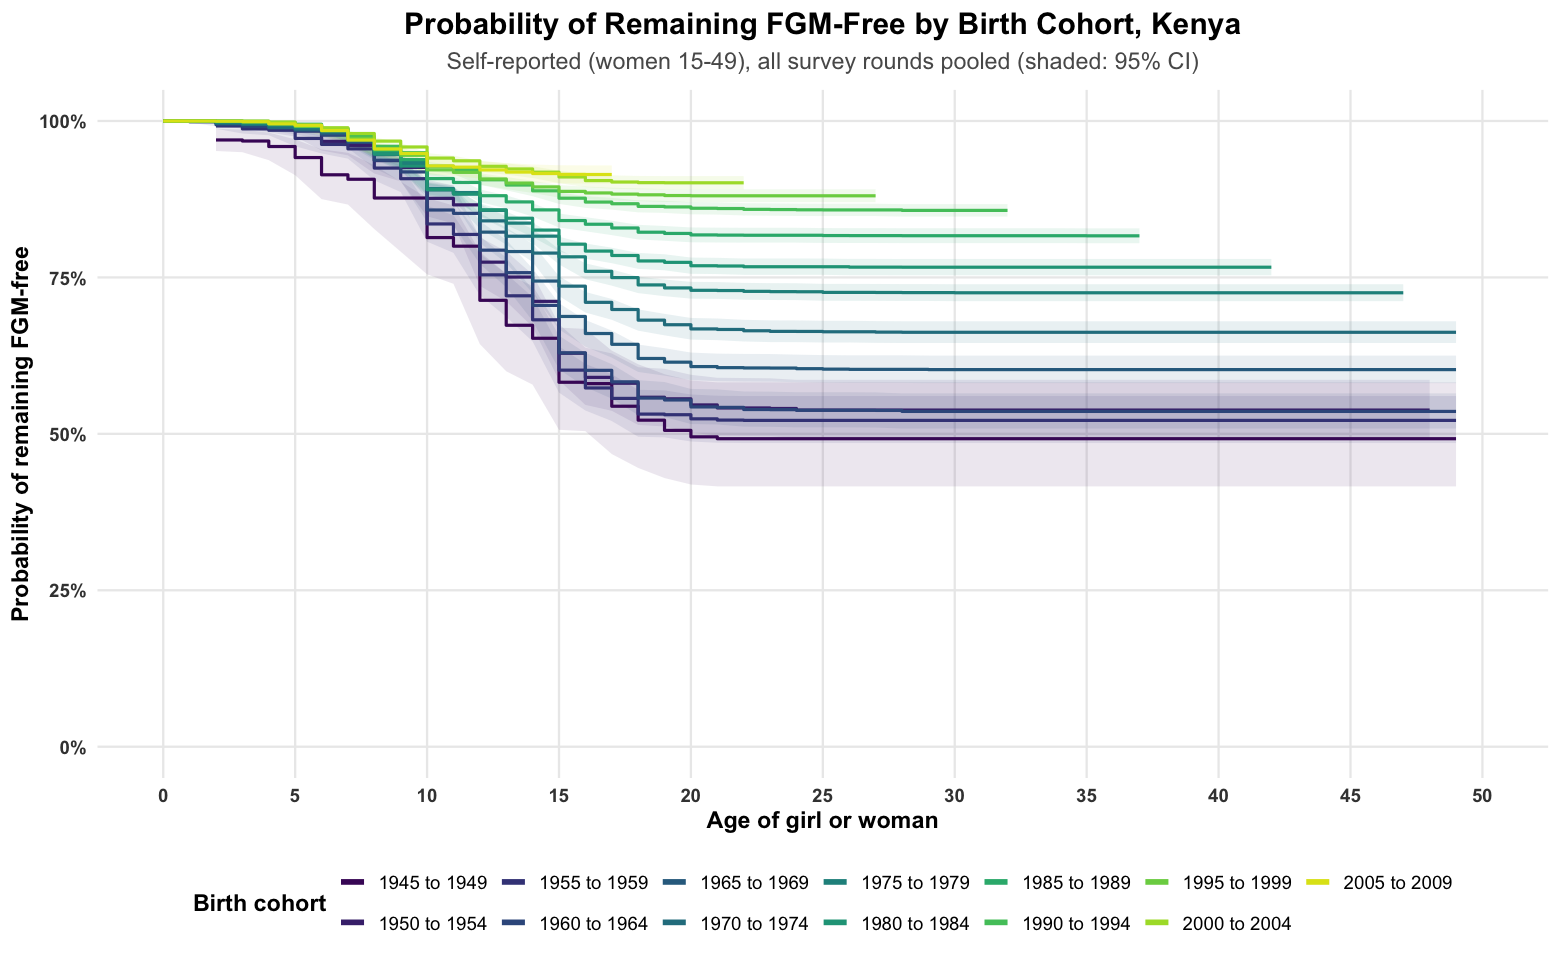

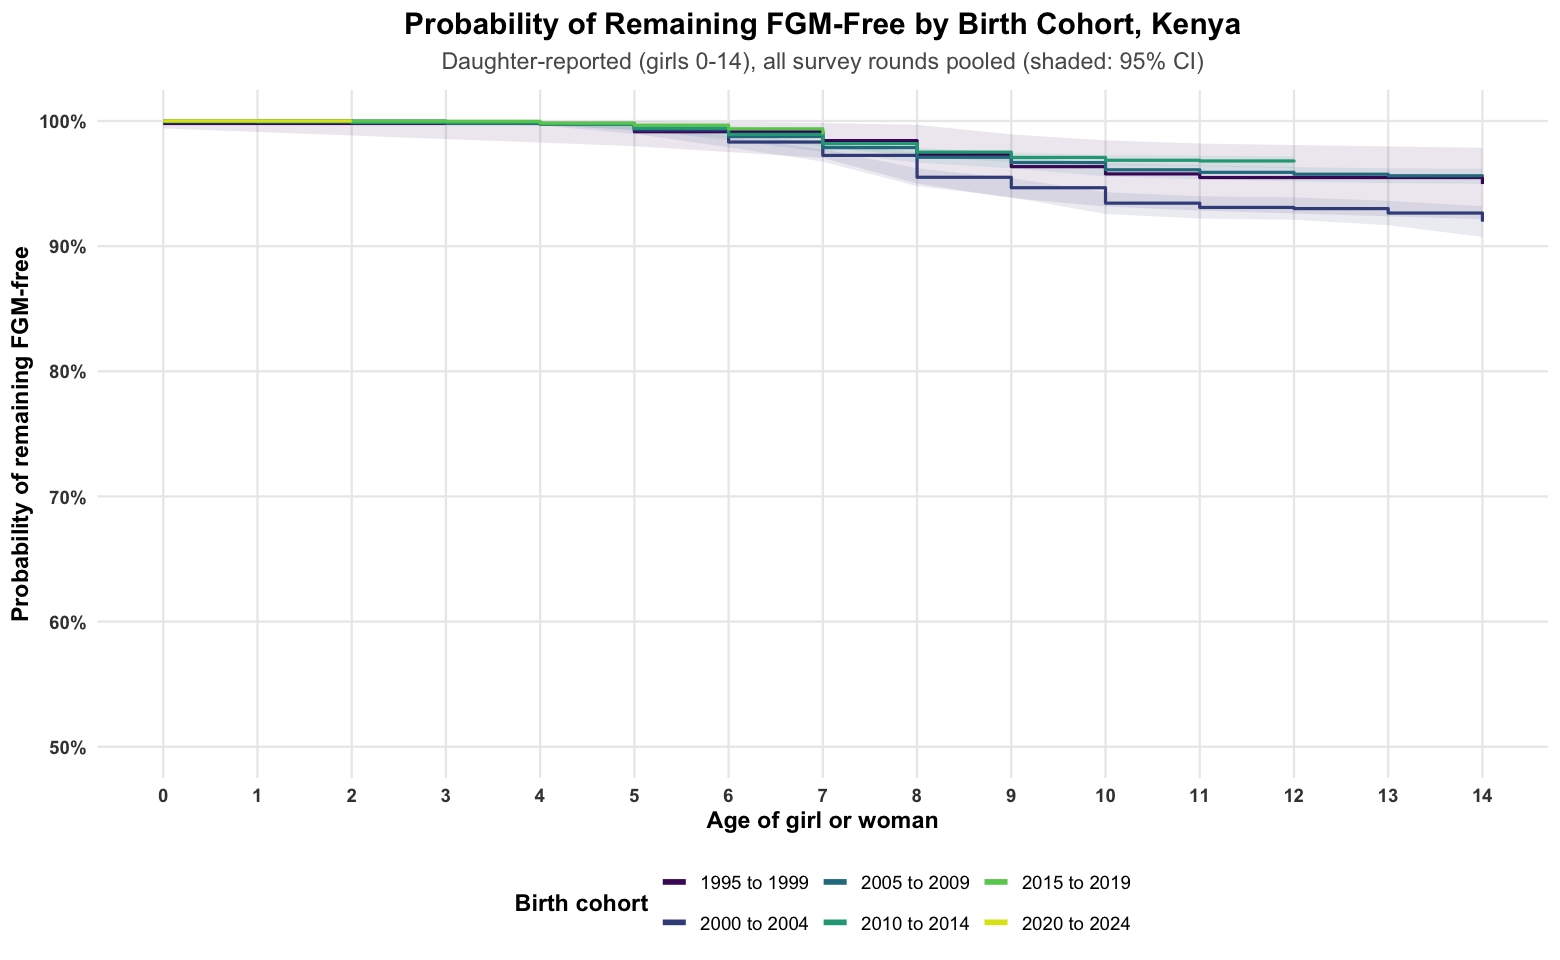

In [8]:
build_km_plot <- function(plot_data, subtitle_label, xlim_max, break_by, file_suffix, y_min) {
  plot_data <- plot_data |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))
  km_fit <- survival::survfit(survival::Surv(time, fgm_event) ~ birth_cohort, data = plot_data, weights = weight)
  km_tidy <- broom::tidy(km_fit) |>
    dplyr::mutate(birth_cohort = stringr::str_remove(strata, "^birth_cohort="))
  n_cohorts <- nlevels(plot_data$birth_cohort)
  p <- ggplot2::ggplot(km_tidy, ggplot2::aes(time, estimate, color = birth_cohort, fill = birth_cohort)) +
    ggplot2::geom_ribbon(ggplot2::aes(ymin = conf.low, ymax = conf.high), alpha = 0.10, color = NA) +
    ggplot2::geom_step(linewidth = 0.9) +
    ggplot2::scale_color_manual(values = viridisLite::viridis(n_cohorts, begin = 0.05, end = 0.95)) +
    ggplot2::scale_fill_manual(values = viridisLite::viridis(n_cohorts, begin = 0.05, end = 0.95), guide = "none") +
    ggplot2::scale_x_continuous(breaks = seq(0, xlim_max, by = break_by), limits = c(0, xlim_max)) +
    ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(y_min, 1)) +
    ggplot2::labs(title = paste("Probability of Remaining FGM-Free by Birth Cohort,", country_name),
                  subtitle = paste0(subtitle_label, ", all survey rounds pooled (shaded: 95% CI)"),
                  x = "Age of girl or woman", y = "Probability of remaining FGM-free", color = "Birth cohort") +
    ggplot2::theme_minimal(base_size = 14) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 18, hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35", margin = ggplot2::margin(b = 10)),
                   axis.title = ggplot2::element_text(face = "bold"),
                   axis.text = ggplot2::element_text(face = "bold", color = "grey25"),
                   panel.grid.minor = ggplot2::element_blank(),
                   legend.position = "bottom", legend.title = ggplot2::element_text(face = "bold")) +
    ggplot2::guides(color = ggplot2::guide_legend(nrow = 2, override.aes = list(linewidth = 1.6)))
  print(p)
  ggplot2::ggsave(file.path(dirs$km, paste0(country_iso3, "_kaplan_meier_", file_suffix, ".png")),
                  p, width = 14, height = 9, dpi = 300, bg = "white")
  km_fit
}

km_fit_self <- build_km_plot(fgm_events |> dplyr::filter(record_type == "self"),
                             "Self-reported (women 15-49)", 50, 5, "self", 0)
km_fit_daughter <- build_km_plot(fgm_events |> dplyr::filter(record_type == "daughter"),
                                 "Daughter-reported (girls 0-14)", 14, 1, "daughter", 0.5)

## 7. Estimate FGM incidence risk

In [9]:
reference_ages <- c(1, 2, 5, 8, 10, 15, 18)

build_risk_table <- function(km_fit, record_type_label) {
  risk_table <- summary(km_fit, times = reference_ages, extend = TRUE)
  tibble::tibble(
    birth_cohort = stringr::str_remove(as.character(risk_table$strata), "^birth_cohort="),
    age = risk_table$time, n_at_risk = risk_table$n.risk,
    fgm_risk = 1 - risk_table$surv, lower_ci = 1 - risk_table$upper, upper_ci = 1 - risk_table$lower,
    record_type = record_type_label
  )
}
risk_by_age <- dplyr::bind_rows(build_risk_table(km_fit_self, "self"), build_risk_table(km_fit_daughter, "daughter"))
# Ages beyond a cohort's follow-up are carried forward by survfit; mark them.
followup_cohort <- fgm_events |> dplyr::group_by(record_type, birth_cohort = as.character(birth_cohort)) |>
  dplyr::summarise(max_observed = max(time), .groups = "drop")
risk_by_age <- risk_by_age |>
  dplyr::left_join(followup_cohort, by = c("record_type", "birth_cohort")) |>
  dplyr::mutate(beyond_followup = age > max_observed)
readr::write_csv(risk_by_age, file.path(dirs$km, paste0(country_iso3, "_km_risk_by_age.csv")))

for (rt in c("self", "daughter")) {
  cat("\n=====", rt, "reported: cumulative FGM risk by age and birth cohort (observed ages only) =====\n")
  IRdisplay::display(as.data.frame(
    risk_by_age |> dplyr::filter(record_type == rt, !beyond_followup) |>
      dplyr::mutate(dplyr::across(c(fgm_risk, lower_ci, upper_ci), ~ scales::percent(.x, accuracy = 0.1))) |>
      dplyr::select(birth_cohort, age, fgm_risk, lower_ci, upper_ci)))
}

birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
1945 to 1949,1,0.0%,0.0%,0.0%
1945 to 1949,2,3.0%,1.2%,4.8%
1945 to 1949,5,5.8%,2.9%,8.7%
1945 to 1949,8,12.3%,7.1%,17.3%
1945 to 1949,10,18.6%,12.3%,24.5%
1945 to 1949,15,41.8%,33.0%,49.4%
1945 to 1949,18,47.8%,38.9%,55.4%
1950 to 1954,1,0.0%,0.0%,0.0%
1950 to 1954,2,0.7%,0.4%,1.1%


birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
1995 to 1999,1,0.2%,0.0%,0.6%
1995 to 1999,2,0.2%,0.0%,0.6%
1995 to 1999,5,0.9%,0.0%,2.0%
1995 to 1999,8,2.7%,0.3%,5.0%
1995 to 1999,10,4.2%,1.5%,6.8%
2000 to 2004,1,0.0%,0.0%,0.0%
2000 to 2004,2,0.0%,0.0%,0.1%
2000 to 2004,5,0.7%,0.4%,1.0%
2000 to 2004,8,4.5%,3.8%,5.2%



===== self reported: cumulative FGM risk by age and birth cohort (observed ages only) =====

===== daughter reported: cumulative FGM risk by age and birth cohort (observed ages only) =====


## 8. Discrete-time hazard model

Survey-weighted logistic regression on annual person-time, with covariates fitted jointly.
Age enters as groups (0–4, 5–9, 10–14, 15+). Person-years are summed within cluster and
covariate cell and modelled as weighted proportions; this reproduces the person-year
estimating equations and cluster-based standard errors exactly. The few records without
ethnicity are excluded from this model. All risk records are DHS, so no survey-programme
term is needed. V1's unweighted Cox frailty model is not repeated: its cohort
coefficients were degenerate in V1 and it does not scale to the pooled data.

In [10]:
hazard_cells <- lapply(split(fgm_events, fgm_events$record_type), function(d) {
  py <- aggregate_person_years(d |> dplyr::filter(!is.na(ethnicity)),
                               group_vars = c("region", "urban_rural", "ethnicity", "birth_cohort", "survey_type", "record_type"),
                               max_age = max_age_years)
  py[, age_group := cut(age_year, breaks = c(0, 5, 10, 15, Inf), right = FALSE, labels = c("0-4", "5-9", "10-14", "15+"))]
  py[, .(w_risk = sum(w_risk), w_event = sum(w_event)),
     by = .(cluster, strata, region, urban_rural, ethnicity, birth_cohort, survey_type, record_type, age_group)]
})
hazard_data <- data.table::rbindlist(hazard_cells) |>
  dplyr::mutate(prop = w_event / w_risk, birth_cohort = droplevels(factor(birth_cohort)),
                ethnicity = stats::relevel(factor(ethnicity), ref = "kikuyu"))

hazard_design <- survey::svydesign(ids = ~cluster, strata = ~strata, weights = ~w_risk,
                                   data = hazard_data, nest = TRUE)
# Survey programme enters only when both DHS and MICS histories are present.
hazard_terms <- c("age_group", "birth_cohort", "urban_rural", "region", "ethnicity",
                  if (dplyr::n_distinct(hazard_data$survey_type) > 1) "survey_type", "record_type")
hazard_model_design_based <- survey::svyglm(
  stats::reformulate(hazard_terms, response = "prop"),
  design = hazard_design, family = quasibinomial()
)
hazard_coefficients <- tibble::as_tibble(summary(hazard_model_design_based)$coefficients, rownames = "term") |>
  dplyr::rename(estimate = Estimate, se = `Std. Error`, p_value = `Pr(>|t|)`) |>
  dplyr::mutate(odds_ratio = exp(estimate), or_lower = exp(estimate - 1.96 * se), or_upper = exp(estimate + 1.96 * se))
readr::write_csv(hazard_coefficients, file.path(dirs$hazard, paste0(country_iso3, "_hazard_model_coefficients.csv")))

cat("Cells:", nrow(hazard_data), "| person-years (weighted):", round(sum(hazard_data$w_risk)), "\n")
IRdisplay::display(as.data.frame(hazard_coefficients |> dplyr::filter(!grepl("^region", term)) |>
  dplyr::mutate(dplyr::across(where(is.numeric), ~ signif(.x, 3)))))

Cells: 125789 | person-years (weighted): 1390682 


term,estimate,se,t value,p_value,odds_ratio,or_lower,or_upper
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-7.0000,0.2130,-32.800,1.680000e-207,9.15e-04,6.03e-04,1.39e-03
age_group5-9,2.6000,0.0820,31.700,5.740000e-196,1.35e+01,1.15e+01,1.58e+01
age_group10-14,3.9500,0.0932,42.300,5.570096e-320,5.17e+01,4.30e+01,6.20e+01
age_group15+,2.9400,0.1040,28.200,3.210000e-159,1.90e+01,1.55e+01,2.33e+01
birth_cohort1950 to 1954,0.1230,0.1970,0.621,5.350000e-01,1.13e+00,7.68e-01,1.66e+00
birth_cohort1955 to 1959,-0.1290,0.1840,-0.701,4.830000e-01,8.79e-01,6.13e-01,1.26e+00
birth_cohort1960 to 1964,-0.1740,0.1810,-0.963,3.350000e-01,8.40e-01,5.89e-01,1.20e+00
birth_cohort1965 to 1969,-0.3920,0.1790,-2.190,2.880000e-02,6.76e-01,4.76e-01,9.60e-01
birth_cohort1970 to 1974,-0.6310,0.1800,-3.500,4.640000e-04,5.32e-01,3.74e-01,7.57e-01


## 9. Cohort and trend smoothing

Penalized splines for birth cohort and single-year age, adjusted for residence, region and
reporting source, fitted on person-years aggregated by those variables.

In [11]:
cohort_numeric <- data.table::rbindlist(lapply(split(fgm_events, fgm_events$record_type), aggregate_person_years,
                                               group_vars = c("region", "urban_rural", "birth_cohort", "record_type"),
                                               max_age = max_age_years))
cohort_numeric <- cohort_numeric[, .(w_risk = sum(w_risk), w_event = sum(w_event)),
                                 by = .(region, urban_rural, birth_cohort, record_type, age_year)] |>
  dplyr::mutate(cohort_mid = as.numeric(substr(as.character(birth_cohort), 1, 4)) + 2,
                record_type = factor(record_type), region = factor(region),
                urban_rural = factor(urban_rural), prop = w_event / w_risk)

trend_model <- mgcv::bam(
  prop ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", k = 10) + urban_rural + region + record_type,
  family = quasibinomial(), weights = w_risk / mean(w_risk), data = cohort_numeric
)
summary(trend_model)$s.table

,edf,Ref.df,F,p-value
s(cohort_mid),3.225144,3.939338,195.2320,0
s(age_year),5.618859,6.210516,285.5798,0


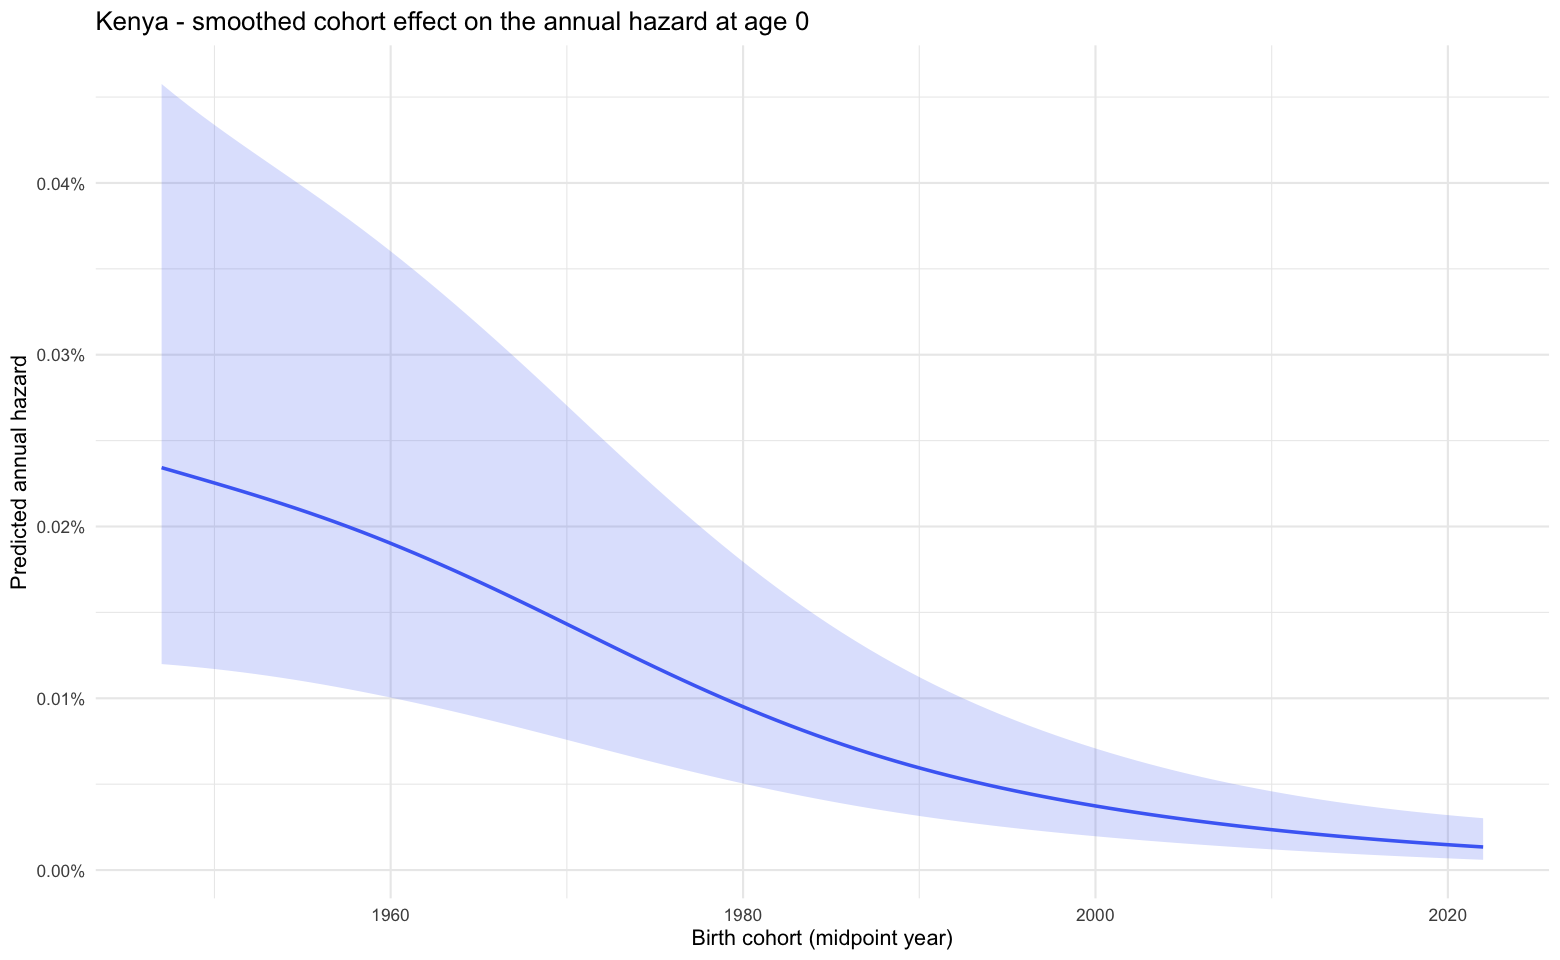

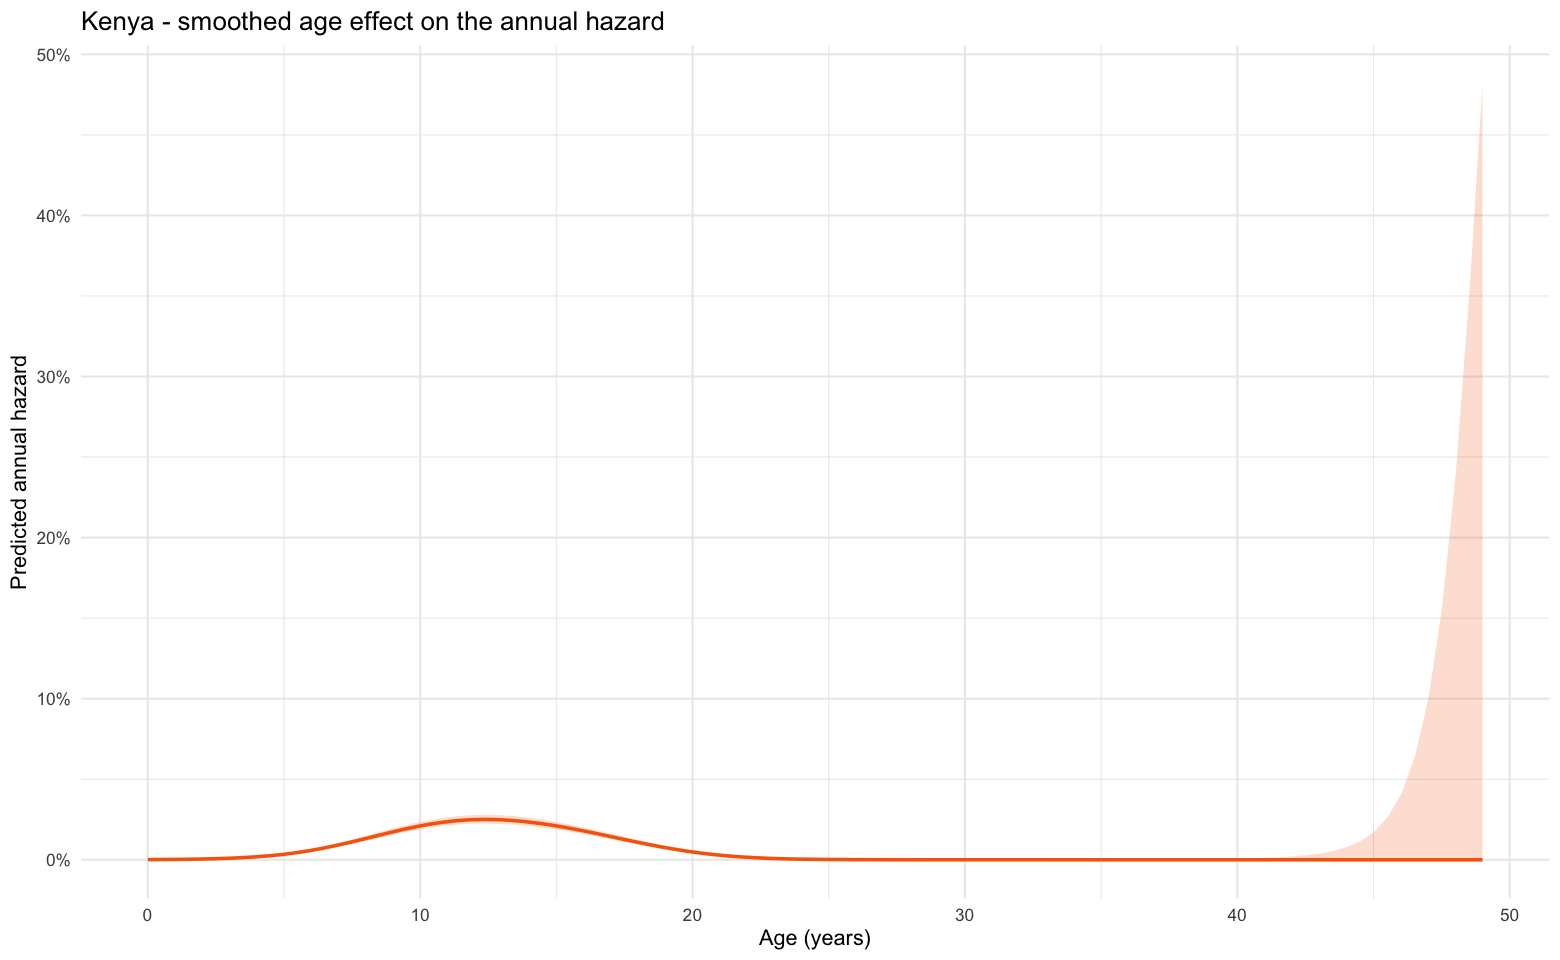

In [12]:
ref_urban_rural <- names(sort(table(cohort_numeric$urban_rural), decreasing = TRUE))[1]
ref_region <- names(sort(tapply(cohort_numeric$w_risk, cohort_numeric$region, sum), decreasing = TRUE))[1]
predict_smooth <- function(var_name, grid_values, other_fixed_at) {
  newdata <- tibble::tibble(!!var_name := grid_values) |> dplyr::bind_cols(other_fixed_at)
  pred <- predict(trend_model, newdata = newdata, type = "link", se.fit = TRUE)
  newdata |> dplyr::mutate(fit = plogis(pred$fit), lower = plogis(pred$fit - 1.96 * pred$se.fit),
                           upper = plogis(pred$fit + 1.96 * pred$se.fit))
}
fixed <- tibble::tibble(urban_rural = factor(ref_urban_rural, levels = levels(cohort_numeric$urban_rural)),
                        region = factor(ref_region, levels = levels(cohort_numeric$region)),
                        record_type = factor("self", levels = levels(cohort_numeric$record_type)))
cohort_pred <- predict_smooth("cohort_mid", seq(min(cohort_numeric$cohort_mid), max(cohort_numeric$cohort_mid), length.out = 100),
                              fixed |> dplyr::mutate(age_year = 0))
age_pred <- predict_smooth("age_year", seq(0, max_age_years, length.out = 100),
                           fixed |> dplyr::mutate(cohort_mid = stats::median(cohort_numeric$cohort_mid)))
p_cohort <- ggplot2::ggplot(cohort_pred, ggplot2::aes(cohort_mid, fit)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower, ymax = upper), fill = "#4C6EF5", alpha = 0.2) +
  ggplot2::geom_line(color = "#4C6EF5", linewidth = 1) +
  ggplot2::scale_y_continuous(labels = scales::percent) +
  ggplot2::labs(title = paste(country_name, "- smoothed cohort effect on the annual hazard at age 0"),
                x = "Birth cohort (midpoint year)", y = "Predicted annual hazard") + ggplot2::theme_minimal(base_size = 13)
p_age <- ggplot2::ggplot(age_pred, ggplot2::aes(age_year, fit)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower, ymax = upper), fill = "#F76707", alpha = 0.2) +
  ggplot2::geom_line(color = "#F76707", linewidth = 1) +
  ggplot2::scale_y_continuous(labels = scales::percent) +
  ggplot2::labs(title = paste(country_name, "- smoothed age effect on the annual hazard"),
                x = "Age (years)", y = "Predicted annual hazard") + ggplot2::theme_minimal(base_size = 13)
print(p_cohort); print(p_age)
ggplot2::ggsave(file.path(dirs$hazard, paste0(country_iso3, "_smoothed_cohort_effect.png")), p_cohort, width = 9, height = 6, dpi = 300, bg = "white")
ggplot2::ggsave(file.path(dirs$hazard, paste0(country_iso3, "_smoothed_age_effect.png")), p_age, width = 9, height = 6, dpi = 300, bg = "white")

## 10. Subnational direct estimates

Kaplan–Meier conditional risk within each five-year age band, by region and birth cohort,
pooling rounds. A band is "complete" when the cell's follow-up reaches its upper age;
otherwise only the provisional risk to the last observed age is kept, as in V1.

In [13]:
compute_cohort_region_age_band_risk <- function(record_label) {
  d <- fgm_events |> dplyr::filter(record_type == record_label)
  followup <- d |> dplyr::group_by(region, birth_cohort) |>
    dplyr::summarise(max_observed = max(time), sum_weight = sum(weight), n_records = sum(age_share), .groups = "drop")
  py <- py_cohort[[record_label]][, .(w_risk = sum(w_risk), w_event = sum(w_event)),
                                  by = .(cluster, strata, region, birth_cohort, age_year)]
  res <- km_band_risk(py, c("region", "birth_cohort"), age_band_cutpoints,
                      followup |> dplyr::select(region, birth_cohort, max_observed), design_psus[[record_label]])
  tibble::as_tibble(res) |>
    dplyr::left_join(followup |> dplyr::select(region, birth_cohort, sum_weight, n_records), by = c("region", "birth_cohort")) |>
    dplyr::filter(max_observed > lo) |>
    dplyr::transmute(
      region, birth_cohort = factor(as.character(birth_cohort)), age_band,
      event = risk, se = dplyr::if_else(supported, exp(log_surv) * se_log, NA_real_),
      provisional_event = 1 - exp(log_surv), provisional_se = exp(log_surv) * se_log,
      observed_to_age = pmin(max_observed, hi), is_complete = supported,
      sum_weight, n_records, record_type = record_label)
}
full_risk_self <- compute_cohort_region_age_band_risk("self")
full_risk_daughter <- compute_cohort_region_age_band_risk("daughter")
readr::write_csv(full_risk_self, file.path(dirs$direct, paste0(country_iso3, "_cohort_age_band_risk_self.csv")))
readr::write_csv(full_risk_daughter, file.path(dirs$direct, paste0(country_iso3, "_cohort_age_band_risk_daughter.csv")))
cat("Direct cells (complete / all): self", sum(full_risk_self$is_complete), "/", nrow(full_risk_self),
    "| daughter", sum(full_risk_daughter$is_complete), "/", nrow(full_risk_daughter), "\n")

Direct cells (complete / all): self 481 / 499 | daughter 72 / 120 


## 11. Spatial and temporal smoothing

Precision-weighted BYM2 region effect plus RW2 over birth cohort, fitted to the logit of the
direct estimates separately for each age band and reporting source (V1 method). Bands
with fewer than three complete cohorts are skipped.

In [14]:
if (run_spatial_model) {
  boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
}
if (run_spatial_model) {
  boundary_region_keys <- standardize_region(boundaries[[region_var_shapefile]])
  adjacency  <- spdep::poly2nb(boundaries, row.names = boundary_region_keys)
  adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)

  fit_bym2_rw2_one_band <- function(band_data) {
    eps <- 1e-4
    d <- band_data |>
      tidyr::drop_na(event, se) |>
      dplyr::mutate(
        birth_cohort = droplevels(birth_cohort),
        region_id    = match(standardize_region(region), boundary_region_keys),
        cohort_id    = as.integer(birth_cohort),
        p            = pmin(pmax(event, eps), 1 - eps),
        se_p         = pmax(se, eps),
        logit_est    = qlogis(p),
        logit_prec   = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
      )
    fit <- INLA::inla(
      logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE) + f(cohort_id, model = "rw2"),
      family = "gaussian", data = d, scale = d$logit_prec,
      control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
      control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
    )
    d |> dplyr::mutate(
      smoothed_risk = plogis(fit$summary.fitted.values$mean),
      lower_ci      = plogis(fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(fit$summary.fitted.values$`0.975quant`)
    )
  }

  fit_band_if_enough_data <- function(full_risk, band, source_label) {
    band_data <- full_risk |> dplyr::filter(age_band == band)
    clean_data <- tidyr::drop_na(band_data, event, se)
    n_cohorts <- dplyr::n_distinct(clean_data$birth_cohort)
    if (nrow(clean_data) < 5 || n_cohorts < 3) {
      cat("Skipping", source_label, "ages", band, "-- only", n_cohorts, "cohort(s) with real data, not enough for RW2 smoothing\n")
      return(tibble::tibble())
    }
    fit_bym2_rw2_one_band(band_data) |> dplyr::mutate(age_band = band)
  }

  smoothed_by_band_self <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_self, .x, "self"))
  smoothed_by_band_daughter <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_daughter, .x, "daughter"))

  readr::write_csv(smoothed_by_band_self,     file.path(dirs$direct, paste0(country_iso3, "_smoothed_cohort_age_band_self.csv")))
  readr::write_csv(smoothed_by_band_daughter, file.path(dirs$direct, paste0(country_iso3, "_smoothed_cohort_age_band_daughter.csv")))
} else {
  message("Spatial model disabled for this run")
}

Skipping daughter ages 10-15 -- only 0 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 15-20 -- only 0 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 20-25 -- only 0 cohort(s) with real data, not enough for RW2 smoothing


## 12. Risk maps

Smoothed regional risk by birth cohort for each age band. The youngest daughter cohort is
mapped separately as provisional.

In [15]:
if (run_spatial_model) {
  # Provisional spatial map for the 2020-2024 daughter cohort's 0-5 band.
  # Fit independently -- spatial-only BYM2, no RW2-over-cohort, since there's
  # only one cohort here -- so it never influences the three already-
  # validated, completed cohorts' smoothed estimates.
  provisional_cohort <- "2020 to 2024"
  provisional_band   <- "0-5"

  provisional_daughter_direct <- full_risk_daughter |>
    dplyr::filter(age_band == provisional_band, birth_cohort == provisional_cohort) |>
    dplyr::filter(!is.na(provisional_event))

  eps <- 1e-4
  provisional_daughter_d <- provisional_daughter_direct |>
    dplyr::mutate(
      region_id  = match(standardize_region(region), boundary_region_keys),
      p          = pmin(pmax(provisional_event, eps), 1 - eps),
      se_p       = pmax(provisional_se, eps),
      logit_est  = qlogis(p),
      logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
    )

  provisional_fit <- INLA::inla(
    logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE),
    family = "gaussian", data = provisional_daughter_d, scale = provisional_daughter_d$logit_prec,
    control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
    control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
  )

  provisional_daughter_smoothed <- provisional_daughter_d |>
    dplyr::mutate(
      smoothed_risk = plogis(provisional_fit$summary.fitted.values$mean),
      lower_ci      = plogis(provisional_fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(provisional_fit$summary.fitted.values$`0.975quant`),
      age_band      = provisional_band,
      birth_cohort  = provisional_cohort

      #birth_cohort  = paste0(provisional_cohort, " (provisional, to age ",
                  #            max(provisional_daughter_direct$observed_to_age), ")")
    )

  cat("Provisional 2020-2024 daughter map fit on", nrow(provisional_daughter_smoothed), "regions\n")
  cat("National average provisional risk:", round(mean(provisional_daughter_smoothed$smoothed_risk) * 100, 1), "%\n")
}

Provisional 2020-2024 daughter map fit on 8 regions
National average provisional risk: 0 %


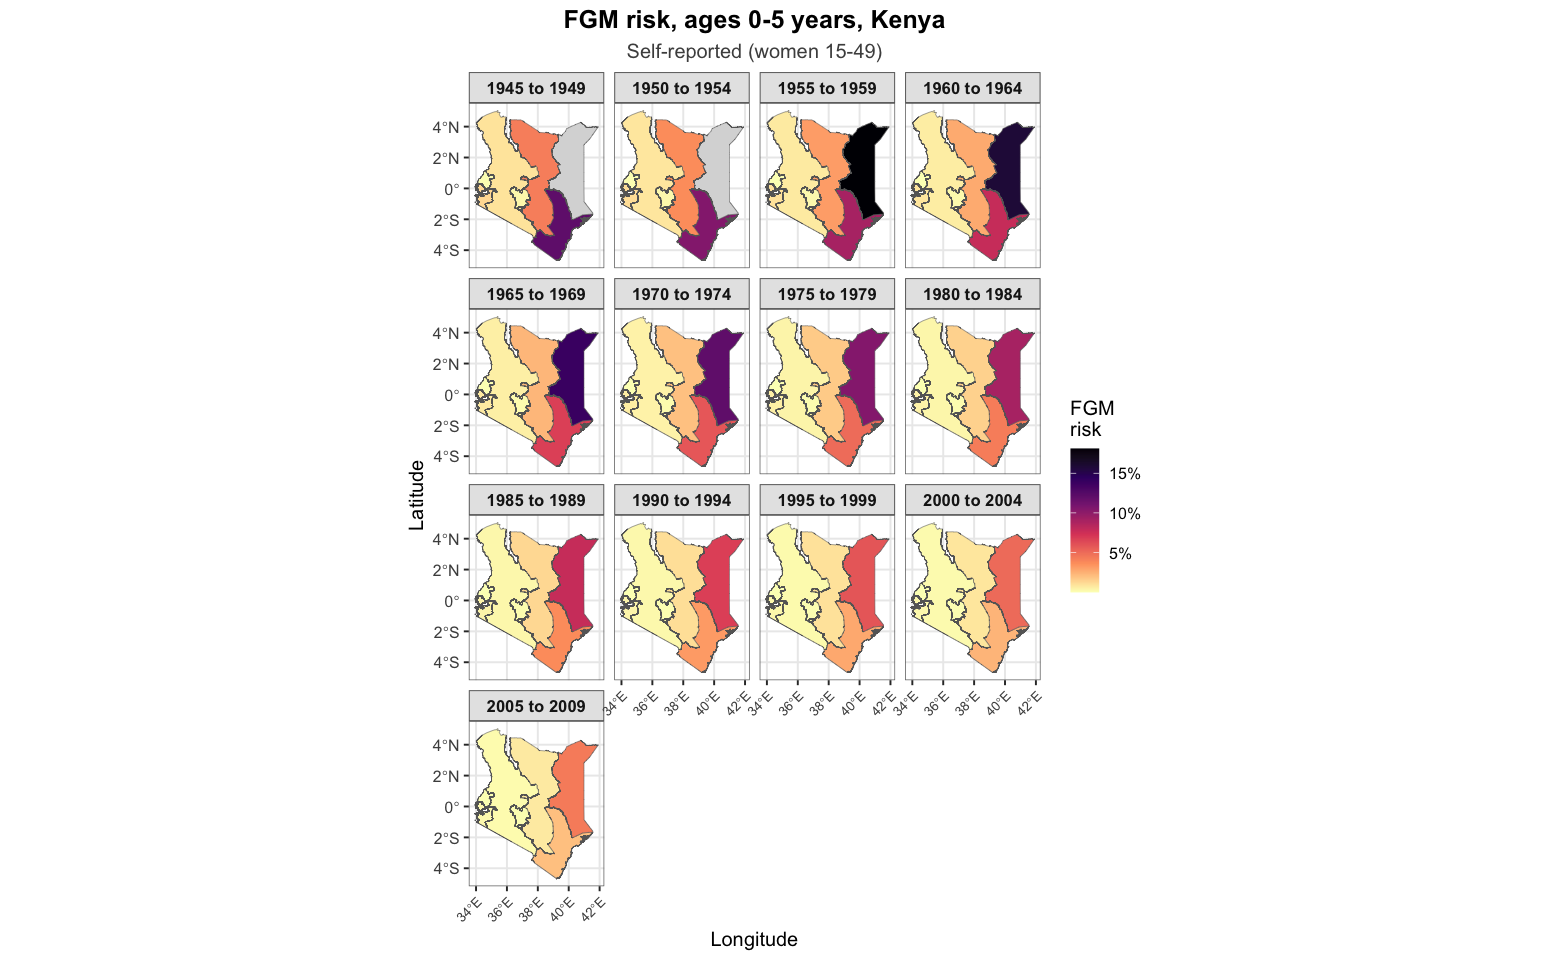

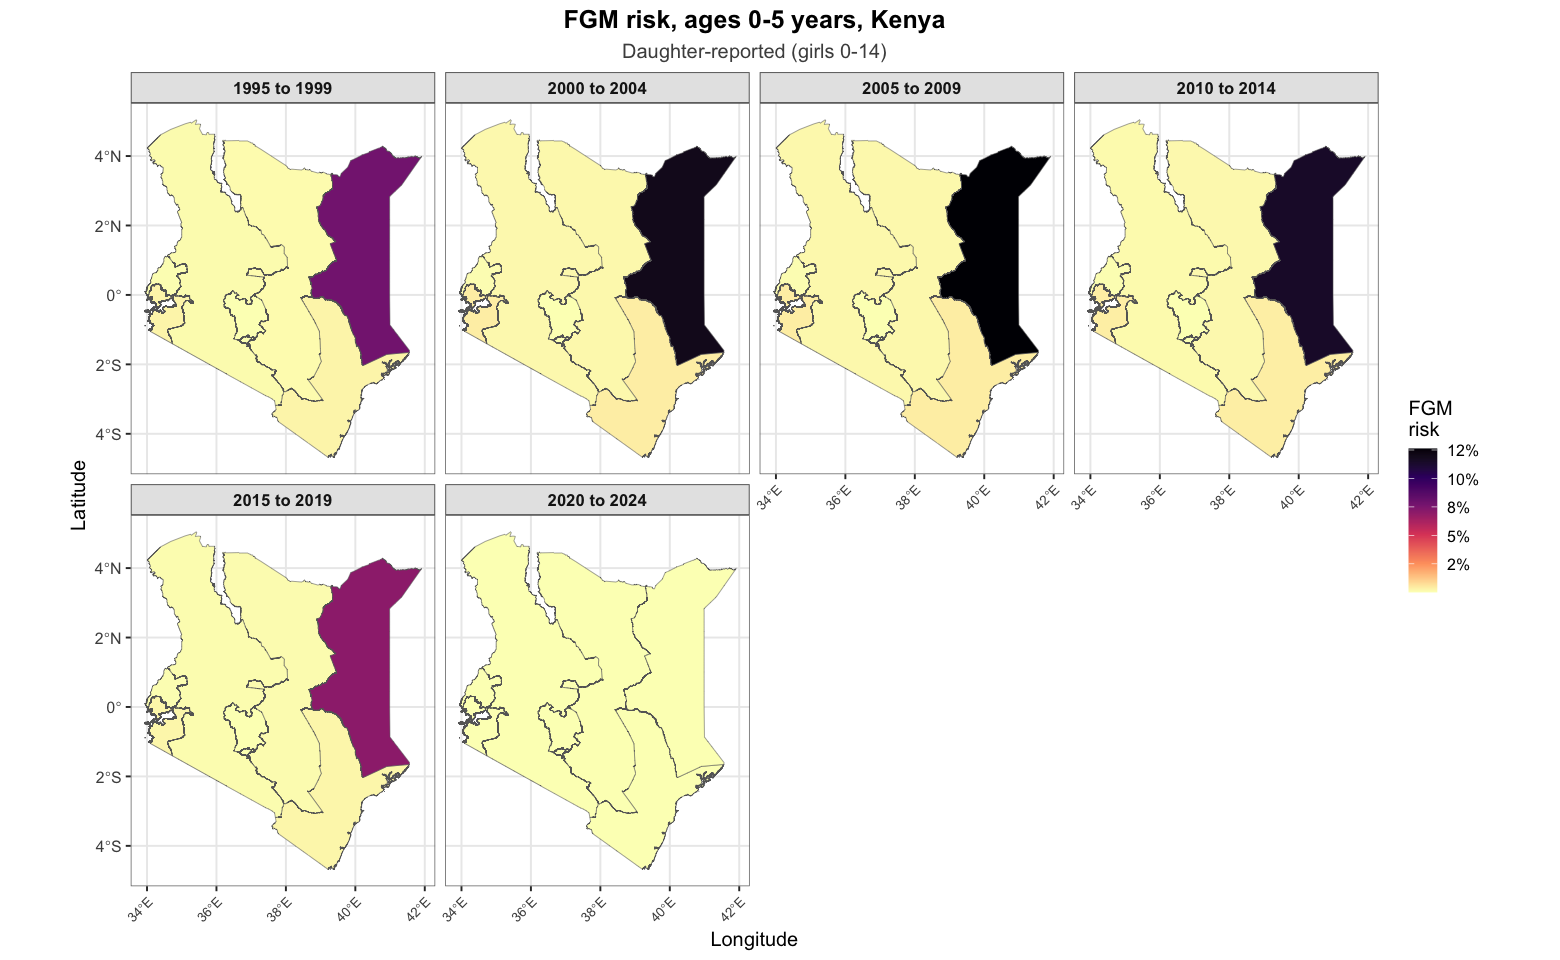

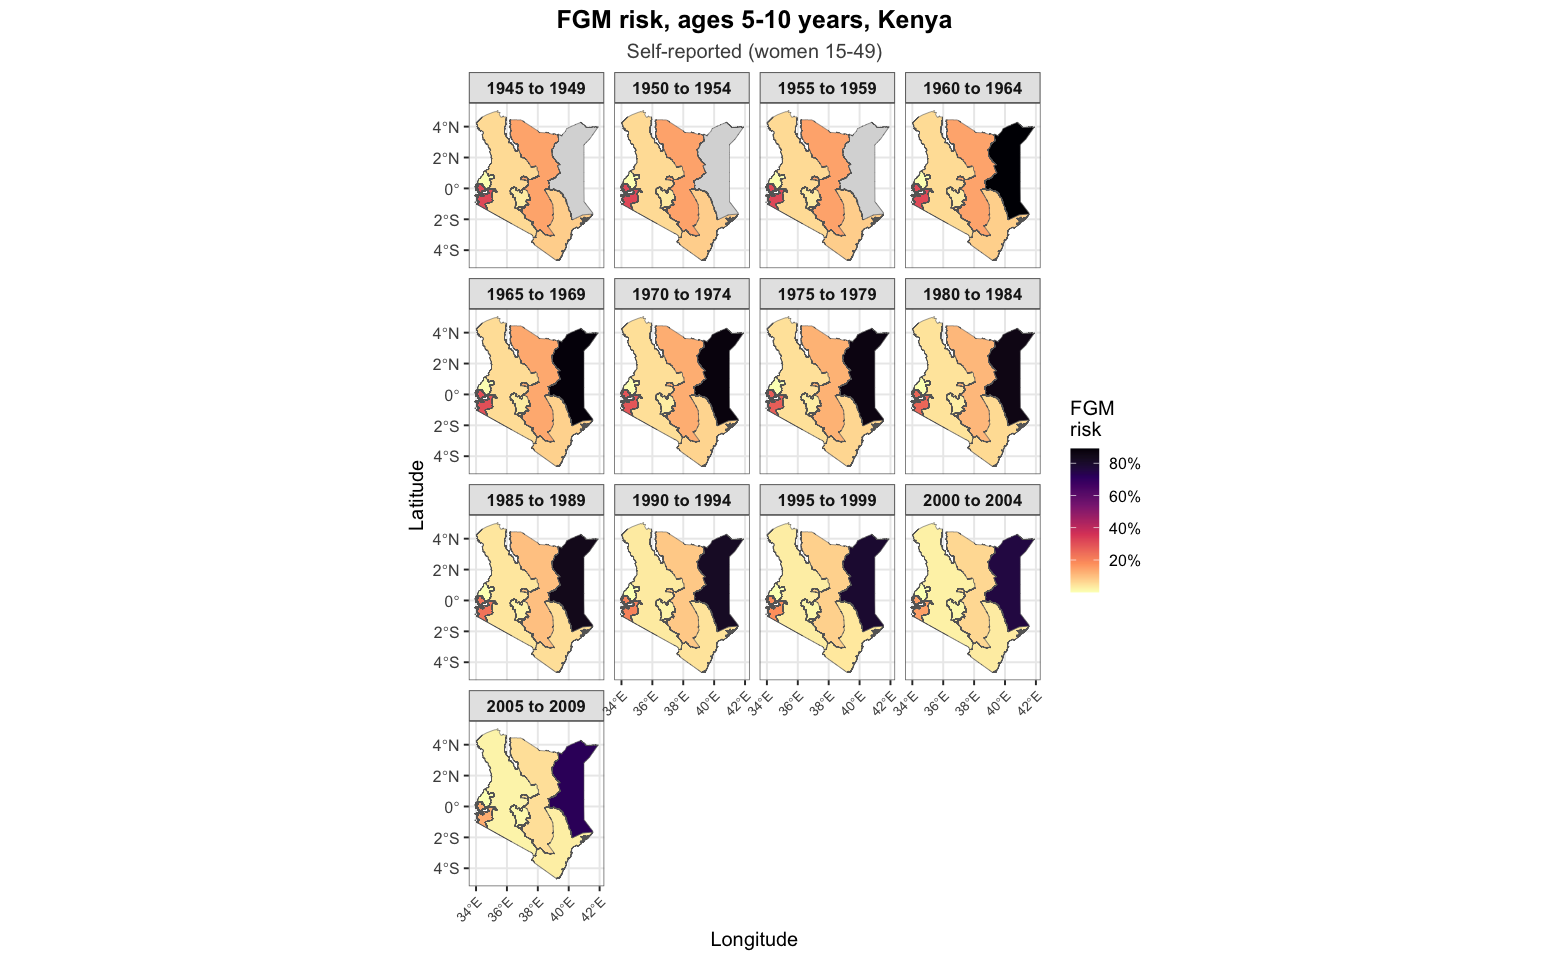

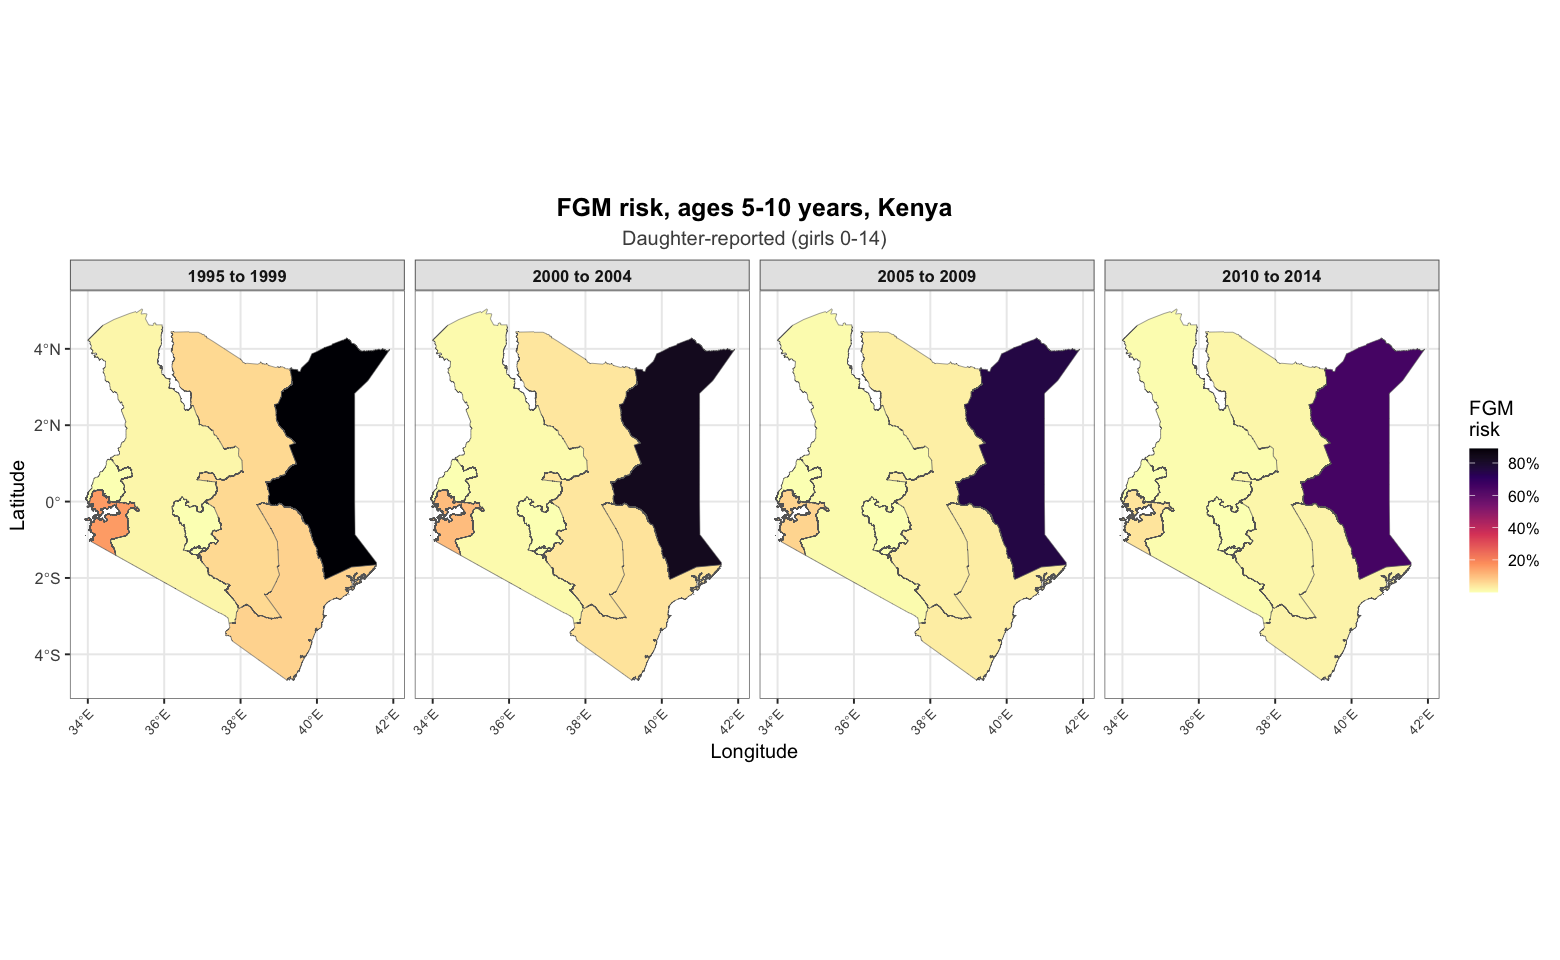

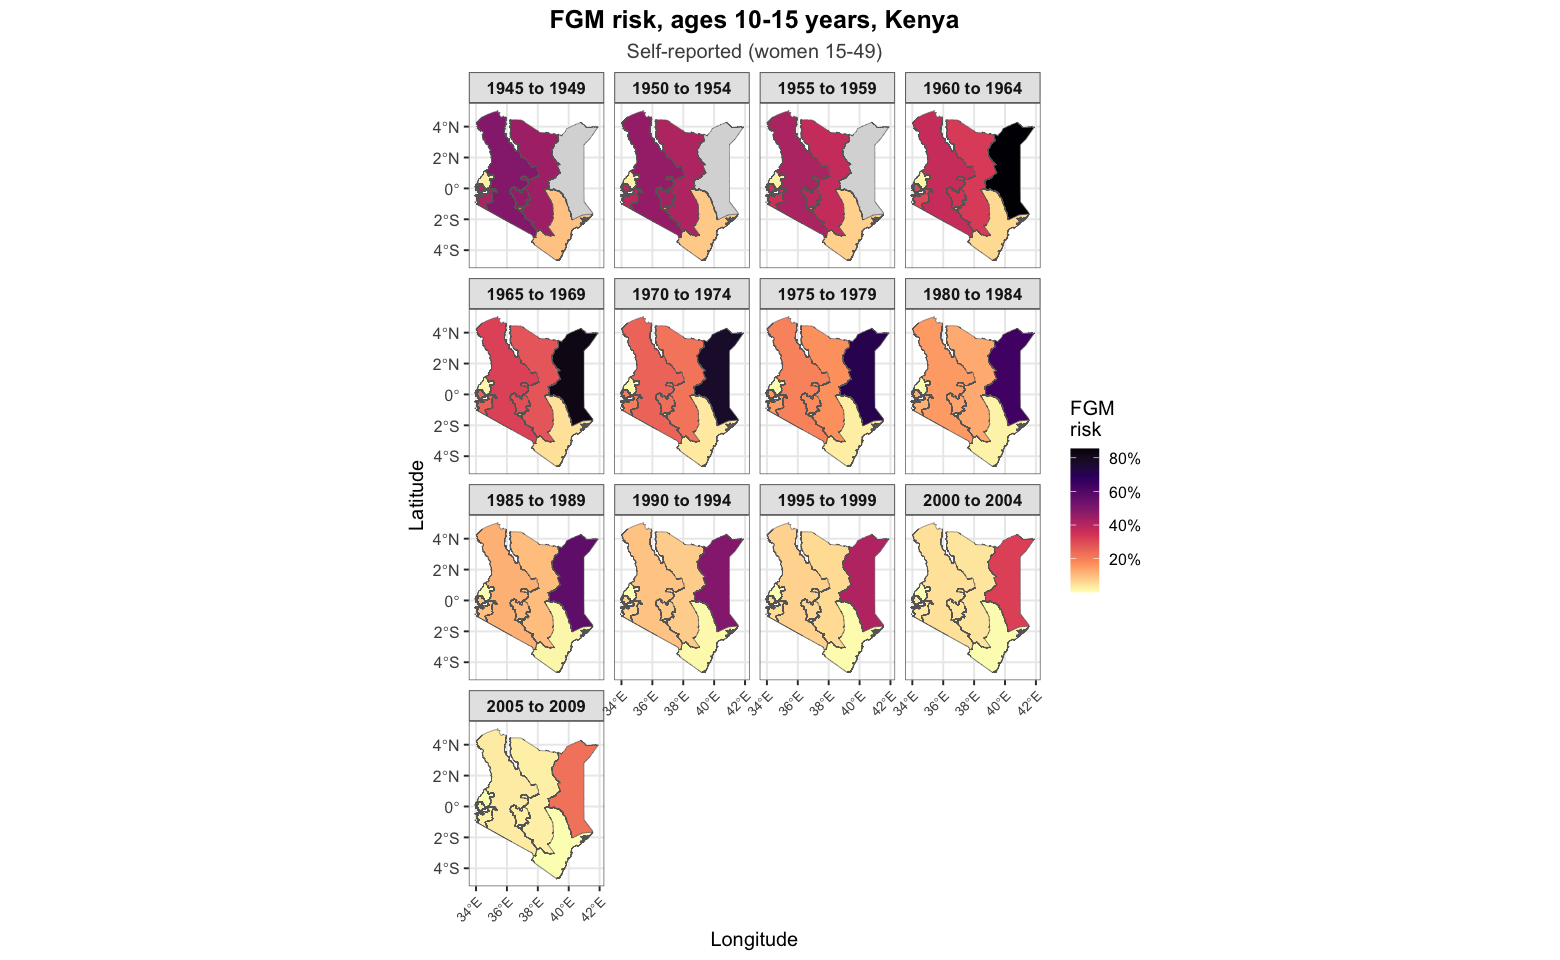

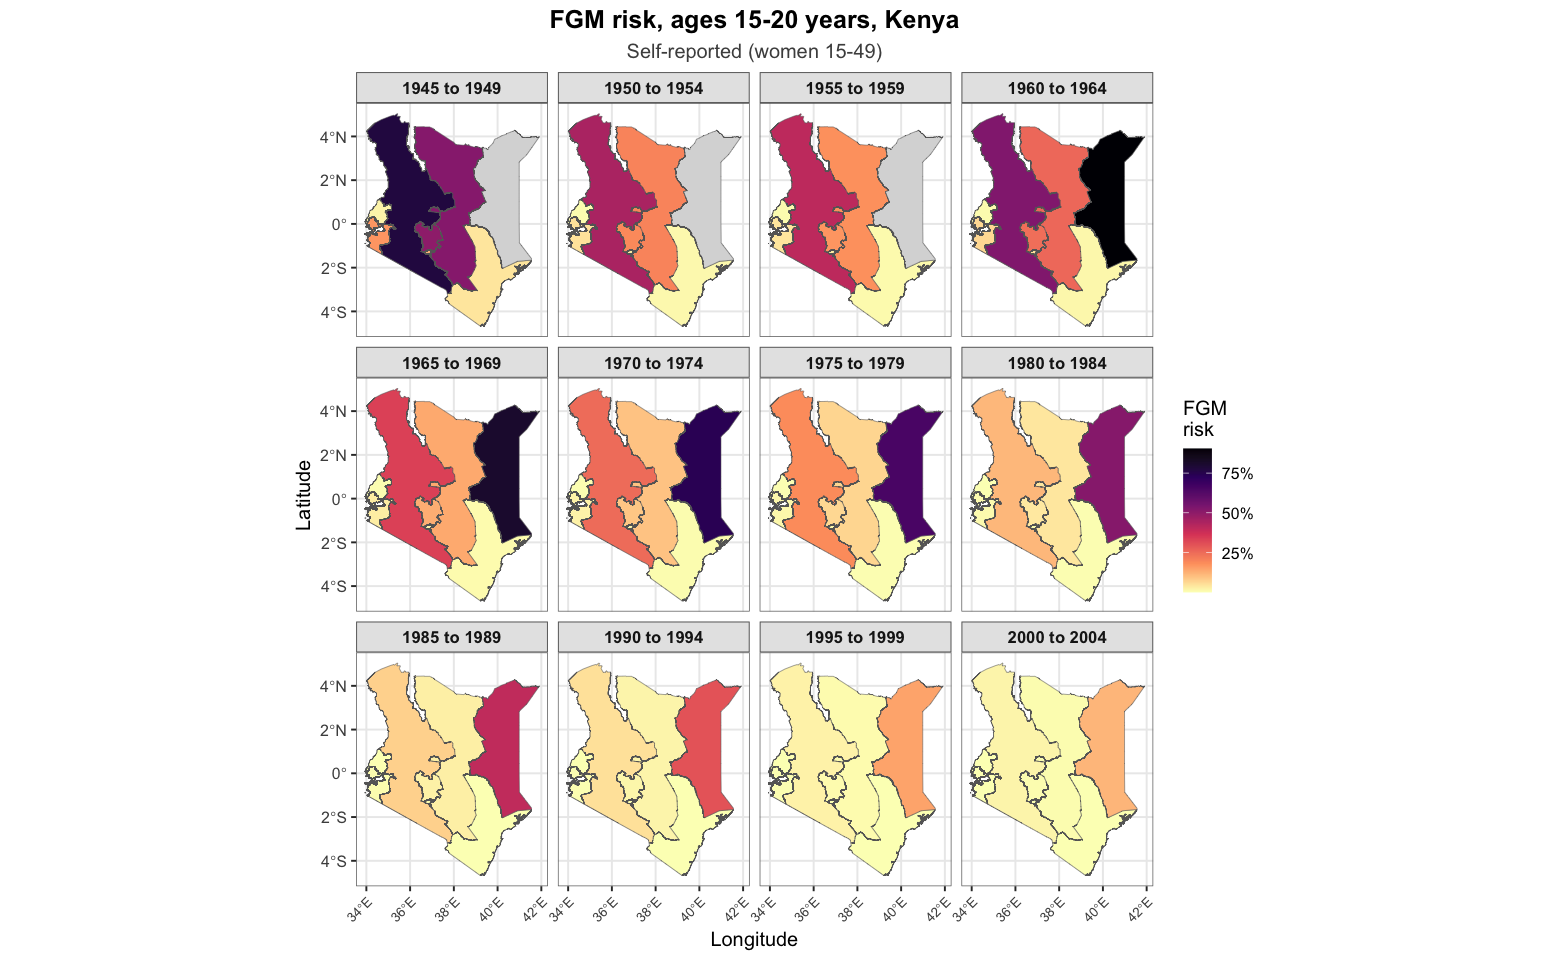

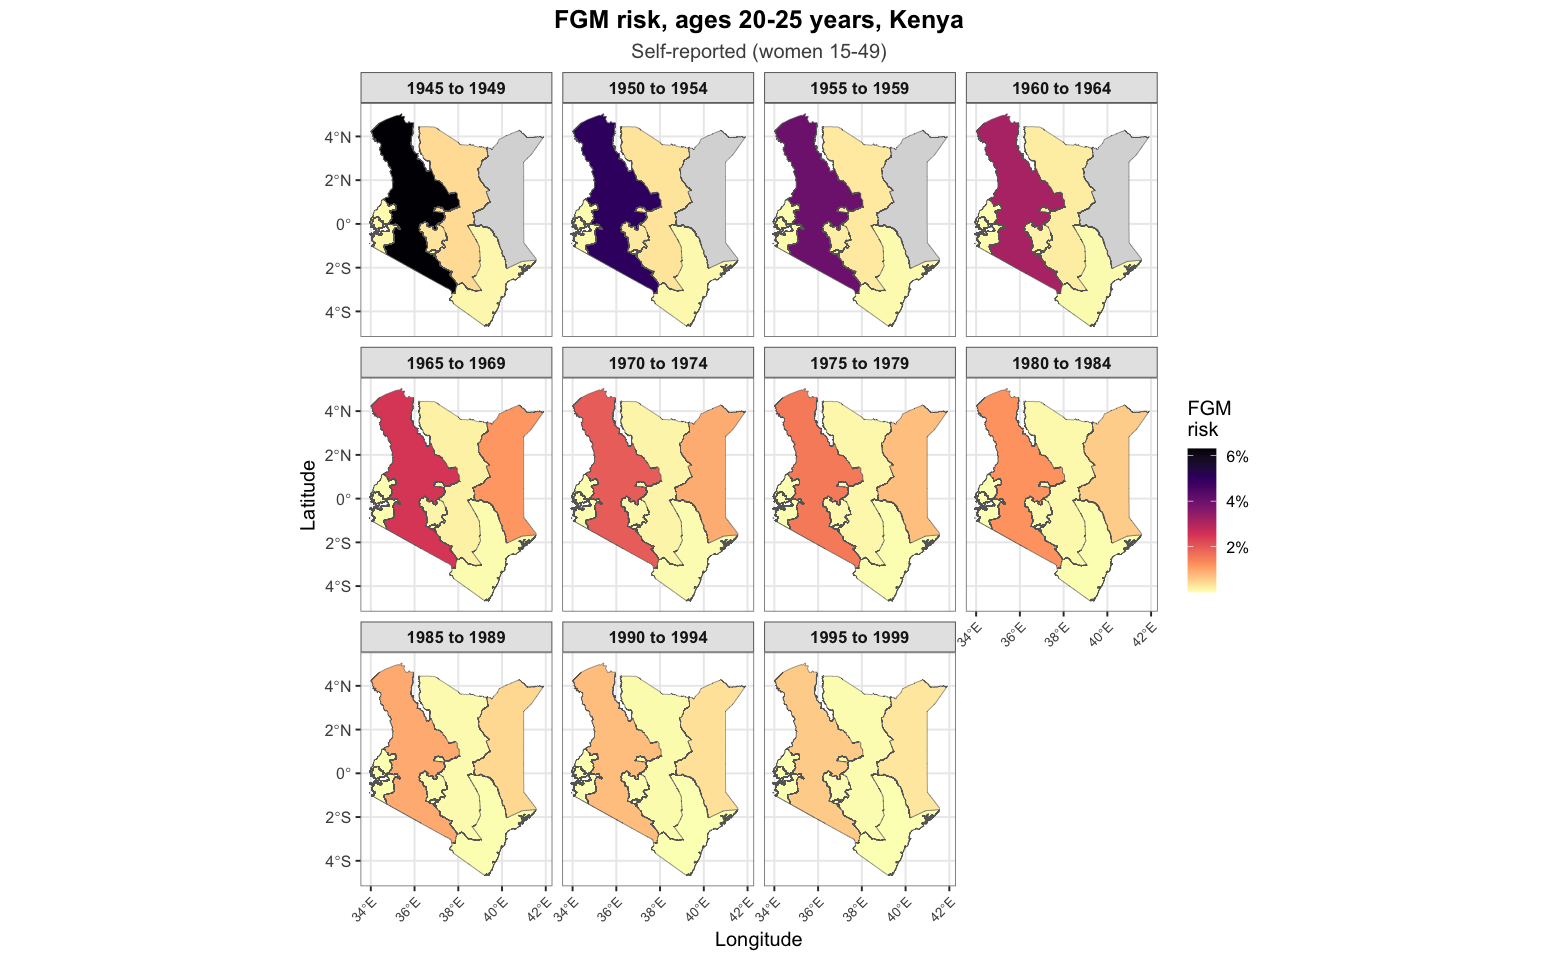

In [16]:
if (run_spatial_model) {
  make_cohort_map_for_band <- function(smoothed_estimates, band_label, source_label) {
    # Every county in every cohort panel, so counties without an estimate for
    # a cohort still show their boundary (filled grey) instead of vanishing.
    estimates <- smoothed_estimates |>
      dplyr::mutate(region = standardize_region(region),
                    birth_cohort = as.character(birth_cohort))
    county_cohort_grid <- tidyr::expand_grid(
      .region_key  = standardize_region(boundaries[[region_var_shapefile]]),
      birth_cohort = sort(unique(estimates$birth_cohort))
    ) |>
      dplyr::left_join(estimates, by = c(".region_key" = "region", "birth_cohort"))

    map_data <- boundaries |>
      dplyr::mutate(.region_key = standardize_region(.data[[region_var_shapefile]])) |>
      dplyr::inner_join(county_cohort_grid, by = ".region_key", relationship = "one-to-many")

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(ggplot2::aes(fill = smoothed_risk), color = "grey40", linewidth = 0.15) +
      ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
      ggplot2::scale_fill_viridis_c(name = "FGM\nrisk", option = "magma", direction = -1,
                                      labels = scales::percent_format(accuracy = 1),
                                      na.value = "grey85") +
      ggplot2::labs(title = paste0("FGM risk, ages ", band_label, " years, ", country_name),
                    subtitle = source_label, x = "Longitude", y = "Latitude") +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        strip.text = ggplot2::element_text(face = "bold", size = 10),
        strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  for (band in age_band_levels) {
    self_band_data <- smoothed_by_band_self |> dplyr::filter(age_band == band)
    if (nrow(self_band_data) > 0) {
      p <- make_cohort_map_for_band(self_band_data, band, "Self-reported (women 15-49)")
      print(p)
      ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_map_ages_", band, "_self.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }

    daughter_band_data <- smoothed_by_band_daughter |> dplyr::filter(age_band == band)
    if (band == provisional_band) {
      daughter_band_data <- dplyr::bind_rows(daughter_band_data, provisional_daughter_smoothed)
    }
    if (nrow(daughter_band_data) > 0) {
      p <- make_cohort_map_for_band(daughter_band_data, band, "Daughter-reported (girls 0-14)")
      print(p)
      ggplot2::ggsave(file.path(dirs$maps, paste0(country_iso3, "_map_ages_", band, "_daughter.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
}

## 12A. Covariate-adjusted risk maps

Same model as V1 12A: a survey-weighted discrete-time logistic hazard with ethnicity and
urban/rural residence as fixed effects, RW2 over single years of age, BYM2 over the 13
regions and RW2 over birth cohort, fitted separately to self-reported and daughter-reported
histories. The few records without ethnicity are excluded. Predictions keep each
region/cohort's observed covariate composition. Intervals summarize 200 joint
pseudo-posterior draws and do not fully reflect the clustered design.

In [17]:
# Helpers use separate names so the original risk estimates remain unchanged.
prepare_geo_covariate_risk <- function(events, py_cells, targets, region_keys) {
  covariates <- c("ethnicity", "urban_rural")
  people <- events |>
    dplyr::mutate(region = standardize_region(region),
                  birth_cohort = as.character(birth_cohort)) |>
    dplyr::filter(is.finite(weight), weight > 0) |>
    tidyr::drop_na(dplyr::all_of(covariates), region, birth_cohort)
  if (anyDuplicated(people$id)) stop("Duplicate IDs in geospatial risk input")
  if (!nrow(people)) stop("No complete records for geospatial risk")
  if (any(!people$region %in% region_keys)) stop("Unmatched geospatial risk region")
  cohort_levels <- sort(unique(people$birth_cohort))
  cohort_years <- as.integer(substr(cohort_levels, 1, 4))
  people <- people |>
    dplyr::mutate(region_id = match(region, region_keys),
                  cohort_id = match(birth_cohort, cohort_levels))
  for (v in covariates) people[[v]] <- factor(people[[v]])
  active_covariates <- covariates[vapply(people[covariates], nlevels, integer(1)) > 1L]
  if (length(cohort_levels) < 3L) stop("At least three cohorts are required for RW2")

  # Person-years arrive already aggregated within cluster; each cell splits into an
  # event row and a non-event row. Identical predictors and outcomes share one
  # Bernoulli likelihood, so summing their normalized weights is exact.
  cells <- py_cells |>
    dplyr::mutate(region = standardize_region(region), birth_cohort = as.character(birth_cohort)) |>
    dplyr::filter(!is.na(ethnicity), !is.na(urban_rural), birth_cohort %in% cohort_levels)
  mean_weight <- sum(cells$w_risk) / sum(cells$n_risk)
  train <- dplyr::bind_rows(
    cells |> dplyr::transmute(region_id = match(region, region_keys), cohort_id = match(birth_cohort, cohort_levels),
                              age_year, ethnicity, urban_rural, event = 1L, pseudo_weight = w_event / mean_weight),
    cells |> dplyr::transmute(region_id = match(region, region_keys), cohort_id = match(birth_cohort, cohort_levels),
                              age_year, ethnicity, urban_rural, event = 0L,
                              pseudo_weight = (w_risk - w_event) / mean_weight)
  ) |>
    dplyr::filter(pseudo_weight > 0) |>
    dplyr::group_by(region_id, cohort_id, age_year, ethnicity, urban_rural, event) |>
    dplyr::summarise(pseudo_weight = sum(pseudo_weight), .groups = "drop")

  profiles <- people |>
    dplyr::group_by(region, birth_cohort, region_id, cohort_id, ethnicity, urban_rural) |>
    dplyr::summarise(profile_weight = sum(weight), .groups = "drop") |>
    dplyr::mutate(profile_id = dplyr::row_number())
  support <- people |>
    dplyr::group_by(region, birth_cohort) |>
    dplyr::summarise(complete_case_followup = max(time), n_complete = dplyr::n(),
                     .groups = "drop")
  targets <- targets |>
    dplyr::mutate(region = standardize_region(region),
                  birth_cohort = as.character(birth_cohort),
                  start_age = as.integer(sub("-.*", "", age_band)),
                  end_age = as.integer(sub(".*-", "", age_band))) |>
    dplyr::left_join(support, by = c("region", "birth_cohort")) |>
    dplyr::mutate(stop_age = pmin(observed_to_age, end_age),
                  supported = is.finite(complete_case_followup) &
                    is.finite(stop_age) & stop_age > start_age &
                    stop_age <= complete_case_followup,
                  target_id = dplyr::row_number())
  profiles <- profiles |>
    dplyr::inner_join(targets |> dplyr::filter(supported) |>
                       dplyr::group_by(region, birth_cohort) |>
                       dplyr::summarise(prediction_end = max(stop_age), .groups = "drop"),
                     by = c("region", "birth_cohort"))
  if (!nrow(profiles)) stop("No supported region-cohort profiles for prediction")
  prediction <- profiles |>
    tidyr::uncount(weights = as.integer(prediction_end) + 1L, .id = "age_index") |>
    dplyr::mutate(age_year = age_index - 1L, event = NA_integer_, pseudo_weight = 1) |>
    dplyr::arrange(profile_id, age_year)
  model_data <- dplyr::bind_rows(train, prediction |> dplyr::select(dplyr::all_of(names(train))))
  for (v in covariates) {
    model_data[[v]] <- factor(model_data[[v]], levels = levels(people[[v]]))
  }
  list(people = people, train = train, prediction = prediction,
       model_data = model_data, targets = targets, active_covariates = active_covariates,
       cohort_years = cohort_years, excluded = nrow(events) - nrow(people),
       annual_n = sum(cells$n_risk))
}

geo_covariate_band_risk <- function(eta, prediction, targets) {
  stopifnot(length(eta) == nrow(prediction), all(is.finite(eta)))
  # Stable log(1 - plogis(eta)), including extreme fitted values.
  log_survival_step <- -pmax(eta, 0) - log1p(exp(-abs(eta)))
  survival <- prediction |>
    dplyr::mutate(log_step = log_survival_step) |>
    dplyr::group_by(profile_id) |>
    dplyr::mutate(survival = exp(cumsum(log_step))) |>
    dplyr::ungroup() |>
    dplyr::group_by(region, birth_cohort, age_year) |>
    dplyr::summarise(survival = stats::weighted.mean(survival, profile_weight),
                     .groups = "drop")
  starts <- survival |> dplyr::rename(start_age = age_year, start_survival = survival)
  stops <- survival |> dplyr::rename(stop_age = age_year, stop_survival = survival)
  result <- targets |>
    dplyr::left_join(starts, by = c("region", "birth_cohort", "start_age")) |>
    dplyr::left_join(stops, by = c("region", "birth_cohort", "stop_age")) |>
    dplyr::mutate(
      # Match the original direct-risk convention: S(0-) = 1 for the first
      # band; later bands condition on survival through their lower cutpoint.
      start_survival = dplyr::if_else(start_age == 0L, 1, start_survival),
      risk = dplyr::if_else(supported & is.finite(start_survival) &
                             start_survival > 0 & is.finite(stop_survival),
                           pmin(1, pmax(0, 1 - stop_survival / start_survival)), NA_real_))
  result$risk
}

fit_geo_covariate_risk <- function(prepared, graph, n_draws = 200L, seed = 20260923L) {
  cohort_values <- prepared$cohort_years
  # Actual cohort years retain five-year spacing, even if a cohort is absent.
  # RW2 over single years of age replaces a linear age slope.
  age_values <- seq(min(prepared$model_data$age_year), max(prepared$model_data$age_year))
  model_formula <- stats::as.formula(paste(
    "event ~ 1", paste(c("", prepared$active_covariates), collapse = " + "),
    "+ f(age_year, model = 'rw2', values = age_values, scale.model = TRUE, constr = TRUE)",
    "+ f(region_id, model = 'bym2', graph = graph, scale.model = TRUE)",
    "+ f(cohort_id, model = 'rw2', values = cohort_values, scale.model = TRUE, constr = TRUE)"
  ))
  # RW2 index values and values must use the same scale.
  model_data <- prepared$model_data
  model_data$cohort_id <- cohort_values[model_data$cohort_id]
  previous_weight_option <- INLA::inla.getOption("enable.inla.argument.weights")
  INLA::inla.setOption(enable.inla.argument.weights = TRUE)
  on.exit(INLA::inla.setOption(enable.inla.argument.weights = previous_weight_option), add = TRUE)
  fit <- INLA::inla(
    model_formula, family = "binomial", data = model_data,
    Ntrials = rep(1L, nrow(model_data)), weights = model_data$pseudo_weight,
    control.predictor = list(compute = TRUE, link = 1),
    control.compute = list(config = TRUE),
    control.inla = list(control.vb = list(enable = FALSE))
  )
  # Transform complete joint posterior predictors before aggregating; do not
  # combine marginal interval endpoints or average annual hazards across people.
  set.seed(seed)
  prediction_indices <- nrow(prepared$train) + seq_len(nrow(prepared$prediction))
  draw_risks <- matrix(NA_real_, nrow(prepared$targets), n_draws)
  for (first in seq.int(1L, n_draws, by = 20L)) {
    last <- min(n_draws, first + 19L)
    samples <- INLA::inla.posterior.sample(last - first + 1L, fit,
                                          use.improved.mean = FALSE, skew.corr = FALSE)
    for (j in seq_along(samples)) {
      latent <- samples[[j]]$latent
      all_predictor_rows <- grep("^Predictor:", rownames(latent))
      predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:", "",
        rownames(latent)[all_predictor_rows])))
      predictor_rows <- all_predictor_rows[match(prediction_indices, predictor_numbers)]
      if (anyNA(predictor_rows)) stop("Posterior predictor rows do not match prediction data")
      draw_risks[, first + j - 1L] <- geo_covariate_band_risk(
        as.numeric(latent[predictor_rows, 1L]), prepared$prediction, prepared$targets)
    }
  }
  safe_quantile <- function(x, p) {
    if (all(is.na(x))) NA_real_ else unname(stats::quantile(x, p, na.rm = TRUE))
  }
  estimates <- prepared$targets |>
    dplyr::mutate(
      adjusted_risk = rowMeans(draw_risks),
      lower_ci = apply(draw_risks, 1L, safe_quantile, p = 0.025),
      upper_ci = apply(draw_risks, 1L, safe_quantile, p = 0.975),
      estimate_status = dplyr::case_when(
        !supported ~ "Insufficient complete-case follow-up",
        is_provisional ~ "Provisional: incomplete age band",
        TRUE ~ "Completed age band"))
  list(estimates = estimates, fixed_effects = fit$summary.fixed,
       formula = paste(deparse(model_formula), collapse = " "),
       excluded = prepared$excluded, annual_n = prepared$annual_n)
}

In [18]:
py_covariate <- lapply(split(fgm_events, fgm_events$record_type), aggregate_person_years,
                       group_vars = c("region", "birth_cohort", "ethnicity", "urban_rural"), max_age = max_age_years)
if (run_spatial_model) {
  geo_cov_required <- c("INLA", "sf", "spdep")
  geo_cov_missing <- geo_cov_required[
    !vapply(geo_cov_required, requireNamespace, logical(1), quietly = TRUE)]
  if (length(geo_cov_missing)) stop("Geospatial covariates requires: ",
                                  paste(geo_cov_missing, collapse = ", "))
  geo_cov_output_dir <- dirs$covariate
  dir.create(geo_cov_output_dir, recursive = TRUE, showWarnings = FALSE)
  geo_cov_draws <- 200L
  geo_cov_results <- list()
  geo_cov_audit <- list()

  for (geo_cov_source in c("self", "daughter")) {
    geo_cov_direct <- if (geo_cov_source == "self") full_risk_self else full_risk_daughter
    geo_cov_existing <- if (geo_cov_source == "self") smoothed_by_band_self else smoothed_by_band_daughter
    # Match the completed region/cohort/age-band cells in the original maps.
    geo_cov_targets <- geo_cov_existing |>
      dplyr::select(region, birth_cohort, age_band) |>
      dplyr::distinct() |>
      dplyr::left_join(geo_cov_direct |>
                        dplyr::select(region, birth_cohort, age_band, observed_to_age),
                      by = c("region", "birth_cohort", "age_band")) |>
      dplyr::mutate(is_provisional = FALSE)
    if (geo_cov_source == "daughter" && nrow(provisional_daughter_smoothed) > 0L) {
      geo_cov_targets <- dplyr::bind_rows(
        geo_cov_targets,
        provisional_daughter_smoothed |>
          dplyr::transmute(region, birth_cohort, age_band, observed_to_age,
                           is_provisional = TRUE))
    }
    if (!nrow(geo_cov_targets)) next
    geo_cov_prepared <- prepare_geo_covariate_risk(
      fgm_events |> dplyr::filter(record_type == geo_cov_source),
      py_covariate[[geo_cov_source]],
      geo_cov_targets, boundary_region_keys)
    cat("Geospatial covariates:", geo_cov_source, "--", nrow(geo_cov_prepared$people),
        "histories;", geo_cov_prepared$excluded, "excluded for missing covariates/invalid weights\n")
    geo_cov_result <- fit_geo_covariate_risk(
      geo_cov_prepared, adjacency_matrix, n_draws = geo_cov_draws,
      seed = if (geo_cov_source == "self") 20260923L else 20260924L)
    geo_cov_results[[geo_cov_source]] <- geo_cov_result$estimates |>
      dplyr::mutate(record_type = geo_cov_source)
    geo_cov_audit[[geo_cov_source]] <- tibble::tibble(
      record_type = geo_cov_source, n_histories = nrow(geo_cov_prepared$people),
      excluded = geo_cov_prepared$excluded, annual_rows = geo_cov_prepared$annual_n,
      grouped_likelihood_rows = nrow(geo_cov_prepared$train), posterior_draws = geo_cov_draws,
      formula = geo_cov_result$formula)
    readr::write_csv(geo_cov_results[[geo_cov_source]], file.path(geo_cov_output_dir,
      paste0(country_iso3, "_covariate_adjusted_risk_", geo_cov_source, ".csv")))
    readr::write_csv(tibble::rownames_to_column(as.data.frame(geo_cov_result$fixed_effects), "term"),
      file.path(geo_cov_output_dir,
                paste0(country_iso3, "_risk_covariate_fixed_effects_", geo_cov_source, ".csv")))
  }
  readr::write_csv(dplyr::bind_rows(geo_cov_audit),
                   file.path(geo_cov_output_dir, paste0(country_iso3, "_risk_covariate_model_audit.csv")))
} else {
  message("Geospatial covariates skipped: survey-region boundary file unavailable")
}

Geospatial covariates: self -- 55279 histories; 15 excluded for missing covariates/invalid weights


Warning message in inla.matchOption(option, valid.opt, several.ok = TRUE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning, inla.call”


Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning”


Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning”


Geospatial covariates: daughter -- 26807 histories; 9 excluded for missing covariates/invalid weights


Warning message in inla.matchOption(option, valid.opt, several.ok = TRUE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning, inla.call”


Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning”


Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
“Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning”


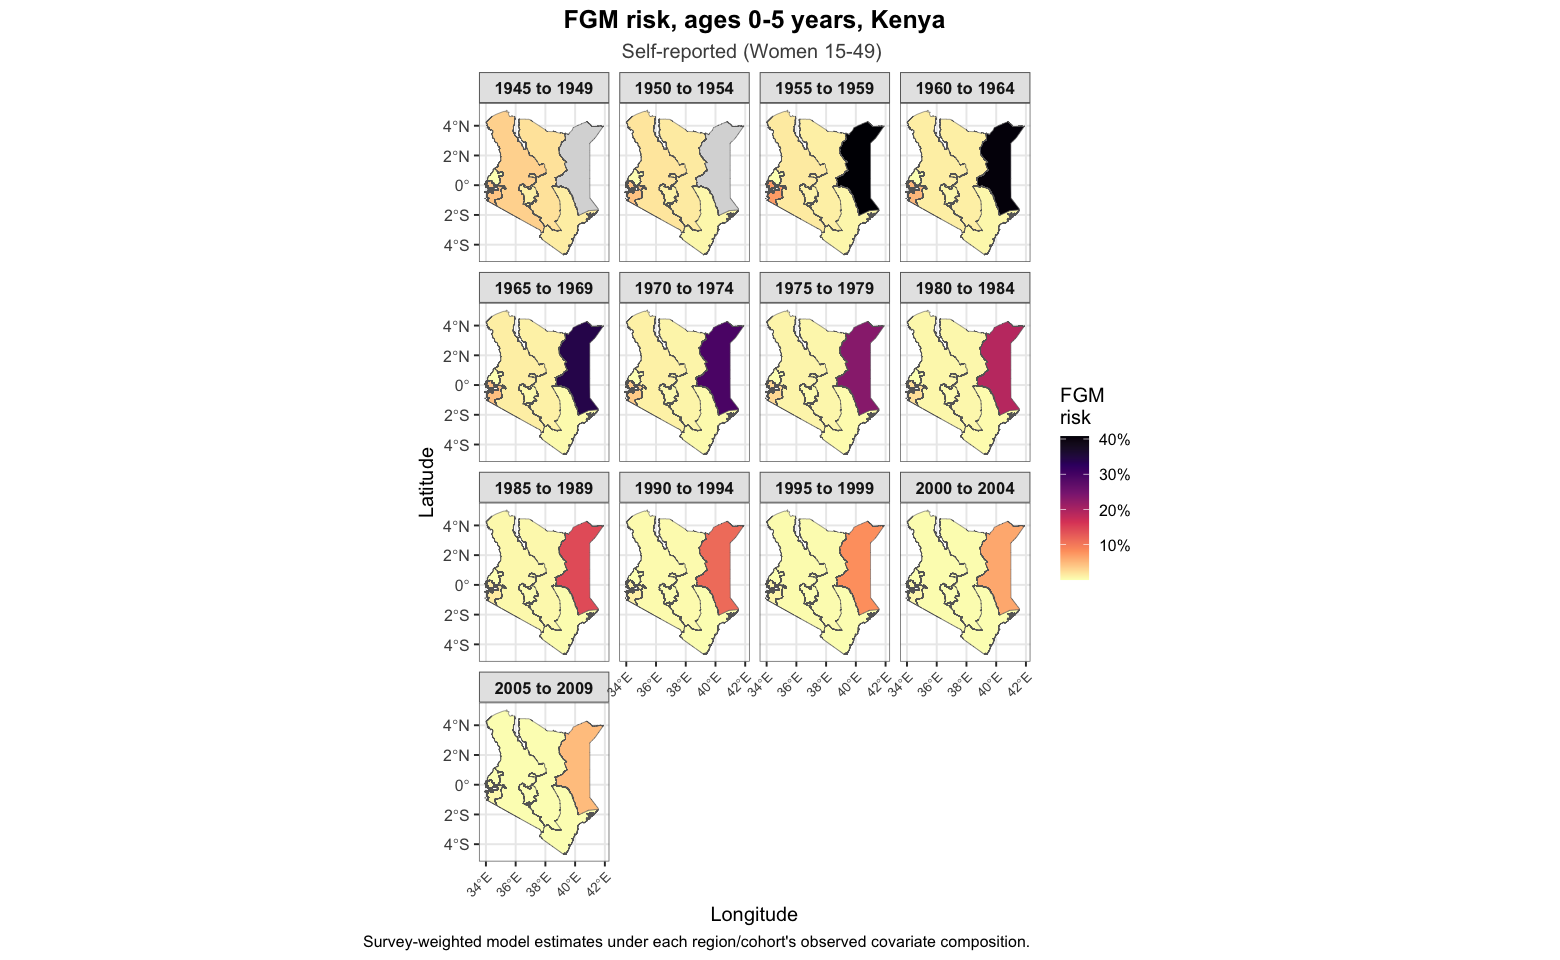

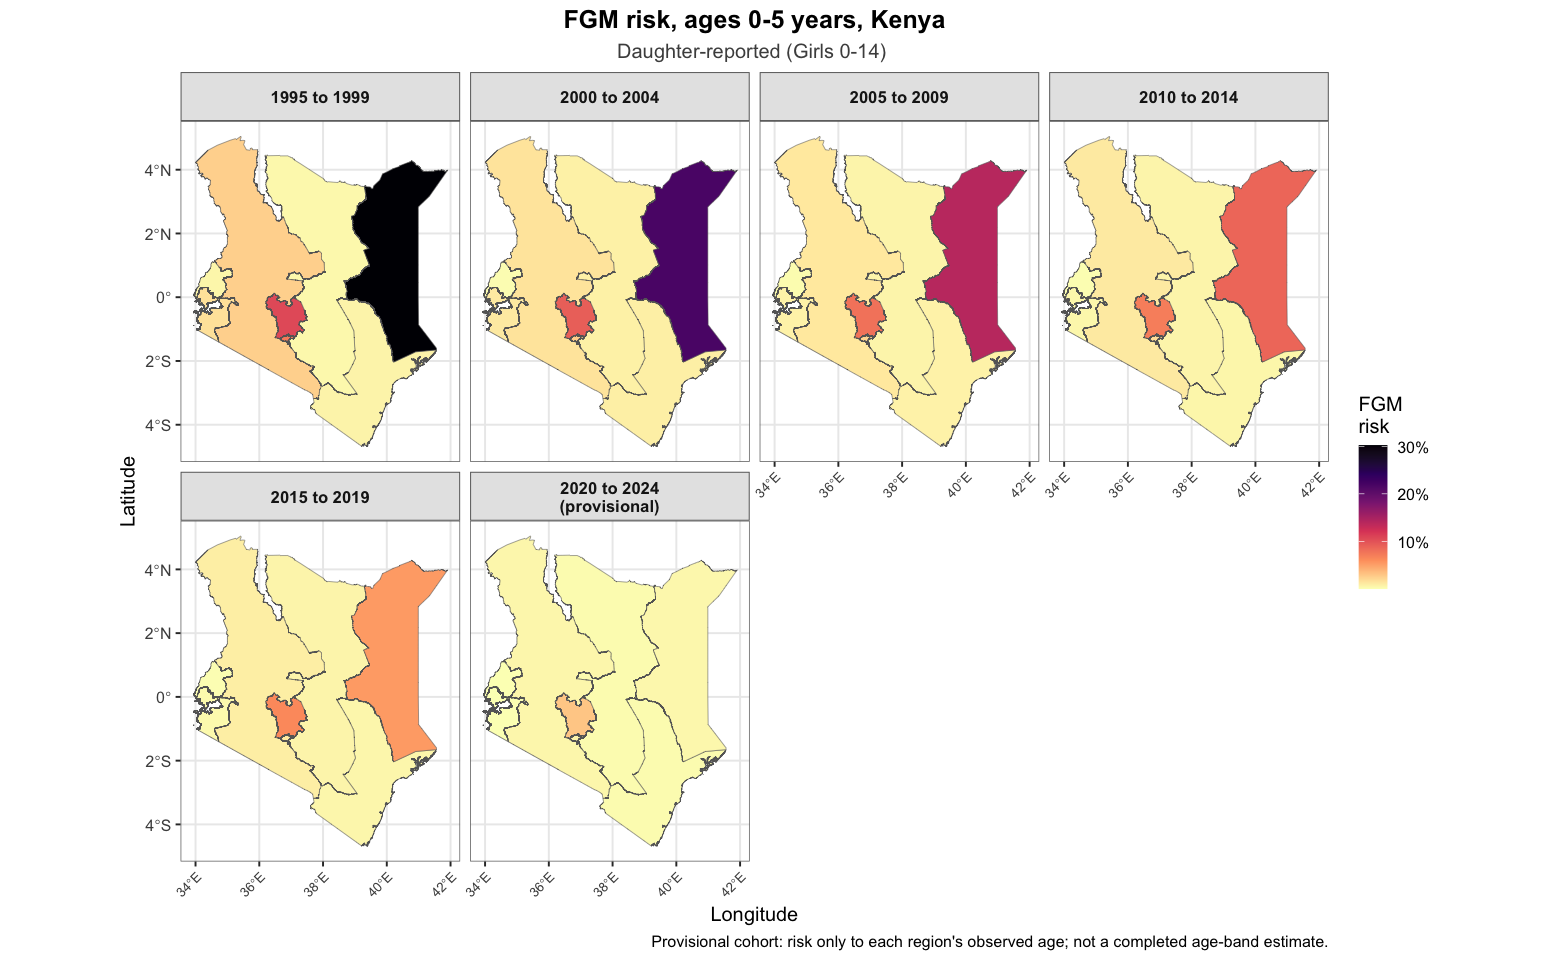

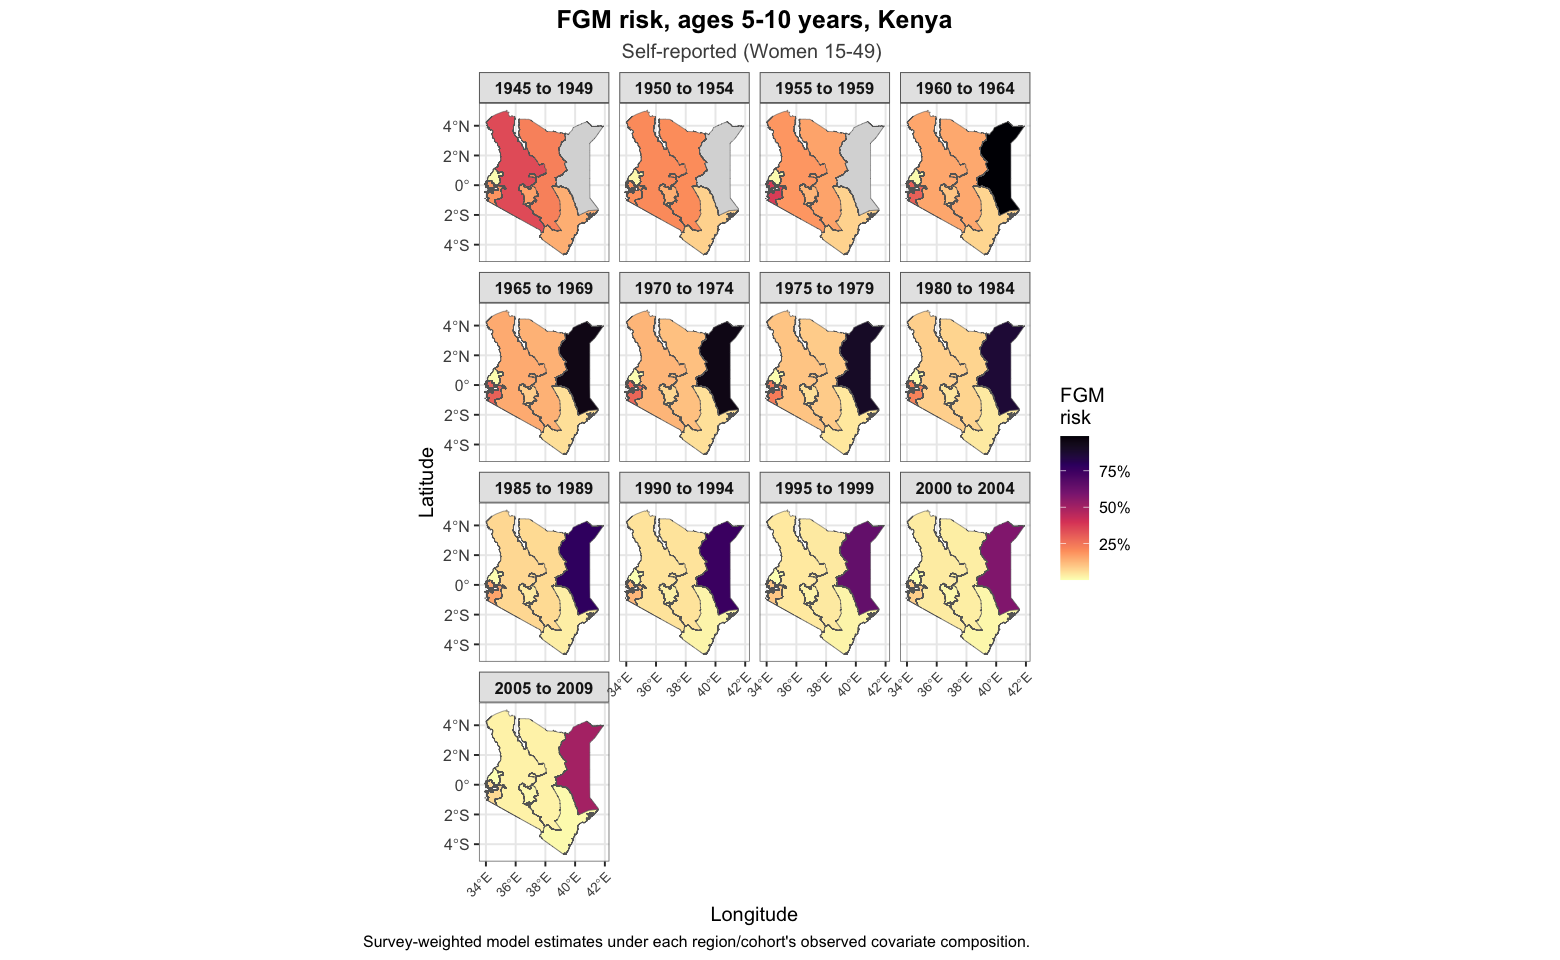

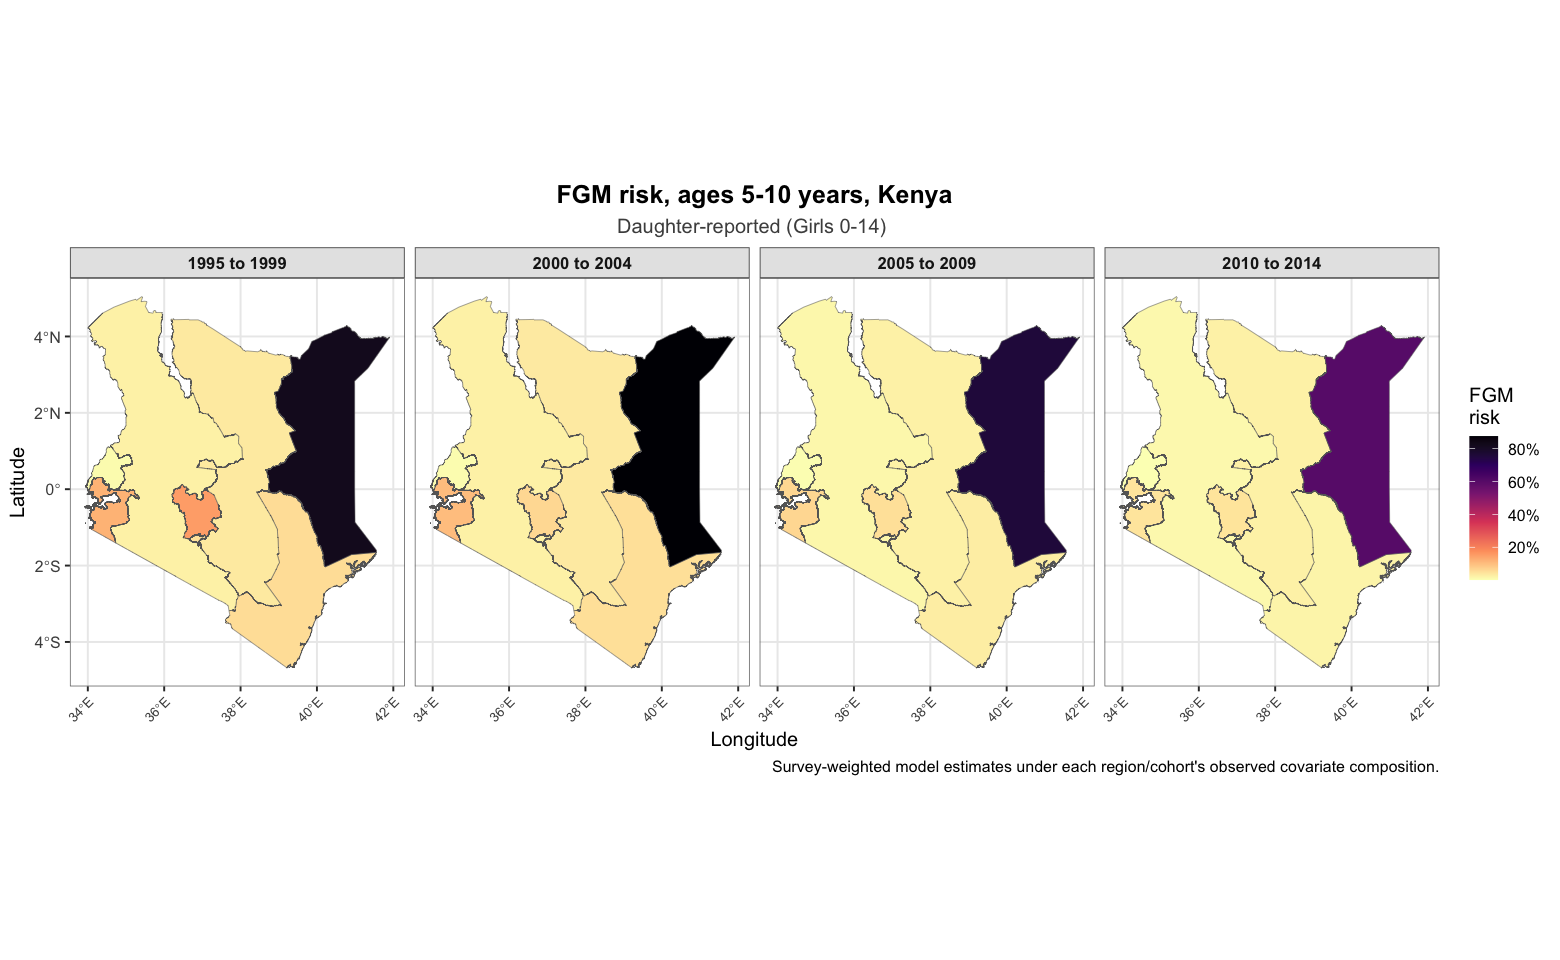

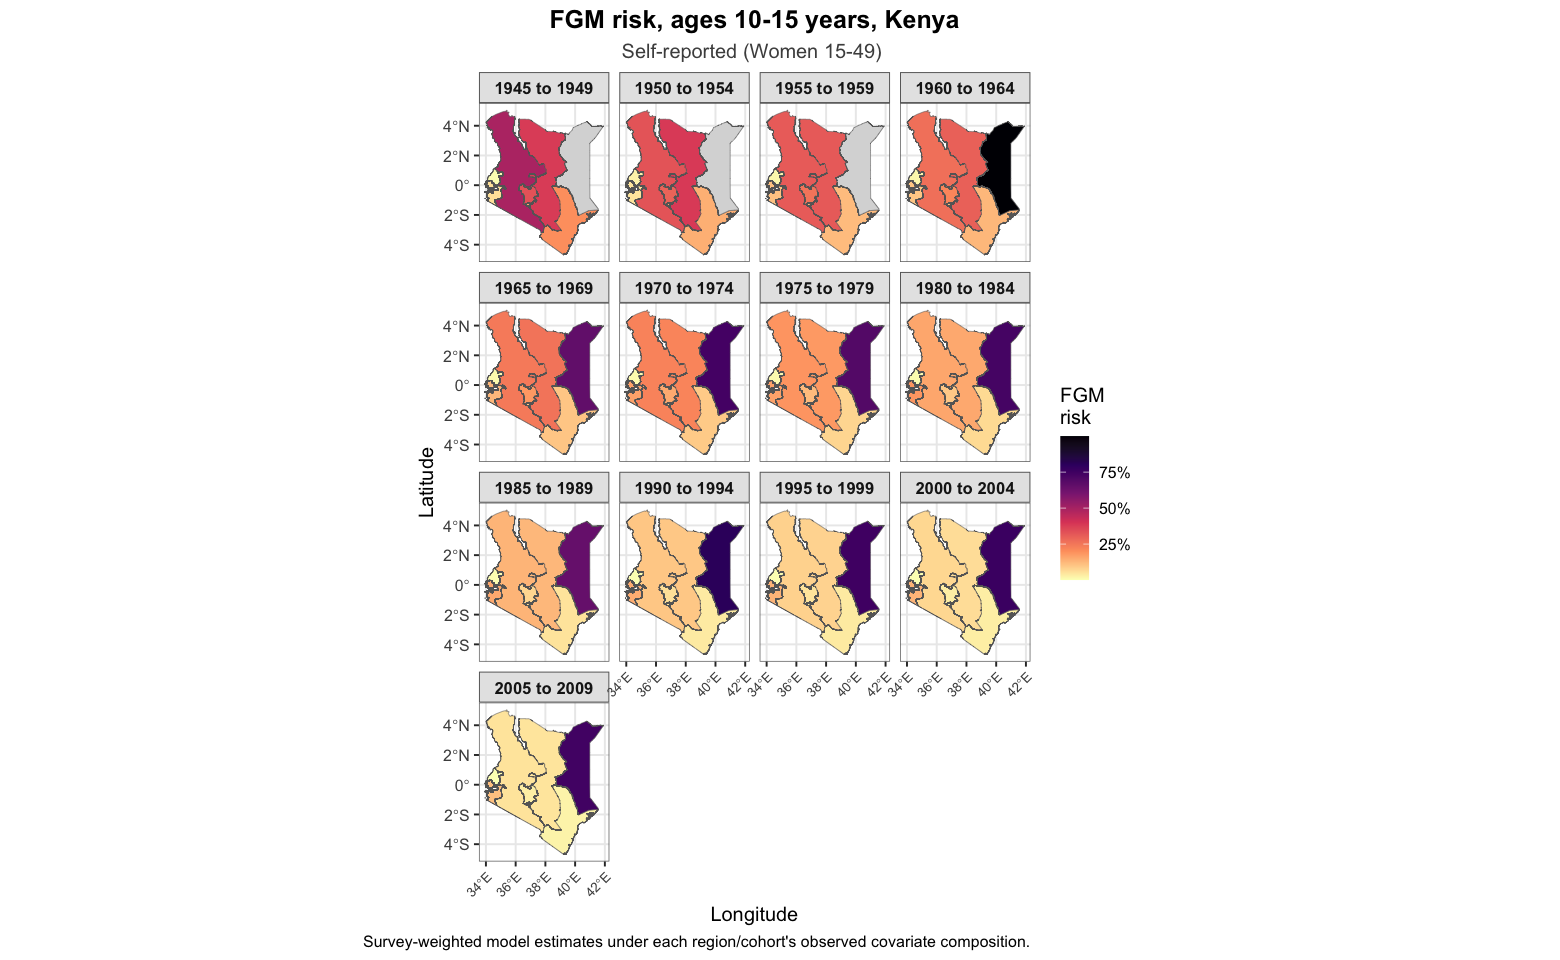

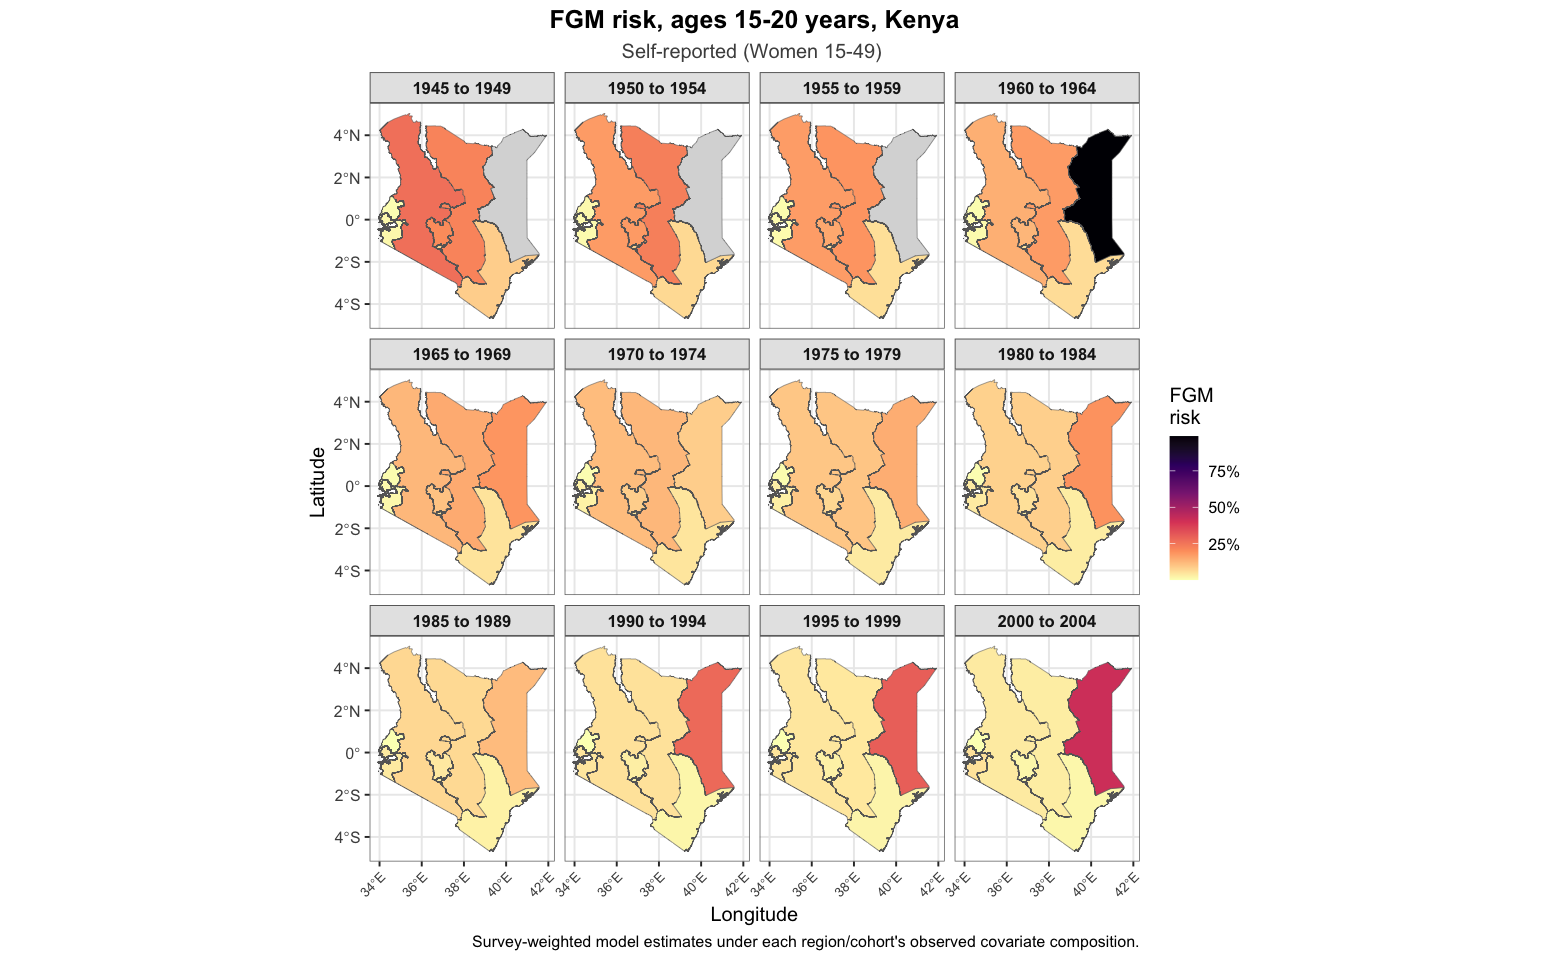

Covariate-adjusted risk maps and estimates: ../03_Outputs/KEN/Risk/05_Covariate_Adjusted_Maps 


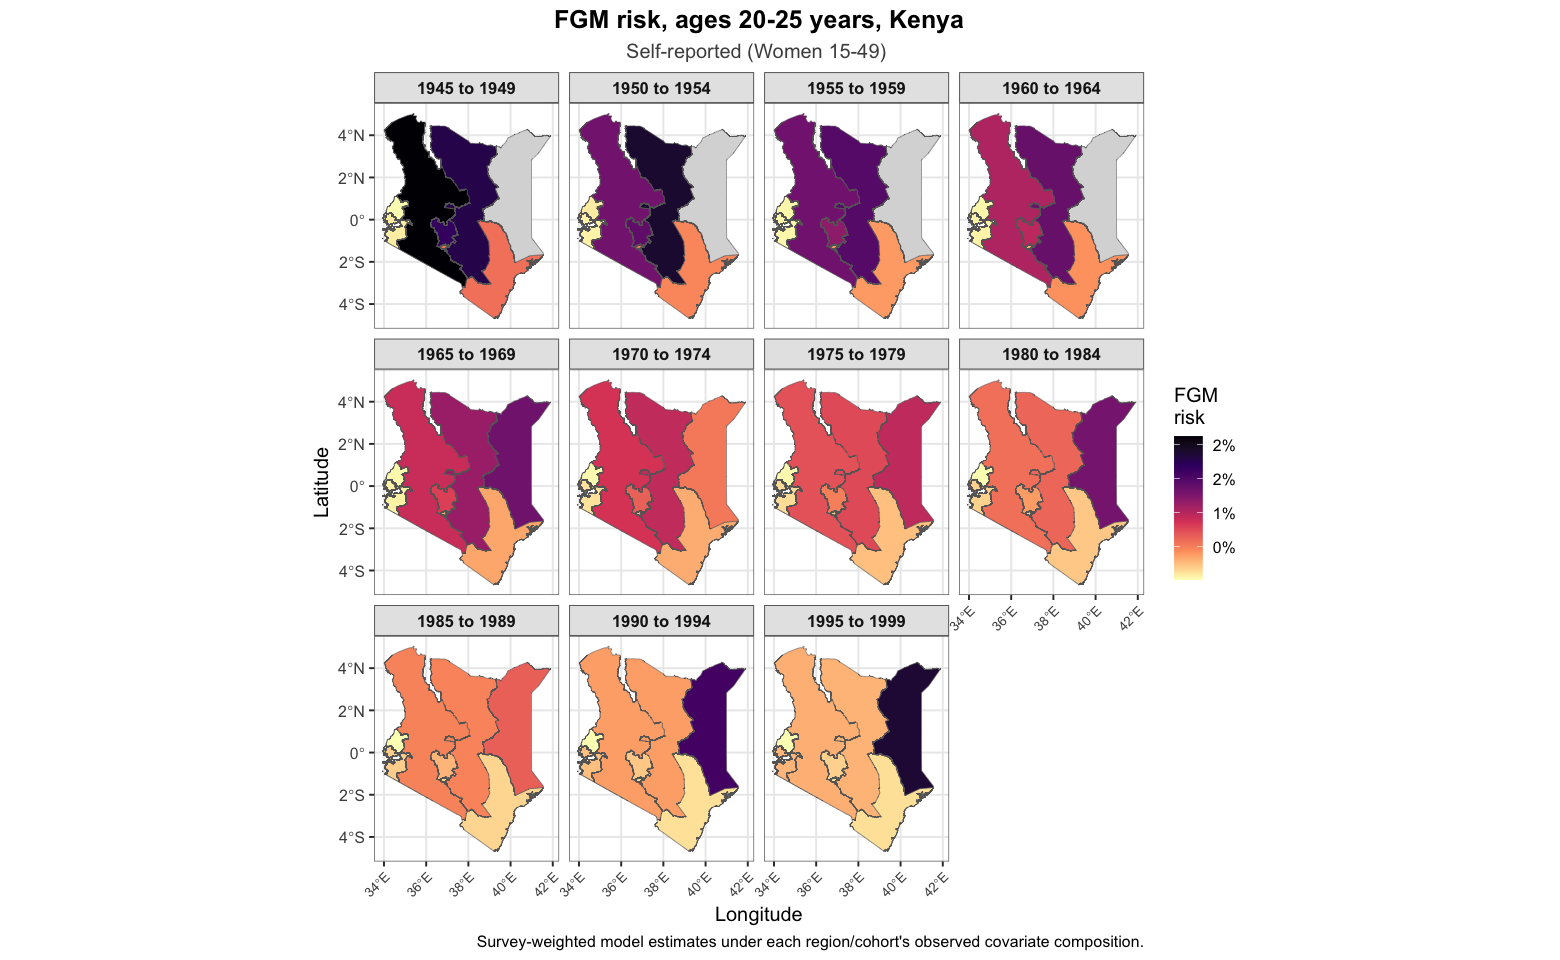

In [19]:
if (run_spatial_model) {
  for (geo_cov_band in age_band_levels) {
    for (geo_cov_source in names(geo_cov_results)) {
      geo_cov_map_data <- geo_cov_results[[geo_cov_source]] |>
        dplyr::filter(age_band == geo_cov_band) |>
        dplyr::mutate(
          smoothed_risk = adjusted_risk,
          birth_cohort = dplyr::if_else(is_provisional,
                                        paste0(birth_cohort, "\n(provisional)"), birth_cohort),
          birth_cohort = factor(birth_cohort, levels = sort(unique(birth_cohort))))
      if (!nrow(geo_cov_map_data)) next
      geo_cov_source_label <- if (geo_cov_source == "self")
        "Self-reported (Women 15-49)" else "Daughter-reported (Girls 0-14)"
      # Reuse the exact original map function: four cohort panels per row,
      # reversed magma palette, boundaries, axes, typography and 12 x 8 export.
      geo_cov_plot <- make_cohort_map_for_band(
        geo_cov_map_data, geo_cov_band,
        paste0(geo_cov_source_label, " ")) +
        ggplot2::labs(
          title = paste0("FGM risk, ages ", geo_cov_band,
                         " years, ", country_name),
          caption = if (any(geo_cov_map_data$is_provisional))
            "Provisional cohort: risk only to each region's observed age; not a completed age-band estimate."
          else "Survey-weighted model estimates under each region/cohort's observed covariate composition.")
      print(geo_cov_plot)
      ggplot2::ggsave(file.path(geo_cov_output_dir,
        paste0(country_iso3, "_covariate_adjusted_map_ages_", geo_cov_band, "_", geo_cov_source, ".png")),
        plot = geo_cov_plot, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
  cat("Covariate-adjusted risk maps and estimates:", geo_cov_output_dir, "\n")
}

## 13. Lexis heatmap

Weighted annual hazard by five-year age band and birth cohort, pooling all rounds.

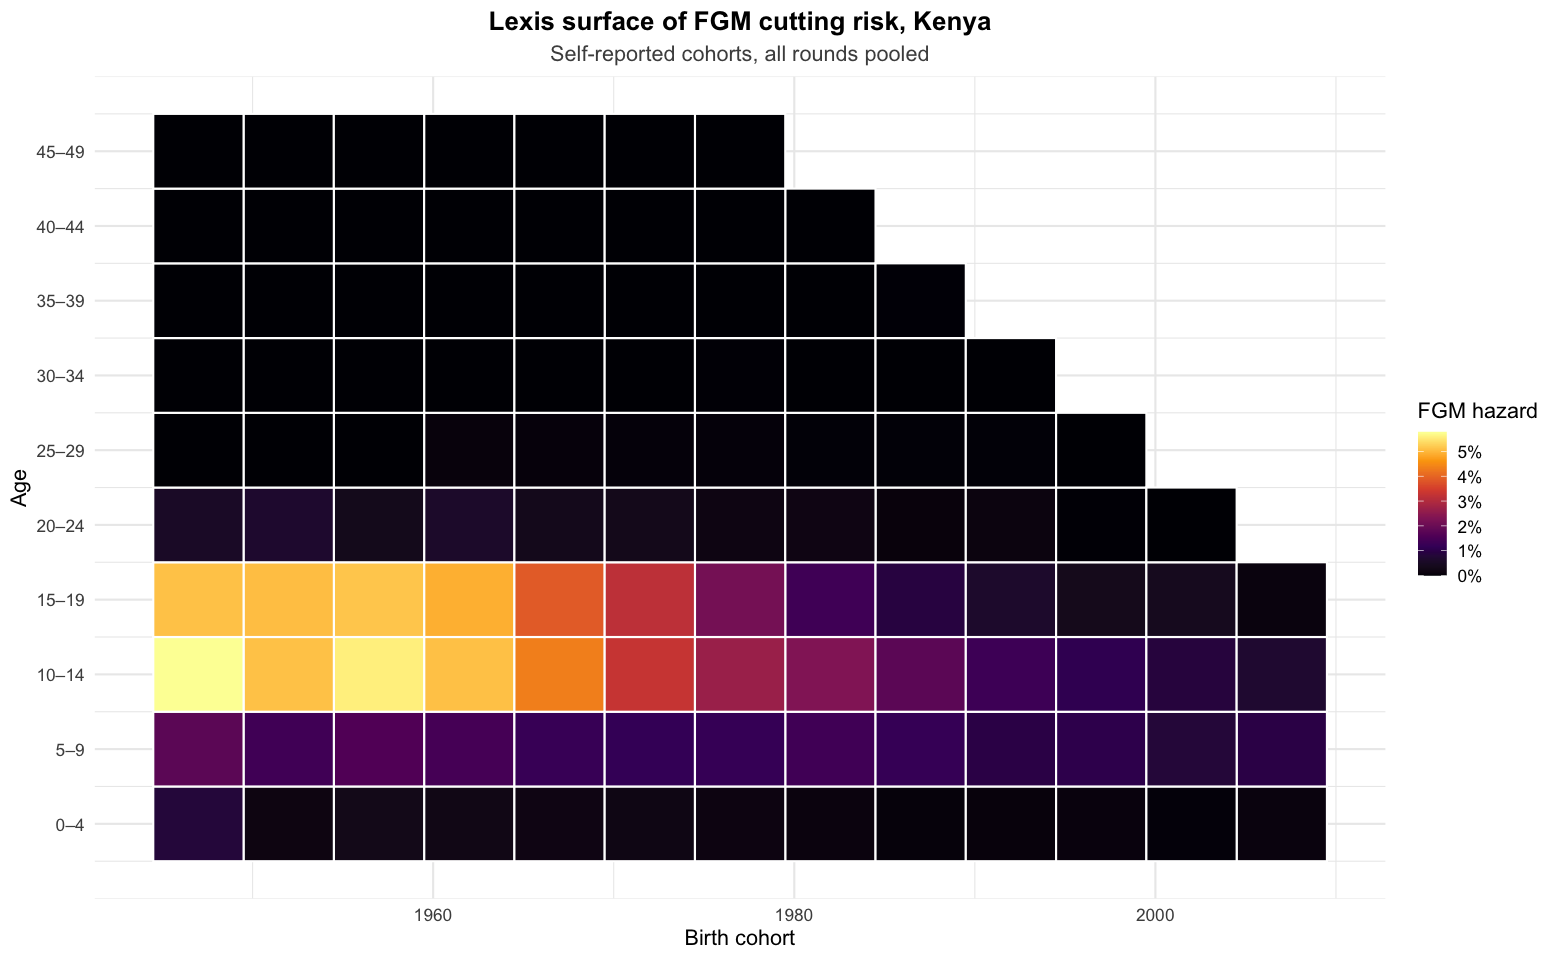

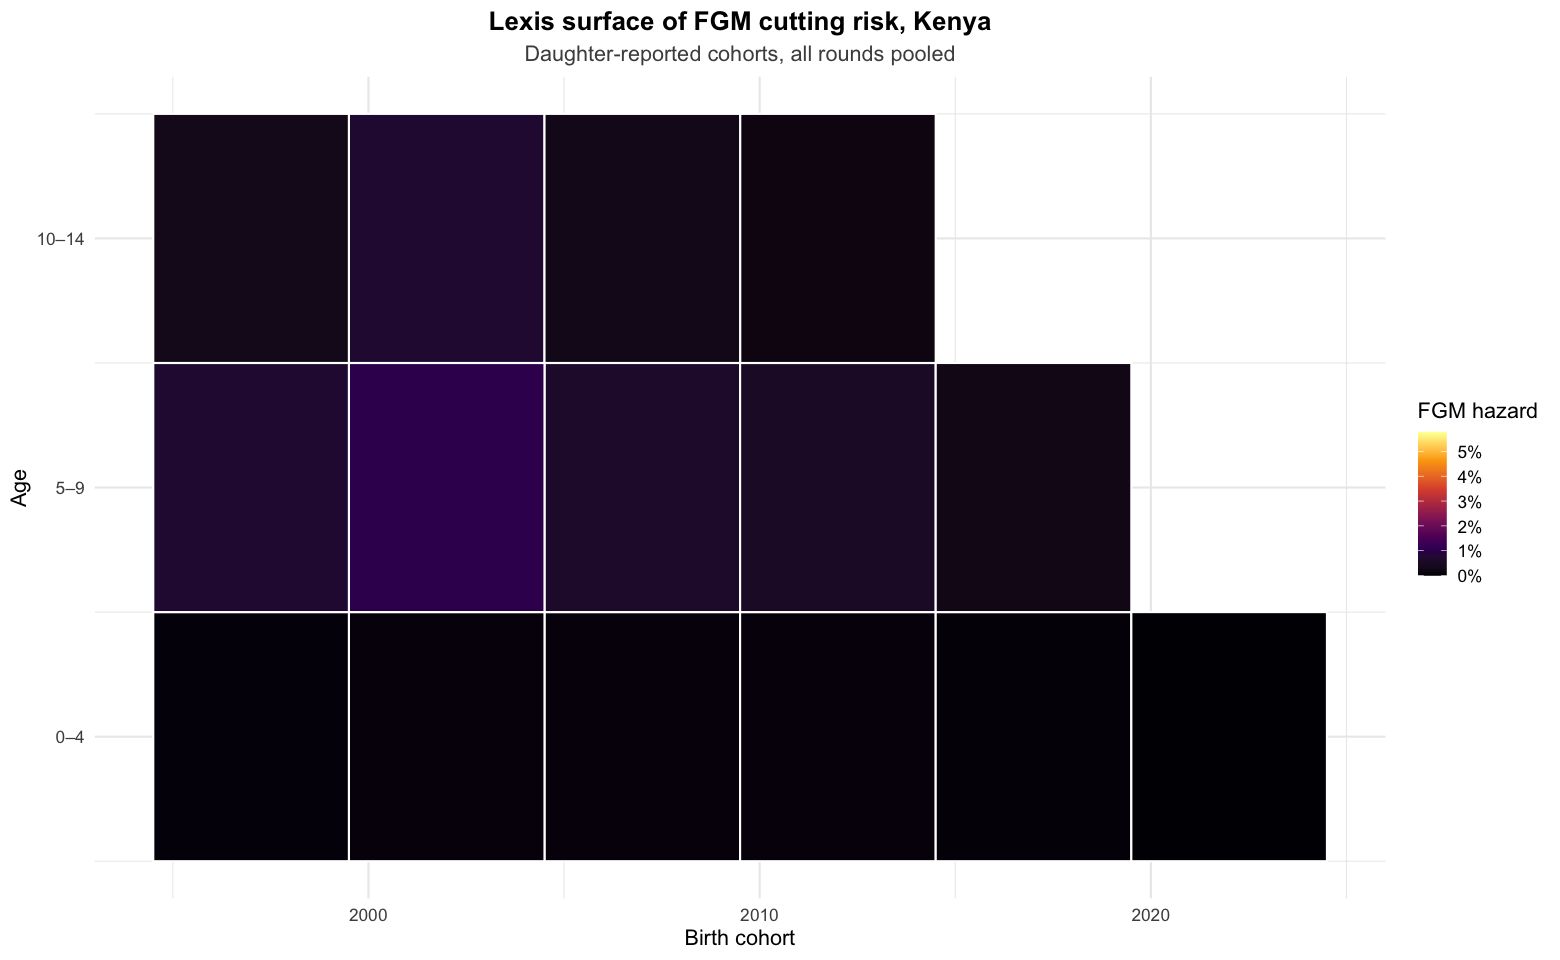

In [20]:
lexis_grid <- lapply(py_cohort, function(py) {
  py[, .(w_risk = sum(w_risk), w_event = sum(w_event)), by = .(birth_cohort, age_year)][
    , age_band_mid := floor(age_year / 5) * 5 + 2.5][
    , .(hazard = sum(w_event) / sum(w_risk)), by = .(birth_cohort, age_band_mid)][
    , cohort_mid := as.numeric(substr(as.character(birth_cohort), 1, 4)) + 2]
})
lexis_grid_self <- lexis_grid$self
lexis_grid_daughter <- lexis_grid$daughter
hazard_limits <- range(c(lexis_grid_self$hazard, lexis_grid_daughter$hazard), na.rm = TRUE)

build_lexis_plot <- function(grid, subtitle_label, file_suffix) {
  p <- ggplot2::ggplot(grid, ggplot2::aes(cohort_mid, age_band_mid, fill = hazard)) +
    ggplot2::geom_tile(width = 5, height = 5, color = "white", linewidth = 0.6) +
    ggplot2::scale_fill_viridis_c(name = "FGM hazard", option = "inferno", labels = scales::percent,
                                  limits = hazard_limits, oob = scales::squish) +
    ggplot2::scale_y_continuous(breaks = seq(2.5, 47.5, by = 5), labels = paste0(seq(0, 45, by = 5), "\u2013", seq(4, 49, by = 5))) +
    ggplot2::labs(title = paste("Lexis surface of FGM cutting risk,", country_name),
                  subtitle = subtitle_label, x = "Birth cohort", y = "Age") +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"))
  print(p)
  ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_lexis_heatmap_", file_suffix, ".png")), p, width = 9, height = 6, dpi = 300, bg = "white")
  p
}
lexis_plot_self <- build_lexis_plot(lexis_grid_self, "Self-reported cohorts, all rounds pooled", "self")
lexis_plot_daughter <- build_lexis_plot(lexis_grid_daughter, "Daughter-reported cohorts, all rounds pooled", "daughter")

## 13A. National trend by birth cohort

Pooled survey-weighted Kaplan–Meier risk per age band and cohort, with linearized 95%
intervals (V1 method). Bands are shown only when the cohort's follow-up reaches the
band's upper age; the youngest daughter cohort is shown as a provisional point.

Pooled KM trend matches survfit() in 71 cohort/band cells


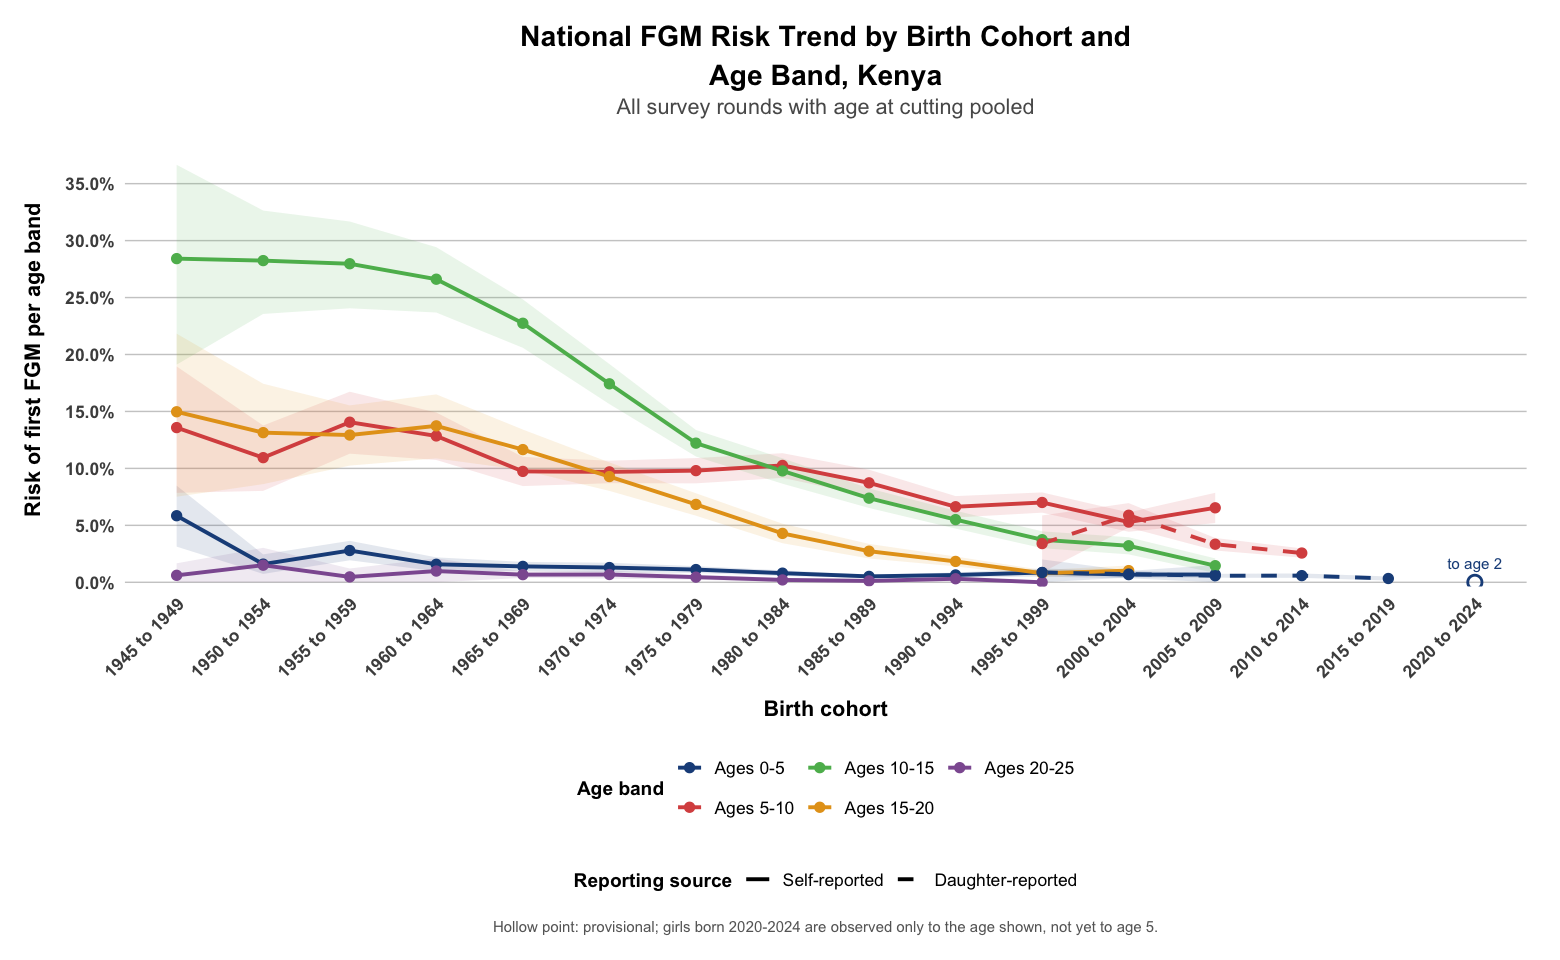

In [21]:
national_km <- function(record_label, domain_vars = "birth_cohort") {
  d <- fgm_events |> dplyr::filter(record_type == record_label)
  followup <- d |> dplyr::group_by(dplyr::across(dplyr::all_of(domain_vars))) |>
    dplyr::summarise(max_observed = max(time), .groups = "drop")
  py <- py_cohort[[record_label]][, .(w_risk = sum(w_risk), w_event = sum(w_event)),
                                  by = c("cluster", "strata", domain_vars, "age_year")]
  tibble::as_tibble(km_band_risk(py, domain_vars, age_band_cutpoints, followup, design_psus[[record_label]])) |>
    dplyr::mutate(record_type = record_label)
}
national_km_trend <- dplyr::bind_rows(national_km("self"), national_km("daughter")) |>
  dplyr::mutate(birth_cohort = as.character(birth_cohort), mean_risk = risk)

# Point estimates must equal the pooled weighted Kaplan-Meier from survfit().
check <- purrr::map_dfr(c("self", "daughter"), function(rt) {
  fit <- if (rt == "self") km_fit_self else km_fit_daughter
  tidy <- broom::tidy(fit) |> dplyr::mutate(birth_cohort = stringr::str_remove(strata, "^birth_cohort="))
  s_at <- function(coh, t) { x <- tidy |> dplyr::filter(birth_cohort == coh, time <= t); if (!nrow(x)) 1 else x$estimate[nrow(x)] }
  national_km_trend |> dplyr::filter(record_type == rt, supported) |>
    dplyr::rowwise() |> dplyr::mutate(survfit_risk = 1 - s_at(birth_cohort, hi) / (if (lo == 0) 1 else s_at(birth_cohort, lo))) |>
    dplyr::ungroup()
})
stopifnot(max(abs(check$survfit_risk - check$risk)) < 1e-8)
cat("Pooled KM trend matches survfit() in", nrow(check), "cohort/band cells\n")
readr::write_csv(national_km_trend |> dplyr::select(record_type, birth_cohort, age_band, mean_risk, lower_ci, upper_ci, supported, max_observed),
                 file.path(dirs$trends, paste0(country_iso3, "_national_km_trend.csv")))

trend_all_bands <- national_km_trend |>
  dplyr::filter(supported) |>
  dplyr::mutate(record_type = factor(dplyr::recode(record_type, self = "Self-reported", daughter = "Daughter-reported"),
                                     levels = c("Self-reported", "Daughter-reported")),
                age_band = factor(age_band, levels = age_band_levels, labels = paste("Ages", age_band_levels)))
provisional_points <- national_km_trend |>
  dplyr::filter(!supported, lo == 0, n_ages > 0) |>
  dplyr::transmute(birth_cohort, mean_risk = 1 - exp(log_surv), observed_to_age = max_observed,
                   record_type = factor(dplyr::recode(record_type, self = "Self-reported", daughter = "Daughter-reported"),
                                        levels = levels(trend_all_bands$record_type)),
                   age_band = factor("Ages 0-5", levels = levels(trend_all_bands$age_band)))
cohort_levels_all <- sort(unique(c(trend_all_bands$birth_cohort, provisional_points$birth_cohort)))
trend_all_bands$birth_cohort <- factor(trend_all_bands$birth_cohort, levels = cohort_levels_all)
provisional_points$birth_cohort <- factor(provisional_points$birth_cohort, levels = cohort_levels_all)

age_band_colors <- c("Ages 0-5" = "#1D4E89", "Ages 5-10" = "#D9534F", "Ages 10-15" = "#5CB85C",
                     "Ages 15-20" = "#E5A11C", "Ages 20-25" = "#8E5DA0")
trend_plot_all_bands <- ggplot2::ggplot(trend_all_bands,
    ggplot2::aes(birth_cohort, mean_risk, color = age_band, linetype = record_type, group = interaction(age_band, record_type))) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower_ci, ymax = upper_ci, fill = age_band), alpha = 0.12, color = NA, show.legend = FALSE) +
  ggplot2::geom_line(linewidth = 1.1) + ggplot2::geom_point(size = 2.4) +
  ggplot2::geom_point(data = provisional_points, ggplot2::aes(birth_cohort, mean_risk, color = age_band),
                      shape = 1, size = 3.2, stroke = 1.2, inherit.aes = FALSE, show.legend = FALSE) +
  ggplot2::geom_text(data = provisional_points, ggplot2::aes(birth_cohort, mean_risk, color = age_band,
                     label = paste0("to age ", observed_to_age)), vjust = -1.3, size = 3.2, inherit.aes = FALSE, show.legend = FALSE) +
  ggplot2::scale_color_manual(values = age_band_colors, name = "Age band") +
  ggplot2::scale_fill_manual(values = age_band_colors, guide = "none") +
  ggplot2::scale_linetype_manual(values = c("Self-reported" = "solid", "Daughter-reported" = "dashed"), name = "Reporting source") +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1), limits = c(0, NA),
                              breaks = scales::pretty_breaks(n = 6), expand = ggplot2::expansion(mult = c(0.01, 0.08))) +
  ggplot2::labs(title = stringr::str_wrap(paste("National FGM Risk Trend by Birth Cohort and Age Band,", country_name), width = 45),
                subtitle = "All survey rounds with age at cutting pooled",
                caption = if (nrow(provisional_points)) "Hollow point: provisional; girls born 2020-2024 are observed only to the age shown, not yet to age 5." else NULL,
                x = "Birth cohort", y = "Risk of first FGM per age band") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = 0.5, lineheight = 1.15, margin = ggplot2::margin(b = 4)),
    plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35", margin = ggplot2::margin(b = 8)),
    plot.caption = ggplot2::element_text(size = 9, color = "grey40", hjust = 0.5, margin = ggplot2::margin(t = 10)),
    axis.title.x = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(t = 12)),
    axis.title.y = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(r = 12)),
    axis.text.x = ggplot2::element_text(face = "bold", angle = 45, hjust = 1, vjust = 1, size = 10.5),
    axis.text.y = ggplot2::element_text(face = "bold", size = 10.5),
    legend.position = "bottom", legend.box = "vertical",
    legend.title = ggplot2::element_text(face = "bold", size = 11.5), legend.text = ggplot2::element_text(size = 10.5),
    panel.grid.major.x = ggplot2::element_blank(), panel.grid.minor = ggplot2::element_blank(),
    panel.grid.major.y = ggplot2::element_line(color = "grey80", linewidth = 0.4),
    plot.margin = ggplot2::margin(t = 15, r = 20, b = 15, l = 15)) +
  ggplot2::guides(color = ggplot2::guide_legend(order = 1, nrow = 2), linetype = ggplot2::guide_legend(order = 2))
print(trend_plot_all_bands)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_national_risk_trend_all_bands.png")),
                trend_plot_all_bands, width = 12, height = 8, dpi = 300, bg = "white")

## 13B. Trend by survey round

The same cohort's cumulative risk estimated separately in each round: by age 15 for women's own
reports and by age 10 for mothers' reports on daughters. Agreement between rounds that observe
the same cohort indicates consistent reporting; systematic gaps between early and late rounds
indicate reporting differences rather than real change. Cohorts not yet followed to the key age
in a round are not shown.

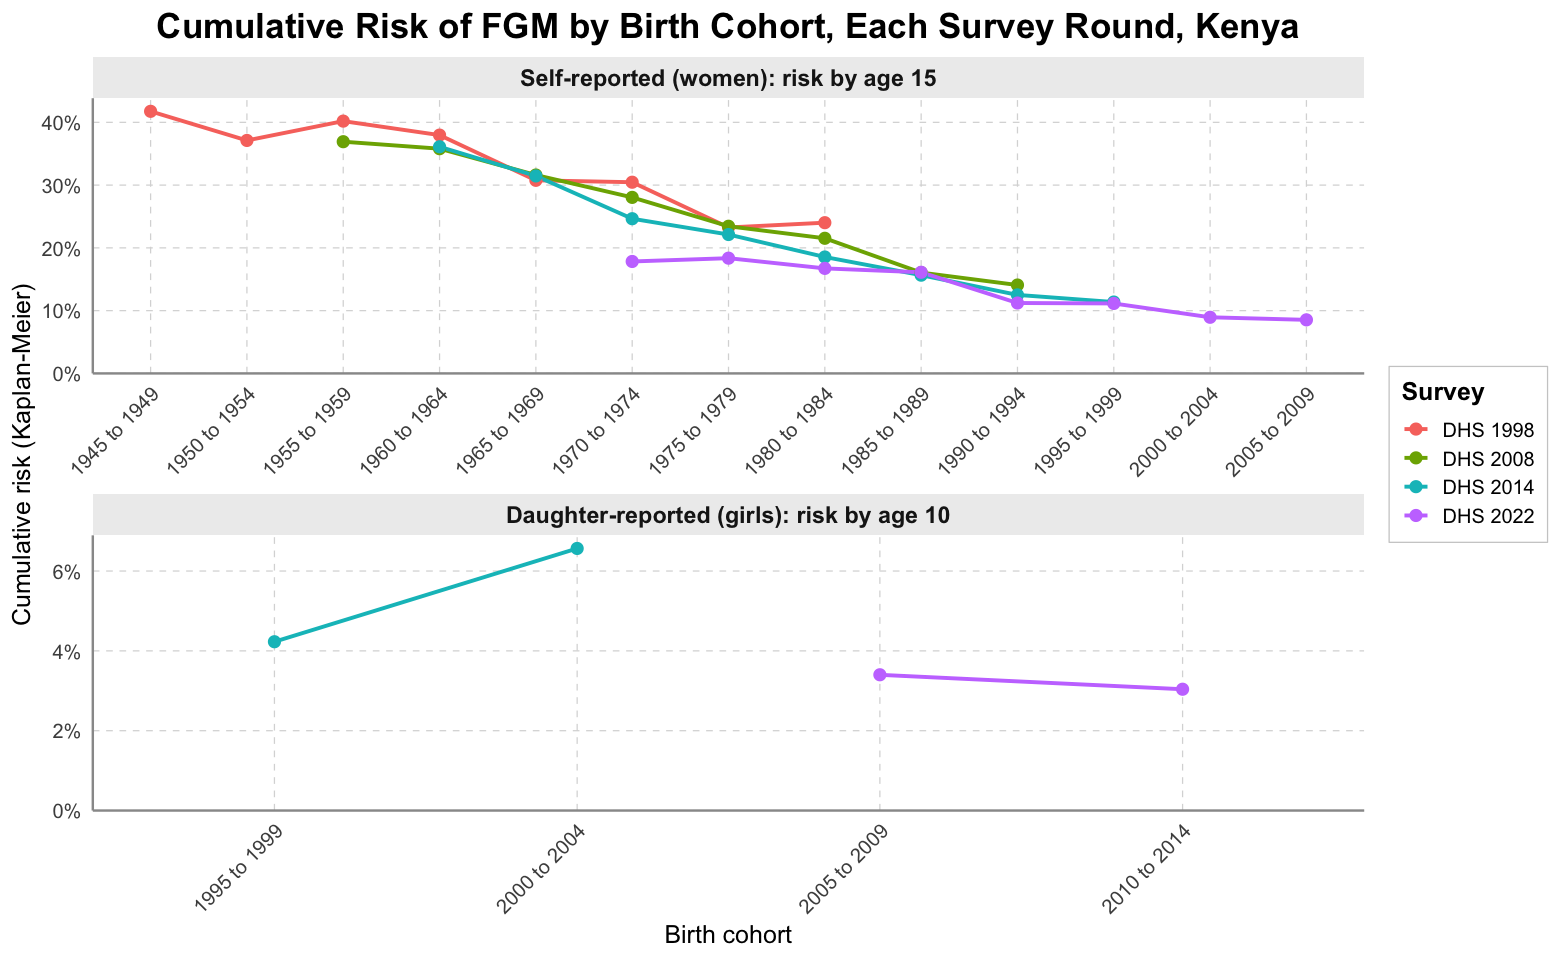

In [22]:
key_age_self <- 15L       # most cutting in Kenya happens at ages 5-15
key_age_daughter <- 10L   # daughters are observed only to age 14
km_by_age <- function(d, domain, a) {
  psus <- data.table::as.data.table(d)[, .(cluster = unique(cluster)), by = strata][, .(n_h = .N), by = strata]
  py <- aggregate_person_years(d, domain, max_age = a)
  fu <- d |> dplyr::group_by(dplyr::across(dplyr::all_of(domain))) |>
    dplyr::summarise(max_observed = max(time), n = sum(age_share), .groups = "drop")
  tibble::as_tibble(km_band_risk(py, domain, c(0, a), fu |> dplyr::select(-n), psus)) |>
    dplyr::left_join(fu |> dplyr::select(-max_observed), by = domain) |>
    dplyr::filter(supported) |>
    dplyr::transmute(dplyr::across(dplyr::all_of(domain), as.character), risk, lower_ci, upper_ci, n)
}
self_label <- paste0("Self-reported (women): risk by age ", key_age_self)
daughter_label <- paste0("Daughter-reported (girls): risk by age ", key_age_daughter)
by_round_all <- dplyr::bind_rows(
  km_by_age(fgm_events |> dplyr::filter(record_type == "self"), c("survey_id", "birth_cohort"), key_age_self) |>
    dplyr::mutate(record_type = self_label),
  km_by_age(fgm_events |> dplyr::filter(record_type == "daughter"), c("survey_id", "birth_cohort"), key_age_daughter) |>
    dplyr::mutate(record_type = daughter_label)) |>
  dplyr::left_join(fgm_events |> dplyr::distinct(survey_id, survey_type), by = "survey_id") |>
  dplyr::mutate(record_type = factor(record_type, levels = c(self_label, daughter_label)),
                risk_plot = risk, provisional = FALSE,
                survey_id = factor(survey_id, levels = c("DHS 1998", "DHS 2008", "DHS 2014", "DHS 2022")))
readr::write_csv(by_round_all |> dplyr::select(record_type, survey_id, survey_type, birth_cohort, risk, lower_ci, upper_ci, n),
                 file.path(dirs$trends, paste0(country_iso3, "_risk_by_round_and_cohort.csv")))
by_round <- by_round_all

round_trend_plot <- ggplot2::ggplot(by_round, ggplot2::aes(birth_cohort, risk_plot, color = survey_id, group = survey_id)) +
  ggplot2::geom_line(linewidth = 1.1) +
  ggplot2::geom_point(size = 2.8) +
  ggplot2::facet_wrap(~record_type, ncol = 1, scales = "free") +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA),
                              expand = ggplot2::expansion(mult = c(0, 0.05))) +
  ggplot2::labs(title = paste("Cumulative Risk of FGM by Birth Cohort, Each Survey Round,", country_name),
                x = "Birth cohort", y = "Cumulative risk (Kaplan-Meier)", color = "Survey") +
  ggplot2::theme_minimal(base_size = 15) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 21, hjust = 0.5),
                 strip.text = ggplot2::element_text(face = "bold", size = 14),
                 strip.background = ggplot2::element_rect(fill = "grey93", color = NA),
                 panel.grid.major = ggplot2::element_line(color = "grey85", linetype = "dashed", linewidth = 0.35),
                 panel.grid.minor = ggplot2::element_blank(),
                 axis.line = ggplot2::element_line(color = "grey60"),
                 axis.text.x = ggplot2::element_text(angle = 45, hjust = 1),
                 legend.title = ggplot2::element_text(face = "bold"),
                 legend.box.background = ggplot2::element_rect(color = "grey80", fill = "white"))
print(round_trend_plot)
ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_risk_by_round_and_cohort.png")),
                round_trend_plot, width = 16, height = 10, dpi = 300, bg = "white")

## 14. Change point analysis

Mean self-reported annual hazard over ages 0–14 by birth cohort, pooling all rounds, with
PELT change-point detection (V1 method).

# A tibble: 1 × 4
  country basis                                                           changepoint_detected estimated_change_cohort
  <chr>   <chr>                                                           <lgl>                                  <dbl>
1 Kenya   self-reported cohorts, all rounds, mean annual hazard ages 0-14 FALSE                                     NA


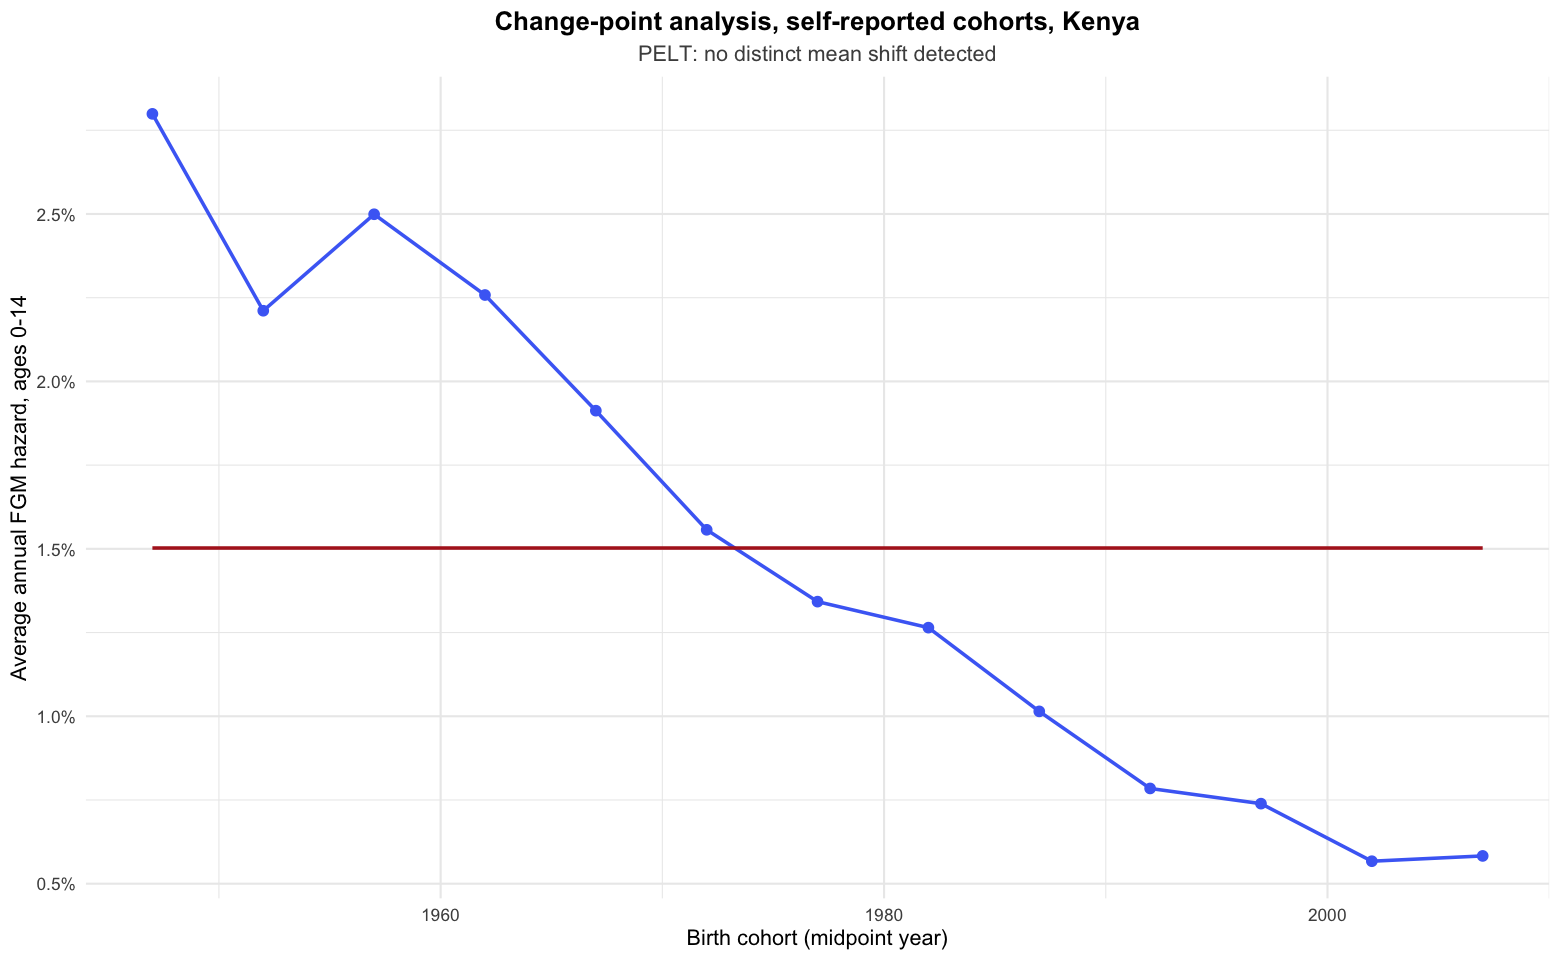

In [23]:
if (run_change_point) {
  suppressPackageStartupMessages(library(changepoint))
  cohort_series <- lexis_grid_self |>
    dplyr::filter(age_band_mid < 15) |>
    dplyr::group_by(cohort_mid) |>
    dplyr::summarise(mean_hazard = mean(hazard, na.rm = TRUE), .groups = "drop") |>
    dplyr::arrange(cohort_mid)
  cpt_result <- changepoint::cpt.mean(cohort_series$mean_hazard, method = "PELT")
  n_segments <- length(cpt_result@cpts)
  change_point_estimate <- tibble::tibble(
    country = country_name, basis = "self-reported cohorts, all rounds, mean annual hazard ages 0-14",
    changepoint_detected = n_segments > 1,
    estimated_change_cohort = if (n_segments > 1) cohort_series$cohort_mid[cpt_result@cpts[1]] else NA_real_)
  readr::write_csv(change_point_estimate, file.path(dirs$trends, paste0(country_iso3, "_change_point.csv")))
  print(change_point_estimate)
  cohort_series_plot <- cohort_series |>
    dplyr::mutate(segment = cut(dplyr::row_number(), breaks = c(0, cpt_result@cpts), labels = FALSE)) |>
    dplyr::group_by(segment) |> dplyr::mutate(segment_mean = mean(mean_hazard)) |> dplyr::ungroup()
  cpt_plot <- ggplot2::ggplot(cohort_series_plot, ggplot2::aes(cohort_mid, mean_hazard)) +
    ggplot2::geom_line(color = "#4C6EF5", linewidth = 1) + ggplot2::geom_point(size = 2.5, color = "#4C6EF5") +
    ggplot2::geom_line(ggplot2::aes(y = segment_mean, group = segment), color = "firebrick", linewidth = 1) +
    ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
    ggplot2::labs(title = paste("Change-point analysis, self-reported cohorts,", country_name),
                  subtitle = if (n_segments > 1) paste("PELT: shift after the", cohort_series_plot$cohort_mid[cpt_result@cpts[1]], "cohort")
                             else "PELT: no distinct mean shift detected",
                  x = "Birth cohort (midpoint year)", y = "Average annual FGM hazard, ages 0-14") +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                   plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"))
  print(cpt_plot)
  ggplot2::ggsave(file.path(dirs$trends, paste0(country_iso3, "_change_point.png")), cpt_plot, width = 9, height = 5.5, dpi = 300, bg = "white")
}

## 15. Descriptive model comparison

Conditional risk within each age band from the pooled national Kaplan–Meier, the direct
regional estimates (weighted average of complete cells) and the spatial model. Aggregation
and eligible cohorts differ, so agreement is descriptive.

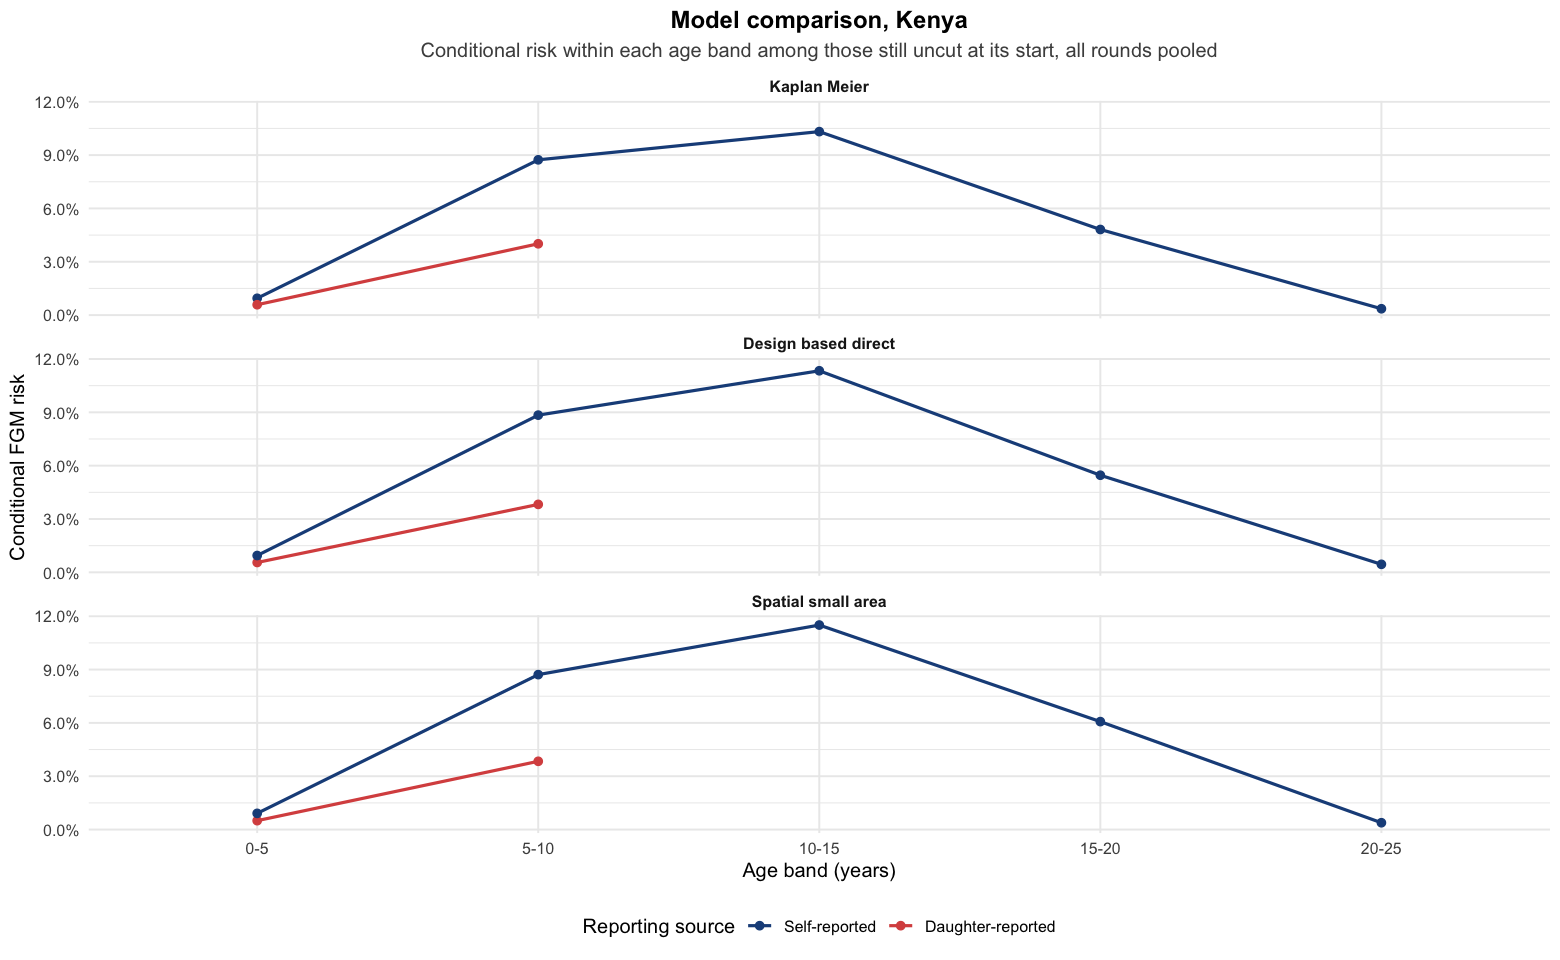

In [24]:
km_overall <- function(record_label) {
  py <- py_cohort[[record_label]][, .(w_risk = sum(w_risk), w_event = sum(w_event)), by = .(cluster, strata, age_year)][
    , national := country_name]
  followup <- tibble::tibble(national = country_name,
                             max_observed = max(fgm_events$time[fgm_events$record_type == record_label]))
  tibble::as_tibble(km_band_risk(py, "national", age_band_cutpoints, followup, design_psus[[record_label]])) |>
    dplyr::transmute(age_band, fgm_risk = risk, record_type = record_label, model = "Kaplan Meier")
}
km_national <- dplyr::bind_rows(km_overall("self"), km_overall("daughter"))
direct_national <- dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
  dplyr::filter(is_complete) |>
  dplyr::group_by(age_band, record_type) |>
  dplyr::summarise(fgm_risk = weighted.mean(event, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(model = "Design based direct")
spatial_national <- if (run_spatial_model) {
  dplyr::bind_rows(smoothed_by_band_self |> dplyr::mutate(record_type = "self"),
                   smoothed_by_band_daughter |> dplyr::mutate(record_type = "daughter")) |>
    dplyr::group_by(age_band, record_type) |>
    dplyr::summarise(fgm_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
    dplyr::mutate(model = "Spatial small area")
} else tibble::tibble()
validation_comparison <- dplyr::bind_rows(km_national, direct_national, spatial_national) |>
  dplyr::mutate(age_band = factor(age_band, levels = age_band_levels),
                model = factor(model, levels = c("Kaplan Meier", "Design based direct", "Spatial small area")),
                record_type = factor(record_type, levels = c("self", "daughter"), labels = c("Self-reported", "Daughter-reported")))
validation_plot <- ggplot2::ggplot(validation_comparison, ggplot2::aes(age_band, fgm_risk, color = record_type, group = record_type)) +
  ggplot2::geom_line(linewidth = 0.9, na.rm = TRUE) + ggplot2::geom_point(size = 2, na.rm = TRUE) +
  ggplot2::facet_wrap(~model, ncol = 1) +
  ggplot2::scale_color_manual(values = c("Self-reported" = "#1D4E89", "Daughter-reported" = "#D9534F")) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
  ggplot2::labs(title = paste("Model comparison,", country_name),
                subtitle = "Conditional risk within each age band among those still uncut at its start, all rounds pooled",
                y = "Conditional FGM risk", x = "Age band (years)", color = "Reporting source") +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
                 strip.text = ggplot2::element_text(face = "bold"), legend.position = "bottom")
print(validation_plot)
ggplot2::ggsave(file.path(dirs$validation, paste0(country_iso3, "_model_comparison.png")), validation_plot, width = 9, height = 11, dpi = 300, bg = "white")
readr::write_csv(validation_comparison, file.path(dirs$validation, paste0(country_iso3, "_model_comparison.csv")))

## 15A. Check against direct estimates

(1) Pooled national Kaplan–Meier trend vs. the weighted average of complete regional direct
estimates, by cohort and band; (2) the 12A covariate model vs. regional direct estimates,
cell by cell.

In [25]:
direct_cohort_national <- dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
  dplyr::filter(is_complete, !is.na(event)) |>
  dplyr::group_by(record_type, birth_cohort = as.character(birth_cohort), age_band) |>
  dplyr::summarise(direct_risk = weighted.mean(event, w = sum_weight), n_regions = dplyr::n(), .groups = "drop")

trend_vs_direct <- national_km_trend |>
  dplyr::filter(supported) |>
  dplyr::inner_join(direct_cohort_national, by = c("record_type", "birth_cohort", "age_band")) |>
  dplyr::mutate(difference = mean_risk - direct_risk,
                direct_in_km_ci = direct_risk >= lower_ci & direct_risk <= upper_ci)
readr::write_csv(trend_vs_direct, file.path(dirs$validation, paste0(country_iso3, "_check_trend_vs_direct.csv")))
cat("National pooled KM vs. direct regional average (complete cells)\n")
print(trend_vs_direct |> dplyr::group_by(record_type, age_band) |>
  dplyr::summarise(cells = dplyr::n(), mean_diff_pp = 100 * mean(difference),
                   max_abs_diff_pp = 100 * max(abs(difference)), direct_within_ci = mean(direct_in_km_ci), .groups = "drop"))

if (run_spatial_model) {
  covariate_vs_direct <- dplyr::bind_rows(geo_cov_results) |>
    dplyr::filter(!is.na(adjusted_risk)) |>
    dplyr::inner_join(dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
                        dplyr::mutate(birth_cohort = as.character(birth_cohort)) |>
                        dplyr::select(record_type, region, birth_cohort, age_band, event, provisional_event),
                      by = c("record_type", "region", "birth_cohort", "age_band")) |>
    dplyr::mutate(direct_risk = dplyr::if_else(is_provisional, provisional_event, event),
                  difference = adjusted_risk - direct_risk,
                  direct_in_ci = direct_risk >= lower_ci & direct_risk <= upper_ci) |>
    dplyr::filter(!is.na(direct_risk))
  readr::write_csv(covariate_vs_direct, file.path(dirs$validation, paste0(country_iso3, "_check_covariate_model_vs_direct.csv")))
  cat("\n12A covariate model vs. regional direct estimates\n")
  print(covariate_vs_direct |> dplyr::group_by(record_type, age_band, is_provisional) |>
    dplyr::summarise(cells = dplyr::n(), mean_diff_pp = 100 * mean(difference), mean_abs_diff_pp = 100 * mean(abs(difference)),
                     correlation = if (dplyr::n() > 2) stats::cor(adjusted_risk, direct_risk) else NA_real_,
                     direct_within_ci = mean(direct_in_ci), .groups = "drop"))
}

National pooled KM vs. direct regional average (complete cells)


# A tibble: 7 × 6
  record_type age_band cells mean_diff_pp max_abs_diff_pp direct_within_ci
  <chr>       <chr>    <int>        <dbl>           <dbl>            <dbl>
1 daughter    0-5          5     4.26e- 3        1.10e- 2            1    
2 daughter    5-10         4    -3.43e- 1        4.20e- 1            1    
3 self        0-5         13     1.63e-15        7.81e-15            1    
4 self        10-15       13    -8.00e- 1        1.55e+ 0            0.692
5 self        15-20       12    -1.43e+ 0        5.63e+ 0            0.833
6 self        20-25       11    -5.41e- 1        3.66e+ 0            0.909
7 self        5-10        13    -1.31e- 1        6.74e- 1            1    



12A covariate model vs. regional direct estimates


Warning message:
“There was 1 warning in `dplyr::summarise()`.
ℹ In argument: `correlation = if (dplyr::n() > 2) stats::cor(adjusted_risk, direct_risk) else NA_real_`.
ℹ In group 2: `record_type = "daughter"`, `age_band = "0-5"`, `is_provisional = TRUE`.
Caused by warning in `stats::cor()`:
! the standard deviation is zero”


# A tibble: 8 × 8
  record_type age_band is_provisional cells mean_diff_pp mean_abs_diff_pp correlation direct_within_ci
  <chr>       <chr>    <lgl>          <int>        <dbl>            <dbl>       <dbl>            <dbl>
1 daughter    0-5      FALSE             40       1.35              2.58        0.831           0.4   
2 daughter    0-5      TRUE               8       0.608             0.608      NA               0     
3 daughter    5-10     FALSE             32       1.84              3.03        0.982           0.281 
4 self        0-5      FALSE            102       0.713             3.37        0.257           0.0784
5 self        10-15    FALSE            101      -0.0752            6.52        0.875           0.0891
6 self        15-20    FALSE             93      -0.651             6.37        0.706           0.0753
7 self        20-25    FALSE             84      -0.292             0.896       0.473           0.0476
8 self        5-10     FALSE            101       0.114

## 15B. Sensitivity analysis: reporting, age at interview and survey programme

Risk incidence rests on women recalling, and being willing to report, whether and when they
were cut, often decades earlier. Because each birth cohort is observed in several rounds, at
different ages and survey years, the pooled data can test how sensitive the estimates are to
age at interview and reporting source. Checks on women's own reports use the risk of being cut
by age 15 (Kaplan–Meier, survey-weighted); the comparison with mothers' reports uses risk by
age 10, because daughters are observed only to age 14.

1. **Same cohort across rounds** (section 13B, summarised here).
2. **Fixed age at interview:** each cohort estimated only from women interviewed at ages
   20–29, so every cohort is compared at the same distance from its childhood.
3. **Age at interview within cohort:** the same cohort reported at 15–24, 25–34 and 35–49.
4. **Women's own reports vs mothers' reports** (risk by age 10) for cohorts observed both ways.
5. **DHS vs MICS:** not possible, because Kenya has no national MICS; the subnational MICS
   are compared in section 15C.
6. **Age-at-cutting estimation:** risk with "during infancy" and unknown ages estimated (main
   analysis) versus restricted to exact reported ages.

In [26]:
km_by5 <- function(d, domain) km_by_age(d, domain, key_age_self)
self_events <- fgm_events |> dplyr::filter(record_type == "self") |>
  dplyr::mutate(age_at_interview = cut(age, c(14, 24, 34, 49), labels = c("15-24", "25-34", "35-49")))
pct <- function(x) round(100 * x, 1)

# 1. Same cohort across rounds (women's reports).
same_cohort <- by_round_all |> dplyr::filter(record_type == self_label) |>
  dplyr::transmute(birth_cohort, survey_id = as.character(survey_id), risk = pct(risk_plot)) |>
  tidyr::pivot_wider(names_from = survey_id, values_from = risk) |> dplyr::arrange(birth_cohort)

# 2-3. Fixed age at interview and age at interview within cohort.
all_ages <- km_by5(self_events, "birth_cohort") |> dplyr::select(birth_cohort, all_ages = risk)
age_20_29 <- km_by5(self_events |> dplyr::filter(age >= 20, age <= 29), "birth_cohort") |>
  dplyr::select(birth_cohort, age_20_29 = risk, age_20_29_lower = lower_ci, age_20_29_upper = upper_ci, age_20_29_n = n)
by_interview_age <- km_by5(self_events, c("birth_cohort", "age_at_interview")) |>
  dplyr::mutate(risk = pct(risk)) |> dplyr::select(birth_cohort, age_at_interview, risk) |>
  tidyr::pivot_wider(names_from = age_at_interview, values_from = risk, names_prefix = "interviewed_")

# 4. Women's own reports vs mothers' reports for the same birth cohorts.
own_by10 <- km_by_age(self_events, "birth_cohort", key_age_daughter) |>
  dplyr::select(birth_cohort, own_by10 = risk, own_by10_lower = lower_ci, own_by10_upper = upper_ci)
mothers <- km_by_age(fgm_events |> dplyr::filter(record_type == "daughter"), "birth_cohort", key_age_daughter) |>
  dplyr::select(birth_cohort, mothers_reports = risk, mothers_lower = lower_ci, mothers_upper = upper_ci)

# 5. DHS vs MICS, same cohorts.
programme <- if (all(c("DHS", "MICS") %in% self_events$survey_type)) {
  km_by5(self_events, c("survey_type", "birth_cohort")) |> dplyr::mutate(risk = pct(risk)) |>
    dplyr::select(survey_type, birth_cohort, risk) |> tidyr::pivot_wider(names_from = survey_type, values_from = risk) |>
    dplyr::filter(!is.na(DHS), !is.na(MICS)) |> dplyr::mutate(DHS_minus_MICS = DHS - MICS)
} else tibble::tibble(note = "Kenya has no national MICS; its subnational MICS are compared in section 15C. No DHS-MICS comparison of national cohorts is possible.")

# 6. Exact reported ages only (drops estimated ages; biased downward, shown for comparison).
by_type <- function(d, a_self, a_daughter) dplyr::bind_rows(
  km_by_age(d |> dplyr::filter(record_type == "self"), "birth_cohort", a_self) |> dplyr::mutate(record_type = "self", key_age = a_self),
  km_by_age(d |> dplyr::filter(record_type == "daughter"), "birth_cohort", a_daughter) |> dplyr::mutate(record_type = "daughter", key_age = a_daughter))
exact_only <- by_type(fgm_events |> dplyr::filter(age_source %in% c("not cut", "exact age reported")), key_age_self, key_age_daughter) |>
  dplyr::select(record_type, key_age, birth_cohort, exact_ages_only = risk)
main_estimate <- by_type(fgm_events, key_age_self, key_age_daughter) |> dplyr::select(record_type, key_age, birth_cohort, main = risk)
age_method <- main_estimate |> dplyr::inner_join(exact_only, by = c("record_type", "key_age", "birth_cohort")) |>
  dplyr::mutate(difference_pp = pct(main - exact_ages_only), main = pct(main), exact_ages_only = pct(exact_ages_only))

sensitivity_table <- all_ages |> dplyr::full_join(age_20_29, by = "birth_cohort") |>
  dplyr::full_join(own_by10, by = "birth_cohort") |>
  dplyr::full_join(mothers, by = "birth_cohort") |> dplyr::arrange(birth_cohort) |>
  dplyr::mutate(dplyr::across(where(is.numeric) & !dplyr::ends_with("_n"), pct))
readr::write_csv(same_cohort, file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_same_cohort_by_round.csv")))
readr::write_csv(sensitivity_table, file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_fixed_age_and_mothers.csv")))
readr::write_csv(by_interview_age, file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_by_age_at_interview.csv")))
readr::write_csv(programme, file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_dhs_vs_mics.csv")))
readr::write_csv(age_method, file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_age_at_cutting_method.csv")))

cat("1. Same cohort, risk by age 15 (%) in each round\n"); IRdisplay::display(as.data.frame(same_cohort))
cat("2/4. Risk by age 15: all ages vs interviewed at 20-29; risk by age 10: own vs mothers' reports (%)\n"); IRdisplay::display(as.data.frame(sensitivity_table))
cat("3. By age at interview (%)\n"); IRdisplay::display(as.data.frame(by_interview_age))
cat("5. DHS vs MICS (%)\n"); IRdisplay::display(as.data.frame(programme))
cat("6. Age-at-cutting estimation vs exact ages only (%)\n"); IRdisplay::display(as.data.frame(age_method))

1. Same cohort, risk by age 15 (%) in each round


birth_cohort,DHS 1998,DHS 2008,DHS 2014,DHS 2022
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1945 to 1949,41.8,NA,NA,NA
1950 to 1954,37.1,NA,NA,NA
1955 to 1959,40.2,36.9,NA,NA
1960 to 1964,38.0,35.8,36.1,NA
1965 to 1969,30.8,31.6,31.5,NA
1970 to 1974,30.5,28.0,24.6,17.8
1975 to 1979,23.3,23.4,22.1,18.4
1980 to 1984,24.0,21.5,18.5,16.7
1985 to 1989,NA,16.1,15.7,16.1


2/4. Risk by age 15: all ages vs interviewed at 20-29; risk by age 10: own vs mothers' reports (%)


birth_cohort,all_ages,age_20_29,age_20_29_lower,age_20_29_upper,age_20_29_n,own_by10,own_by10_lower,own_by10_upper,mothers_reports,mothers_lower,mothers_upper
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1945 to 1949,41.8,NA,NA,NA,NA,18.6,12.5,24.3,NA,NA,NA
1950 to 1954,37.1,NA,NA,NA,NA,12.4,9.4,15.2,NA,NA,NA
1955 to 1959,39.8,NA,NA,NA,NA,16.5,13.5,19.3,NA,NA,NA
1960 to 1964,37.1,NA,NA,NA,NA,14.2,12.0,16.4,NA,NA,NA
1965 to 1969,31.2,31.3,26.0,36.2,459,11.0,9.6,12.3,NA,NA,NA
1970 to 1974,26.4,30.5,27.4,33.4,1405,10.9,9.8,11.9,NA,NA,NA
1975 to 1979,21.7,22.6,19.4,25.8,1238,10.8,9.6,12.0,NA,NA,NA
1980 to 1984,19.7,20.6,16.4,24.6,1737,11.0,9.9,12.1,NA,NA,NA
1985 to 1989,15.9,16.2,14.2,18.1,4254,9.2,8.0,10.4,NA,NA,NA


3. By age at interview (%)


birth_cohort,interviewed_35-49,interviewed_25-34,interviewed_15-24
<chr>,<dbl>,<dbl>,<dbl>
1945 to 1949,41.8,NA,NA
1950 to 1954,37.1,NA,NA
1955 to 1959,39.8,NA,NA
1960 to 1964,38.3,31.7,NA
1965 to 1969,31.5,30.8,NA
1970 to 1974,24.8,29.8,27.0
1975 to 1979,20.4,22.9,23.3
1980 to 1984,16.7,19.7,23.1
1985 to 1989,17.2,15.7,15.5


5. DHS vs MICS (%)


note
<chr>
Kenya has no national MICS; its subnational MICS are compared in section 15C. No DHS-MICS comparison of national cohorts is possible.


6. Age-at-cutting estimation vs exact ages only (%)


record_type,key_age,birth_cohort,main,exact_ages_only,difference_pp
<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>
self,15,1945 to 1949,41.8,39.2,2.6
self,15,1950 to 1954,37.1,35.4,1.7
self,15,1955 to 1959,39.8,39.3,0.5
self,15,1960 to 1964,37.1,36.0,1.1
self,15,1965 to 1969,31.2,30.5,0.7
self,15,1970 to 1974,26.4,25.5,0.9
self,15,1975 to 1979,21.7,21.2,0.5
self,15,1980 to 1984,19.7,19.2,0.5
self,15,1985 to 1989,15.9,15.5,0.4


Warning message:
“Removed 13 rows containing missing values or values outside the scale range (`geom_ribbon()`).”


Warning message:
“Removed 13 rows containing missing values or values outside the scale range (`geom_ribbon()`).”


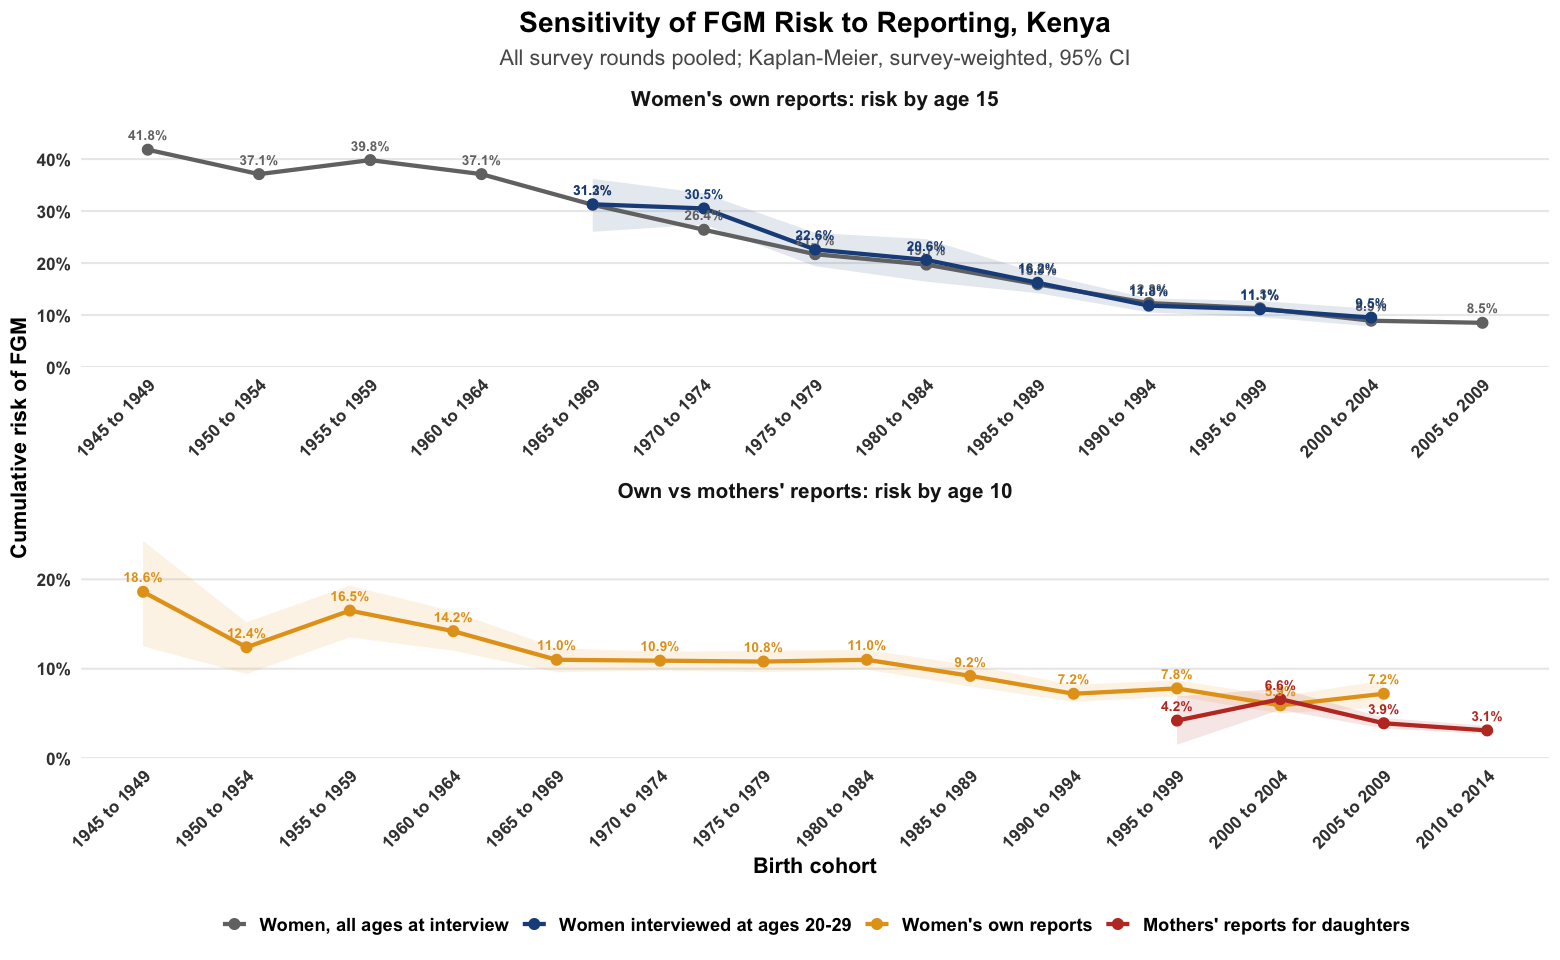

In [27]:
panel_15 <- "Women's own reports: risk by age 15"
panel_10 <- "Own vs mothers' reports: risk by age 10"
sensitivity_plot_data <- dplyr::bind_rows(
  sensitivity_table |> dplyr::transmute(birth_cohort, panel = panel_15, series = "Women, all ages at interview", risk = all_ages / 100),
  sensitivity_table |> dplyr::transmute(birth_cohort, panel = panel_15, series = "Women interviewed at ages 20-29", risk = age_20_29 / 100,
                                        lower = age_20_29_lower / 100, upper = age_20_29_upper / 100),
  sensitivity_table |> dplyr::transmute(birth_cohort, panel = panel_10, series = "Women's own reports", risk = own_by10 / 100,
                                        lower = own_by10_lower / 100, upper = own_by10_upper / 100),
  sensitivity_table |> dplyr::transmute(birth_cohort, panel = panel_10, series = "Mothers' reports for daughters", risk = mothers_reports / 100,
                                        lower = mothers_lower / 100, upper = mothers_upper / 100)
) |> dplyr::filter(!is.na(risk)) |>
  dplyr::mutate(panel = factor(panel, levels = c(panel_15, panel_10)),
                series = factor(series, levels = c("Women, all ages at interview", "Women interviewed at ages 20-29",
                                                   "Women's own reports", "Mothers' reports for daughters")))
series_colours <- c("Women, all ages at interview" = "grey45", "Women interviewed at ages 20-29" = "#1D4E89",
                    "Women's own reports" = "#E5A11C", "Mothers' reports for daughters" = "#C0392B")
sensitivity_plot <- ggplot2::ggplot(sensitivity_plot_data, ggplot2::aes(birth_cohort, risk, color = series, group = series)) +
  ggplot2::geom_ribbon(ggplot2::aes(ymin = lower, ymax = upper, fill = series), alpha = 0.12, color = NA, show.legend = FALSE) +
  ggplot2::geom_line(linewidth = 1.2) + ggplot2::geom_point(size = 2.6) +
  ggplot2::geom_text(ggplot2::aes(label = scales::percent(risk, accuracy = 0.1)), vjust = -1, size = 2.9, fontface = "bold",
                     show.legend = FALSE) +
  ggplot2::facet_wrap(~panel, ncol = 1, scales = "free") +
  ggplot2::scale_color_manual(values = series_colours, name = NULL) +
  ggplot2::scale_fill_manual(values = series_colours, guide = "none") +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, NA),
                              expand = ggplot2::expansion(mult = c(0, 0.15))) +
  ggplot2::labs(title = paste("Sensitivity of FGM Risk to Reporting,", country_name),
                subtitle = "All survey rounds pooled; Kaplan-Meier, survey-weighted, 95% CI",
                x = "Birth cohort", y = "Cumulative risk of FGM") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = 0.5),
                 plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey35"),
                 strip.text = ggplot2::element_text(face = "bold", size = 12.5),
                 axis.title = ggplot2::element_text(face = "bold"),
                 axis.text = ggplot2::element_text(face = "bold", color = "grey25"),
                 axis.text.x = ggplot2::element_text(angle = 45, hjust = 1),
                 panel.grid.minor = ggplot2::element_blank(), panel.grid.major.x = ggplot2::element_blank(),
                 legend.position = "bottom", legend.text = ggplot2::element_text(face = "bold", size = 11))
print(sensitivity_plot)
ggplot2::ggsave(file.path(dirs$sensitivity, paste0(country_iso3, "_sensitivity_risk.png")), sensitivity_plot,
                width = 13, height = 10, dpi = 300, bg = "white")

## 15C. Comparison with Kenya's subnational MICS: age at cutting

MICS 2013–14 asked women their age at cutting in Bungoma, Kakamega and Turkana (MICS4 did not).
FGM is rare in these counties (2–4% of women), so the comparison with DHS 2014 rests on few cut
women and is indicative only. Ages are shown as reported.

In [28]:
source(file.path(project_root, "00_Pipeline", "mics_core.R"))
source(file.path(project_root, "00_Pipeline", "county_core.R"))
options(survey.lonely.psu = "adjust")
pct1 <- function(x) round(100 * x, 1)
harmonized_path <- file.path(project_root, "02_Data", "processed", country_iso3, "harmonized")
h_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_women_all_rounds.rds"))) |>
  dplyr::mutate(fgm_heard = as.numeric(fgm_heard))
mics_women <- readRDS(file.path(harmonized_path, paste0(country_iso3, "_mics_subnational_women.rds")))

mics_out <- file.path(project_root, "03_Outputs", country_iso3, "Risk", "09_MICS_Comparison")
dir.create(mics_out, recursive = TRUE, showWarnings = FALSE)
age_cat <- function(age_report, a) dplyr::case_when(
  age_report %in% c("age 0", "during infancy") | (age_report == "specific age 1+" & a <= 4) ~ "0-4",
  age_report == "specific age 1+" & a <= 9 ~ "5-9", age_report == "specific age 1+" & a <= 14 ~ "10-14",
  age_report == "specific age 1+" ~ "15+", TRUE ~ "Don't know / missing")
mics5 <- mics_surveys |> dplyr::filter(round == "MICS5")
age_rows <- purrr::pmap_dfr(mics5, function(mics_id, folder, year, round, area, level, dhs_compare) dplyr::bind_rows(
  mics_women |> dplyr::filter(source == mics_id, fgm_status == 1) |> dplyr::transmute(comparison = mics_id, source = "MICS 2013-14", weight, age_report, fgm_age),
  dhs_area(h_women, "DHS 2014", area, level) |> dplyr::filter(fgm_status == 1) |>
    dplyr::transmute(comparison = mics_id, source = "DHS 2014", weight, age_report, fgm_age)))
age_table <- age_rows |> dplyr::mutate(age_group = factor(age_cat(age_report, fgm_age), levels = c("0-4", "5-9", "10-14", "15+", "Don't know / missing"))) |>
  dplyr::group_by(comparison, source, age_group) |> dplyr::summarise(w = sum(weight), n = dplyr::n(), .groups = "drop_last") |>
  dplyr::mutate(pct = round(100 * w / sum(w), 1), cut_women = sum(n)) |> dplyr::ungroup() |>
  dplyr::select(comparison, source, cut_women, age_group, pct) |>
  tidyr::pivot_wider(names_from = age_group, values_from = pct, values_fill = 0)
national_ages <- h_women |> dplyr::filter(fgm_status == 1, survey_id %in% c("DHS 2014", "DHS 2022"), !is.na(age_report)) |>
  dplyr::mutate(age_group = age_cat(age_report, fgm_age)) |> dplyr::group_by(survey_id, age_group) |>
  dplyr::summarise(w = sum(weight), .groups = "drop_last") |> dplyr::mutate(pct = round(100 * w / sum(w), 1)) |>
  dplyr::select(-w) |> tidyr::pivot_wider(names_from = age_group, values_from = pct)
readr::write_csv(age_table, file.path(mics_out, paste0(country_iso3, "_mics_age_at_cutting.csv")))
readr::write_csv(national_ages, file.path(mics_out, paste0(country_iso3, "_dhs_national_age_at_cutting.csv")))
IRdisplay::display(as.data.frame(age_table)); IRdisplay::display(as.data.frame(national_ages))

comparison,source,cut_women,5-9,10-14,15+,Don't know / missing,0-4
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MICS 2013-14 Bungoma,DHS 2014,6,9.3,72.1,9.3,9.3,0.0
MICS 2013-14 Bungoma,MICS 2013-14,38,6.3,28.1,60.2,5.4,0.0
MICS 2013-14 Kakamega,DHS 2014,3,40.5,0.0,32.2,27.3,0.0
MICS 2013-14 Kakamega,MICS 2013-14,11,35.5,28.5,30.9,5.1,0.0
MICS 2013-14 Turkana,DHS 2014,13,24.0,24.0,19.0,27.0,6.0
MICS 2013-14 Turkana,MICS 2013-14,31,39.1,25.2,3.2,22.9,9.5


survey_id,0-4,10-14,15+,5-9,Don't know / missing
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DHS 2014,2.3,42.6,26.9,26.6,1.7
DHS 2022,2.4,44.8,21.5,29.6,1.6


## 16. Optional machine learning cross check

Random survival forest on a stratified random sample (up to 4,000 records per round and
reporting source) of histories with an exact age at cutting or no cutting, as a
covariate-screening cross check only.

In [29]:
if (run_ml_crosscheck) {
  suppressPackageStartupMessages(library(randomForestSRC))
  rsf_data <- fgm_events |>
    dplyr::filter(age_share == 1) |>
    dplyr::select(time, fgm_event, urban_rural, region, survey_type, ethnicity, record_type, birth_cohort, survey_id) |>
    tidyr::drop_na() |>
    dplyr::group_by(survey_id, record_type) |> dplyr::slice_sample(n = 4000) |> dplyr::ungroup() |>
    dplyr::select(-survey_id) |>
    dplyr::mutate(dplyr::across(dplyr::where(is.character), as.factor), birth_cohort = droplevels(birth_cohort)) |>
    # Drop predictors with a single value (survey_type is DHS only).
    dplyr::select(dplyr::where(~ dplyr::n_distinct(.x) > 1))
  rsf_model <- randomForestSRC::rfsrc(Surv(time, fgm_event) ~ ., data = as.data.frame(rsf_data), ntree = 300, importance = TRUE)
  print(rsf_model)
  rsf_importance <- sort(rsf_model$importance, decreasing = TRUE)
  readr::write_csv(tibble::enframe(rsf_importance, "variable", "importance"),
                   file.path(dirs$validation, paste0(country_iso3, "_rsf_variable_importance.csv")))
  rsf_importance
}

                         Sample size: 24000
                    Number of deaths: 5069
                     Number of trees: 300
           Forest terminal node size: 15
       Average no. of terminal nodes: 423.8867
No. of variables tried at each split: 3
              Total no. of variables: 5
       Resampling used to grow trees: swor
    Resample size used to grow trees: 15168
                            Analysis: RSF
                              Family: surv
                      Splitting rule: logrank *random*
       Number of random split points: 10
                          (OOB) CRPS: 2.76274193
             (OOB) standardized CRPS: 0.07893548
   (OOB) Requested performance error: 0.1207224



ethnicity       region  record_type birth_cohort  urban_rural 
  0.43763441   0.16082662   0.08273326   0.07064393   0.02985076

## Results

Risk incidence pools **74,656 histories** from four DHS rounds (1998, 2008–09, 2014, 2022): 47,942
women reporting on themselves (13,702 cut) and 26,714 daughters aged 0–14 reported by their
mothers (1,428 cut). DHS 2003 did not ask age at cutting. All risks are survey-weighted
Kaplan–Meier estimates unless stated otherwise.

**1. Cutting happens mainly at ages 5–15.** Only 2–4% of cut women report cutting before age 5;
43–45% report ages 10–14 and 22–32% age 15 or older. In the hazard model, the annual odds of
being cut are 13 times those at ages 0–4 at ages 5–9, 52 times at 10–14 and 19 times at 15 and
older.

**2. Risk has fallen steeply across cohorts.** Women's risk of being cut by age 15 falls from
about 37–42% for women born in 1945–64 to 26.4% (1970–74), 15.9% (1985–89), 11.3% (1995–99)
and 8.5% (2005–09). In the hazard model, the odds of cutting fall steadily from the 1965–69 cohort
(0.68 relative to 1945–49) to 0.30 (1985–89), 0.16 (2000–04) and 0.09 (2010–14). No separate
change point was detected. Mothers report that 3–7% of daughters born since 1995 were cut by
age 10.

**3. Who is at risk.** Relative to Kikuyu, the annual odds of cutting are far higher among
Somali (20.3), Kisii (13.9) and Maasai (8.0) and higher among Kalenjin (2.2); they are very low
among Luo (0.01), Luhya (0.06) and Mijikenda/Swahili (0.22). Urban residence lowers the odds
(0.57). Relative to Central province, they are highest in North Eastern (4.1), Eastern (2.0) and
Nyanza (1.5) and lowest in Western (0.17).

**4. Geography.** North Eastern stands apart: among women born in 2005–09, smoothed risk is 72%
at ages 5–10 and a further 22% at 10–15; in every other province risk at ages 5–15 is under 15%.
Among daughters born in 2010–14, smoothed risk at ages 5–10 is 65% in North Eastern and under 5%
elsewhere.

**5. Validation.** The covariate-adjusted model (12A) agrees with province direct estimates
(correlation 0.87 for women and 0.96 for daughters).

### Sensitivity analysis (section 15B)

Checks on women's own reports use risk by age 15; the comparison with mothers' reports uses
risk by age 10, because daughters are observed only to age 14.

1. **The same cohort gives similar answers in different rounds.** Women born in 1975–79 report a
   risk by age 15 of 23.3% (DHS 1998), 23.4% (2008–09), 22.1% (2014) and 18.4% (2022); women
   born in 1965–69 report 30.8%, 31.6% and 31.5%. Reporting is stable up to DHS 2014; DHS 2022
   gives lower figures for cohorts born before 1985 (e.g. 17.8% against 24.6–30.5% for 1970–74),
   consistent with under-reporting since FGM was criminalised in 2011.
2. **Holding age at interview fixed (20–29),** risk by age 15 falls from 30.5% (1970–74) to 20.6%
   (1980–84), 11.8% (1990–94) and 9.5% (2000–04), the same path as the all-ages series. The
   decline is robust.
3. **Age at interview within cohort** shows no consistent pattern (born 1985–89: 15.5% at 15–24,
   15.7% at 25–34, 17.2% at 35–49).
4. **Women's own reports and mothers' reports** give similar risks by age 10 for girls born in
   2000–04 (5.9% and 6.6%); for 1995–99 mothers report less (4.2% against 7.8%), from a small
   number of older daughters.
5. **DHS vs MICS** is not possible nationally (Kenya has no national MICS); the subnational MICS
   agree with DHS for the same areas (section 15C and the prevalence notebook).
6. **Estimating vague and unknown ages** changes risk by age 15 by under 3 points for every
   cohort, because almost all Kenyan women give an exact age.

**Overall.** FGM in Kenya is mostly a practice of ages 5–15. Risk has fallen steadily for four
decades, from about 40% to under 10% by age 15, and the decline is robust to how and when women
report. Risk remains extremely high in North Eastern province (Somali communities) and is
concentrated among Somali, Kisii and Maasai girls.

## 17. Final outputs

In [30]:
cat("All risk outputs written to:", normalizePath(output_dir), "\n")
tibble::tibble(file = list.files(output_dir, recursive = TRUE))

All risk outputs written to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Final FGM Results/Kenya/V2/03_Outputs/KEN/Risk 


file
<chr>
01_Kaplan_Meier/KEN_kaplan_meier_daughter.png
01_Kaplan_Meier/KEN_kaplan_meier_self.png
01_Kaplan_Meier/KEN_km_risk_by_age.csv
01_Kaplan_Meier/KEN_records_by_cohort_and_round.csv
02_Hazard_Model/KEN_hazard_model_coefficients.csv
02_Hazard_Model/KEN_smoothed_age_effect.png
02_Hazard_Model/KEN_smoothed_cohort_effect.png
03_Direct_and_Smoothed_Estimates/KEN_cohort_age_band_risk_daughter.csv
03_Direct_and_Smoothed_Estimates/KEN_cohort_age_band_risk_self.csv
